# Reproducing every figure: age / gender / demographic analysis of TBe & PBu posts
This notebook regenerates **all 34 figures** from the analysis and answers every sub-question of RQ4 with a figure (map below). Every figure is preceded by a short text block saying *what we get* and *why we did it*:
* **F01–F17** – age and gender analysis (belong/burden prevalence, factor profiles, predictive strength of age, co-occurrence).
* **D01–D06** – other demographics (students, employed, unemployed, partner, parent, mental-health, label-defined context groups).
* **S01–S11** – extra analyses written to answer the remaining sub-questions (association rules, pathways, difficulty load, adjusted model, robustness, …).

### RQ4: "Which psychosocial factors occur together, and which group differences are statistically significant?"
| # | Sub-question | Figure(s) |
|---|---|---|
| **A. Which factors occur together** | | |
| Q1 | Which label pairs co-occur more than chance? | F13, F14, F15 |
| Q2 | Which multi-factor patterns (association rules) are frequent? | S1 |
| Q3 | Do labels form themes / communities? | F13, F14 |
| Q4 | What stressor → emotion → response chains are common? | F15, S2 |
| Q5 | Which factors rarely occur together? | S3 |
| Q6 | Does a higher "load" of difficulties go with belong/burden? | F16, S4 |
| **B. Co-occurrence with TBe and PBu** | | |
| Q7 | Which factors go with thwarted belongingness / perceived burdensomeness? | S5 |
| Q8 | What distinguishes Neither / TBe only / PBu only / Both? | S6 |
| Q9 | How much do TBe and PBu overlap, and does it change with age? | F17 |
| Q10 | How well do the other factors predict belong/burden? | F12 |
| **C. Group differences (age, gender)** | | |
| Q11 | Do belong/burden differ by age group or age? | F3, F4, F17 |
| Q12 | Do factor profiles differ by age group? | F5, F6, F7, F8 |
| Q13 | Is the age effect linear or non-linear? | F4, F7 |
| Q14 | Do belong/burden differ by gender? | F9 |
| Q15 | Do factor profiles differ by gender? | F6, F9 |
| Q16 | Is age a strong predictor? | F11, F12 |
| Q17 | Does the age pattern differ by gender (interaction)? | F10, S7 |
| **D. Other demographic groups** | | |
| Q18 | Do students, employed, unemployed, partnered, parents, mental-health groups differ? | D1–D6 |
| Q19 | Does the co-occurrence structure differ across groups? | D4, S8 |
| Q20 | Which groups matter after adjusting for each other? | D5, S9 |
| **E. Robustness** | | |
| Q21 | Do conclusions hold under other age cut-offs / stricter group definitions? | S10 |
| Q22 | Are writers who disclose demographics representative? | F1, S11 |


## 0. Setup

In [ ]:
import os
import re
import sys
import zlib
import warnings
import pickle
import itertools
import importlib
import subprocess
import glob

# Scientific computing & data structures
import numpy as np
import pandas as pd
import networkx as nx

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Statistical analysis
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from scipy.stats import (
    fisher_exact,
    chi2_contingency,
    kruskal,
    spearmanr,
    chi2
)
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list

# Machine learning, pattern mining & modeling
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from mlxtend.frequent_patterns import apriori, association_rules

# Parallel execution helpers
from joblib import Parallel, delayed

# Globally ignore warning messages
warnings.filterwarnings('ignore')

In [ ]:
# Ensure all required packages are present in the runtime
REQUIRED_PACKAGES = ["mlxtend", "networkx", "statsmodels", "joblib"]

for pkg in REQUIRED_PACKAGES:
    try:
        importlib.import_module(pkg)
    except ImportError:
        print(f"Installing missing package: {pkg}...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

# Execution Configuration
# True = 100 permutations instead of 1000 for the F11 age-prediction null (quicker, noisier)
FAST = False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
OUT_GT, OUT_DEM = "outputs/rq4_gt/figures/", "outputs/dem/figures/"
os.makedirs(OUT_GT, exist_ok=True); os.makedirs(OUT_DEM, exist_ok=True)
up = {}
GT_CSV, ANNOT_CSV = None, None
for name in up:
    if "ground" in name.lower() or "truth" in name.lower(): GT_CSV = name
    elif "annot" in name.lower() or "gender" in name.lower(): ANNOT_CSV = name

GT_CSV = "/content/drive/MyDrive/Research/Dataminds/Easy version - ground_truth.csv"
ANNOT_CSV = "/content/drive/MyDrive/Research/Dataminds/gender_annotations - Annotated-gender-age.csv"
assert GT_CSV and ANNOT_CSV, "Set GT_CSV and ANNOT_CSV (see Option B above)."
print("ground truth:", GT_CSV, "| annotations:", ANNOT_CSV)

ground truth: /content/drive/MyDrive/Research/Dataminds/Easy version - ground_truth.csv | annotations: /content/drive/MyDrive/Research/Dataminds/gender_annotations - Annotated-gender-age.csv


## 1. Helper code
### 1a. Rule-based demographic extractor (age, student, employment, parent, mental health, partner, …)

In [ ]:
# =====================================================================
# Global Configurations & Regex Compilation Flags
# =====================================================================
FLAGS = re.IGNORECASE
HEDGE_BEFORE = re.compile(
    r"\b(?:when|if|until|once|before|after|wish|turn|turning|by the time|will be|gonna be|going to be)\s*(?:i\s*(?:am|'m|will be)?)?\s*$",
    FLAGS
)

# =====================================================================
# Helper Utilities
# =====================================================================
def _norm(text):
    """Standardizes quotes to simplify downstream regular expression matching."""
    return text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')

def _hedged(text, pos):
    """Checks if a mention is hedged (speculative, conditional, or future)."""
    return bool(HEDGE_BEFORE.search(text[max(0, pos - 25):pos]))

def _snip(m, limit=60):
    """Returns matched text, optionally trimmed with an ellipsis."""
    s = m.group(0).strip()
    return s if len(s) <= limit else s[:limit] + "..."

# =====================================================================
# Demography: AGE extraction helpers
# =====================================================================
AGE_UNIT = r"(?:\s*-?\s*(?:years?|yrs?)(?:[- ]old)?|\s*yo\b|\s*y/o\b)"

AGE_A = re.compile(
    r"\bi(?:'m| am|m)\s+(?:currently\s+|only\s+|just\s+|now\s+|a\s+|an\s+)*(\d{1,2})"
    r"(?:(" + AGE_UNIT + r")|(?=\s*(?:[.,;:!?)\]\n]|$|and\b|but\b|so\b|who\b|still\b|never\b|going\b|living\b|struggling\b|"
    r"feeling\b|trying\b|currently\b|male\b|female\b|m\b|f\b|guy\b|girl\b|man\b|woman\b|boy\b)))",
    FLAGS
)

AGE_TURNED = re.compile(r"\bi\s+(?:just\s+)?turned\s+(\d{2})\b", FLAGS)
AGE_START = re.compile(r"(?:^|[.!?\n]\s*)(\d{1,2})\s?(?:yo|y/o|year[- ]old|yr[- ]old)\s*(?:male|female|man|woman|guy|girl|boy|here)", FLAGS)
AGE_BRACKET = re.compile(r"[\(\[]\s*(?:(\d{1,2})\s?[mf]|[mf]\s?(\d{1,2}))\s*[\)\]]", FLAGS)
AGE_DECADE = re.compile(r"\bi(?:'m| am)\s+in\s+my\s+((?:early|mid|late)[- ])?(teens|20s|30s|40s|50s|60s|twenties|thirties|forties|fifties)\b", FLAGS)
AGE_TEEN = re.compile(r"\bi(?:'m| am)\s+(?:just\s+)?a\s+teen(?:ager)?\b", FLAGS)

def age_group(age):
    """Bins raw integer ages into analytical demographics."""
    if age < 18:
        return "under 18"
    elif age <= 24:
        return "18-24"
    elif age <= 34:
        return "25-34"
    elif age <= 44:
        return "35-44"
    else:
        return "45+"

def extract_age(text):
    """Extracts stated numerical age or decade descriptions from text."""
    ages, evidence = [], None
    for rx in (AGE_A, AGE_TURNED, AGE_START, AGE_BRACKET):
        for m in rx.finditer(text):
            val = next((x for x in m.groups() if x and x.isdigit()), None)
            if val and 12 <= int(val) <= 80 and not _hedged(text, m.start()):
                ages.append(int(val))
                evidence = evidence or _snip(m)

    if ages:
        if len(set(ages)) > 1:
            return None, "conflicting ages", f"conflicting ages: {', '.join(map(str, sorted(set(ages))))}"
        return ages[0], age_group(ages[0]), evidence

    m = AGE_DECADE.search(text)
    if m:
        dec = m.group(2).lower()
        dec = {"twenties": "20s", "thirties": "30s", "forties": "40s", "fifties": "50s"}.get(dec, dec)
        label = ((m.group(1) or "").strip(" -") + " " + dec).strip()
        return None, label, _snip(m)

    m = AGE_TEEN.search(text)
    if m:
        return None, "teen", _snip(m)

    return None, None, None

# =====================================================================
# Demography: STUDENT extraction helpers
# =====================================================================
STU_EXPL = re.compile(
    r"\bi(?:'m| am)\s+(?:currently\s+|still\s+|a\s+|an\s+)*(?:(high\s?school|college|university|grad(?:uate)?|masters?|phd|med|law|nursing|undergrad(?:uate)?|first[- ]year|freshman|sophomore|junior|senior)\s+)?student\b",
    FLAGS
)
STU_IN = re.compile(
    r"\bi(?:'m| am)\s+(?:currently\s+|still\s+)?in\s+(?:my\s+\w+\s+(?:year\s+)?of\s+)?(high\s?school|middle\s+school|college|uni|university|(?:grade|year)\s+\d+|\d+(?:st|nd|rd|th)\s+grade)\b|\bi\s+(?:go|went)\s+to\s+(?:high\s+)?(school|college|university|uni)\b",
    FLAGS
)
STU_LIKELY = re.compile(
    r"\bmy\s+(?:school|college|university|uni|classes|exams?|grades|homework|professors?|teachers?|finals|semester|gpa|assignments?|thesis|dissertation|lectures?)\b",
    FLAGS
)

def _level(s):
    s = (s or "").lower()
    if re.search(r"high|middle|grade|year\s+\d", s):
        return "high school"
    if re.search(r"college|uni|grad|master|phd|med|law|nursing|freshman|sophomore|junior|senior|first", s):
        return "college/university"
    return ""

def extract_student(text):
    for rx in (STU_EXPL, STU_IN):
        m = rx.search(text)
        if m:
            lvl = _level(" ".join(g for g in m.groups() if g))
            return (f"student ({lvl})" if lvl else "student"), _snip(m)

    m = STU_LIKELY.search(text)
    if m:
        return "likely student", _snip(m)
    return None, None

# =====================================================================
# Demography: EMPLOYMENT extraction helpers
# =====================================================================
EMP_UN = re.compile(r"\bi(?:'m| am)\s+(?:currently\s+)?(?:unemployed|jobless|out\s+of\s+work)\b|\bi\s+(?:just\s+)?(?:lost\s+my\s+job|got\s+fired|was\s+fired|got\s+laid\s+off|was\s+laid\s+off)\b|\bi\s+(?:don'?t\s+have\s+a\s+job|have\s+no\s+job|can'?t\s+find\s+(?:a\s+)?(?:job|work))\b", FLAGS)
EMP_RET = re.compile(r"\bi(?:'m| am)\s+(?:now\s+)?retired\b", FLAGS)
EMP_EXPL = re.compile(r"\bi\s+work\s+(?:as|at|in|for|full[- ]time|part[- ]time|nights)\b|\bi\s+have\s+a\s+(?:full[- ]time\s+|part[- ]time\s+)?job\b|\bi\s+(?:got|started)\s+a\s+(?:new\s+)?job\b", FLAGS)
EMP_LIKELY = re.compile(r"\bmy\s+(?:job|boss|co-?workers?|manager|workplace|employer|shift|colleagues?)\b", FLAGS)

def extract_employment(text):
    for rx, val in ((EMP_UN, "unemployed / job loss"), (EMP_RET, "retired"), (EMP_EXPL, "employed"), (EMP_LIKELY, "likely employed")):
        m = rx.search(text)
        if m:
            return val, _snip(m)
    return None, None

# =====================================================================
# Demography: PARENT extraction helpers
# =====================================================================
PAR_A = re.compile(r"\bmy\s+(?:\d+\s+|two\s+|three\s+|four\s+|little\s+|young\s+|newborn\s+|infant\s+)?(?:kids?|children|child|toddler|newborn|infant|sons?|daughters?|twins?)\b", FLAGS)
PAR_B = re.compile(r"\bi(?:'m| am)\s+(?:a\s+|an\s+)?(?:(?:single|stay[- ]at[- ]home|young|new|first[- ]time|proud|teen)\s+)?(?:mom|mother|dad|father|parent|mum)\b", FLAGS)
PAR_C = re.compile(r"\bi\s+have\s+(?:a\s+|\d+\s+|two\s+|three\s+|four\s+)(?:kids?|children|child|son|daughter)\b", FLAGS)

def extract_parent(text):
    for rx in (PAR_B, PAR_C, PAR_A):
        m = rx.search(text)
        if m:
            return "parent", _snip(m)
    return None, None

# =====================================================================
# Demography: MENTAL HEALTH extraction helpers
# =====================================================================
COND = {
    "depression": r"(?:major\s+|clinical\s+|severe\s+|chronic\s+)?depression|\bmdd\b",
    "anxiety": r"(?:social\s+|generali[sz]ed\s+|severe\s+)?anxiety(?:\s+disorder)?",
    "bipolar": r"bipolar",
    "ADHD": r"adhd",
    "PTSD": r"c?ptsd",
    "OCD": r"\bocd\b",
    "BPD": r"\bbpd\b|borderline(?:\s+personality\s+disorder)?",
    "autism": r"autis(?:m|tic)|asperger'?s?",
    "schizophrenia": r"schizo\w*",
    "eating disorder": r"anorexia|bulimia|binge[- ]eating(?:\s+disorder)?|eating\s+disorder",
    "panic disorder": r"panic\s+(?:disorder|attacks?)",
    "insomnia": r"insomnia",
}

COND_ALT = "|".join(f"(?P<c{i}>{p})" for i, p in enumerate(COND.values()))
COND_NAMES = list(COND.keys())
DX_RE = re.compile(r"\b(?:i(?:'ve| have)?\s+been|i\s+was|i\s+got|i\s+am|i'm)\s+(?:officially\s+|recently\s+|also\s+|finally\s+)?diagnosed\s+(?:with|as\s+having)\s+([^.!?\n]{0,70})", FLAGS)

SELF_RES = [
    re.compile(r"\bi\s+(?:have|suffer\s+from|struggle\s+with|deal\s+with|live\s+with)\s+(?:\w+\s+){0,2}?(" + COND_ALT + ")", FLAGS),
    re.compile(r"\bmy\s+(?:\w+\s+)?(" + COND_ALT + ")", FLAGS),
    re.compile(r"\bi(?:'m| am)\s+(?:an?\s+)?(autistic|bipolar)\b", FLAGS),
]

def _conds_in(s):
    out = []
    for m in re.finditer(COND_ALT, s, FLAGS):
        name = COND_NAMES[int(m.lastgroup[1:])]
        if name not in out:
            out.append(name)
    return out

def extract_mh(text):
    found, evidence = {}, None
    for m in DX_RE.finditer(text):
        for c in _conds_in(m.group(1)):
            found[c] = "diagnosed"
            evidence = evidence or _snip(m, 80)

    for rx in SELF_RES:
        for m in rx.finditer(text):
            if rx is not SELF_RES[2]:
                matched_conditions = _conds_in(m.group(0))
            else:
                matched_conditions = ["autism" if "autis" in m.group(1).lower() else "bipolar"]
            for c in matched_conditions:
                found.setdefault(c, "self-reported")
                evidence = evidence or _snip(m)

    if not found:
        return None, None
    return "; ".join(f"{c} ({k})" for c, k in found.items()), evidence

# =====================================================================
# Demography: GEOGRAPHY extraction helpers
# =====================================================================
COUNTRIES = {
    "united states": "United States", "usa": "United States", "america": "United States", "the states": "United States",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "england": "United Kingdom", "scotland": "United Kingdom",
    "wales": "United Kingdom", "britain": "United Kingdom", "northern ireland": "United Kingdom",
    "canada": "Canada", "australia": "Australia", "new zealand": "New Zealand", "ireland": "Ireland", "india": "India",
    "germany": "Germany", "france": "France", "italy": "Italy", "spain": "Spain", "portugal": "Portugal", "netherlands": "Netherlands",
    "belgium": "Belgium", "sweden": "Sweden", "norway": "Norway", "denmark": "Denmark", "finland": "Finland", "poland": "Poland",
    "russia": "Russia", "ukraine": "Ukraine", "turkey": "Turkey", "greece": "Greece", "romania": "Romania", "switzerland": "Switzerland",
    "austria": "Austria", "mexico": "Mexico", "brazil": "Brazil", "argentina": "Argentina", "chile": "Chile", "colombia": "Colombia",
    "china": "China", "japan": "Japan", "korea": "South Korea", "south korea": "South Korea", "singapore": "Singapore",
    "malaysia": "Malaysia", "indonesia": "Indonesia", "philippines": "Philippines", "pakistan": "Pakistan", "bangladesh": "Bangladesh",
    "sri lanka": "Sri Lanka", "nepal": "Nepal", "israel": "Israel", "egypt": "Egypt", "saudi arabia": "Saudi Arabia", "uae": "UAE",
    "iran": "Iran", "nigeria": "Nigeria", "south africa": "South Africa", "kenya": "Kenya", "ghana": "Ghana",
}

STATE_LIST = [
    "alabama", "alaska", "arizona", "arkansas", "california", "colorado", "connecticut", "delaware", "florida", "hawaii",
    "idaho", "illinois", "indiana", "iowa", "kansas", "kentucky", "louisiana", "maine", "maryland", "massachusetts",
    "michigan", "minnesota", "mississippi", "missouri", "montana", "nebraska", "nevada", "new hampshire", "new jersey",
    "new mexico", "new york", "north carolina", "north dakota", "ohio", "oklahoma", "oregon", "pennsylvania",
    "rhode island", "south carolina", "south dakota", "tennessee", "texas", "utah", "vermont", "virginia",
    "west virginia", "wisconsin", "wyoming"
]

DEMONYMS = {
    "american": "United States", "british": "United Kingdom", "canadian": "Canada", "australian": "Australia", "indian": "India",
    "german": "Germany", "french": "France", "italian": "Italy", "spanish": "Spain", "mexican": "Mexico", "brazilian": "Brazil",
    "chinese": "China", "japanese": "Japan", "korean": "South Korea", "russian": "Russia", "polish": "Poland", "dutch": "Netherlands",
    "swedish": "Sweden", "norwegian": "Norway", "irish": "Ireland", "scottish": "United Kingdom", "welsh": "United Kingdom",
    "filipino": "Philippines", "pakistani": "Pakistan", "nigerian": "Nigeria", "egyptian": "Egypt", "turkish": "Turkey",
    "iranian": "Iran", "israeli": "Israel", "south african": "South Africa", "new zealander": "New Zealand", "kiwi": "New Zealand",
}

PLACE_ALT = "|".join(sorted(map(re.escape, list(COUNTRIES) + STATE_LIST), key=len, reverse=True))
PLACE_INTRO = re.compile(
    r"\b(?:i(?:'m| am)\s+from|i\s+(?:live|living|grew\s+up|was\s+born|reside|moved)\s+(?:in|to)|i(?:'m| am)\s+(?:currently\s+)?(?:living\s+)?(?:here\s+)?in|here\s+in)\s+(?:the\s+)?(" + PLACE_ALT + r")\b",
    FLAGS
)
DEMO_RE = re.compile(r"\bi(?:'m| am)\s+(?:an?\s+)?(" + "|".join(sorted(map(re.escape, DEMONYMS), key=len, reverse=True)) + r")\b(?!\s+(?:shepherd|dressing|toast))", FLAGS)

def extract_country(text):
    for m in PLACE_INTRO.finditer(text):
        key = m.group(1).lower()
        if key == "uk" and m.group(1) != "UK":
            continue
        if key == "uae" and m.group(1) != "UAE":
            continue
        if key in COUNTRIES:
            return COUNTRIES[key], _snip(m)
        return "United States", _snip(m) # Matched US State

    m = DEMO_RE.search(text)
    if m:
        return DEMONYMS[m.group(1).lower()], _snip(m)
    return None, None

# =====================================================================
# Demography: RELATIONSHIP extraction helpers
# =====================================================================
REL_EXPL = re.compile(r"\bi(?:'m| am)\s+(?:currently\s+|now\s+|still\s+|recently\s+)?(single|married|divorced|separated|widowed|engaged)\b", FLAGS)
REL_SPOUSE = re.compile(r"\bmy\s+(?:wife|husband|fianc[eé]e?)\b", FLAGS)
REL_PARTNER = re.compile(r"\bmy\s+(?:girlfriend|boyfriend|partner)\b", FLAGS)

def extract_relationship(text):
    m = REL_EXPL.search(text)
    if m and not _hedged(text, m.start()):
        return m.group(1).lower(), _snip(m)

    m = REL_SPOUSE.search(text)
    if m:
        return "married/engaged (mentioned spouse)", _snip(m)

    m = REL_PARTNER.search(text)
    if m:
        return "in a relationship (mentioned partner)", _snip(m)
    return None, None

# =====================================================================
# Demography: ORIENTATION extraction helpers
# =====================================================================
ORI_WORDS = {
    "gay": "gay", "lesbian": "lesbian", "bi": "bisexual", "bisexual": "bisexual", "pansexual": "pansexual",
    "asexual": "asexual", "straight": "straight", "queer": "queer", "homosexual": "gay", "heterosexual": "straight",
    "demisexual": "demisexual"
}
ORI_RE = re.compile(
    r"\bi(?:'m| am|\s+identify\s+as|\s+consider\s+myself)\s+(?:a\s+|an\s+)?(?:(?:also|really|openly|totally|kinda|mostly|completely|actually)\s+)?("
    + "|".join(ORI_WORDS) + r")(?![\w-])(?!\s+(?:up|forward|edge|away|out|as\s+an\s+arrow))",
    FLAGS
)
ORI_CAME = re.compile(r"\bcame\s+out\s+(?:to\s+\w+(?:\s+\w+)?\s+)?as\s+(gay|lesbian|bi|bisexual|pansexual|asexual|queer)(?![\w-])", FLAGS)
UNSURE = re.compile(r"\b(?:think|thinks|maybe|might|wonder|wondering|questioning|not\s+sure|unsure|afraid)\b[^.!?\n]{0,20}$", FLAGS)

def extract_orientation(text):
    for rx in (ORI_RE, ORI_CAME):
        for m in rx.finditer(text):
            if _hedged(text, m.start()):
                continue
            val = ORI_WORDS[m.group(1).lower()]
            if UNSURE.search(text[max(0, m.start() - 40):m.start()]):
                val += " (uncertain)"
            return val, _snip(m)
    return None, None

# =====================================================================
# Demography: RELIGION extraction helpers
# =====================================================================
REL_WORDS = r"christian|muslim|atheist|agnostic|catholic|jewish|hindu|buddhist|mormon|sikh|orthodox|protestant|religious"
RELIG_RE = re.compile(r"\bi(?:'m| am| was\s+raised| grew\s+up)\s+(?:a\s+|an\s+)?(?:very\s+|devout\s+|strict\s+|practicing\s+|non-practicing\s+)?(" + REL_WORDS + ")\b", FLAGS)

def extract_religion(text):
    m = RELIG_RE.search(text)
    if m and not _hedged(text, m.start()):
        return m.group(1).lower(), _snip(m)
    return None, None

# =====================================================================
# Demography: RACE extraction helpers
# =====================================================================
RACE_RE = re.compile(
    r"\bi(?:'m| am)\s+(?:a\s+|an\s+)?(?:half[- ]|part[- ]|mixed[- ])?(black|white|asian|hispanic|latino|latina|latinx|arab|african[- ]american|native\s+american|biracial|multiracial|south\s+asian|east\s+asian|middle\s+eastern|pacific\s+islander|caucasian)\b(?!\s+(?:as|with|and\s+blue|knuckle|noise|lie|lies|belt))",
    FLAGS
)

def extract_race(text):
    m = RACE_RE.search(text)
    if m and not _hedged(text, m.start()):
        return m.group(1).lower(), _snip(m)
    return None, None

# =====================================================================
# Demography: LIVING STATUS extraction helpers
# =====================================================================
LIVE_WITH = re.compile(r"\bi\s+(?:still\s+|currently\s+)?live\s+(?:at\s+home\s+)?with\s+my\s+(parents?|mom|mum|mother|dad|father|family|grandparents?|grandma|grandmother|grandfather|grandpa|roommates?|boyfriend|girlfriend|partner|wife|husband|brother|sister|aunt|uncle|in-laws|friends?)\b", FLAGS)
LIVE_ALONE = re.compile(r"\bi(?:'m| am)?\s*(?:currently\s+)?(?:live|living)\s+(?:all\s+)?(?:alone|by\s+myself|on\s+my\s+own)\b", FLAGS)
LIVE_HOME = re.compile(r"\bi\s+(?:still\s+)?live\s+at\s+home\b|\bi\s+(?:moved|am\s+moving|'m\s+moving)\s+back\s+(?:in\s+)?(?:with|home)", FLAGS)
LIVE_DORM = re.compile(r"\bmy\s+dorm\b|\bi\s+live\s+in\s+a\s+dorm\b", FLAGS)
LIVE_HOMELESS = re.compile(r"\bi(?:'m| am)\s+homeless\b|\bi\s+live\s+in\s+my\s+car\b|\bi\s+(?:lost|am\s+losing)\s+my\s+(?:home|apartment|house)\b", FLAGS)
PARTNER_W = {"boyfriend", "girlfriend", "partner", "wife", "husband"}
ROOM_W = {"roommate", "roommates", "friend", "friends"}

def extract_living(text):
    vals, evs = [], []
    m = LIVE_WITH.search(text)
    if m:
        w = m.group(1).lower()
        vals.append("with partner/spouse" if w in PARTNER_W else "with roommates/friends" if w in ROOM_W else "with parents/family")
        evs.append(_snip(m))

    for rx, v in ((LIVE_ALONE, "alone"), (LIVE_HOME, "with parents/family"), (LIVE_DORM, "dorm/campus"), (LIVE_HOMELESS, "homeless/unstable housing")):
        m = rx.search(text)
        if m and v not in vals:
            vals.append(v)
            evs.append(_snip(m))

    return ("; ".join(vals) if vals else None), ("; ".join(evs) if evs else None)

# =====================================================================
# Demography: MAIN pipeline entrypoint
# =====================================================================
DEMO_COLUMNS = [
    "age", "age_group", "student_status", "employment_status", "parent_status", "mental_health_conditions",
    "country_region", "relationship_status", "sexual_orientation", "religion", "race_ethnicity", "living_situation"
]

def extract_demographics(raw):
    """Extracts demographical attributes and evidence strings from raw text."""
    out = {c: None for c in DEMO_COLUMNS}
    if not isinstance(raw, str) or not raw.strip():
        return out, ""

    t = _norm(raw)
    ev = []

    age, grp, e = extract_age(t)
    if grp:
        out["age"], out["age_group"] = age, grp
        ev.append(f'age: "{e}"')

    for col, fn in (("student_status", extract_student), ("employment_status", extract_employment), ("parent_status", extract_parent),
                    ("mental_health_conditions", extract_mh), ("country_region", extract_country), ("relationship_status", extract_relationship),
                    ("sexual_orientation", extract_orientation), ("religion", extract_religion), ("race_ethnicity", extract_race),
                    ("living_situation", extract_living)):
        val, e = fn(t)
        if val:
            out[col] = val
            ev.append(f'{col}: "{e}"')

    return out, "\n".join(ev)


### 1b. Data loading: label matrix (one 0/1 column per label) + manual age/gender

In [ ]:
# =====================================================================
# Global Category Config
# =====================================================================
CATEGORIES = ["stressors", "relationships", "emotions", "responses"]

# =====================================================================
# Helper Utilities & Matrix Building Pipeline
# =====================================================================
def split_labels(cell_content):
    """Parses semicolon-separated label structures into unique lowercased elements."""
    if pd.isna(cell_content) or not str(cell_content).strip():
        return []
    return [label.strip().lower() for label in str(cell_content).split(";") if label.strip()]


def build_matrix(labels_df):
    """Constructs a 1-hot/binary label matrix from structural label sets.

    Each unique label becomes a column prefixed with its parent category
    (e.g., 'stressor: work').
    """
    binary_df = pd.DataFrame(index=labels_df.index)

    # Preserve main target outcomes
    binary_df["belong"] = labels_df["belong"].astype(int)
    binary_df["burden"] = labels_df["burden"].astype(int)

    category_mappings = {
        "belong": "belong/burden",
        "burden": "belong/burden"
    }

    # Generate columns for categorical features dynamically
    for category in CATEGORIES:
        label_sets = labels_df[category].map(split_labels)
        unique_labels = sorted({label for labels in label_sets for label in labels})

        for label in unique_labels:
            column_prefix = category[:-1] if category.endswith("s") else category
            feature_name = f"{column_prefix}: {label}"

            binary_df[feature_name] = label_sets.map(lambda labels: int(label in labels))
            category_mappings[feature_name] = category

    return binary_df, category_mappings


def age_bin(age_value):
    """Slices numerical ages into primary analytic age bins."""
    if pd.isna(age_value):
        return np.nan
    if age_value < 18:
        return "under 18"
    elif age_value < 25:
        return "18-24"
    else:
        return "25+"


def load_gt():
    """Loads, merges, and builds matrices from ground truth and manual annotations."""
    ground_truth = pd.read_csv(GT_CSV)
    annotations = pd.read_csv(ANNOT_CSV)

    # Standardize gender annotations
    annotations["gender"] = annotations["gender"].astype(str).str.strip().str.capitalize()
    annotations["age_num"] = pd.to_numeric(annotations["age"], errors="coerce")

    # Merge metadata securely onto label datasets
    merged_df = ground_truth.merge(
        annotations[["post_id", "gender", "age_num"]],
        on="post_id",
        how="left",
        validate="1:1"
    )

    # Create secondary demographic groupings
    merged_df["age_bin"] = merged_df["age_num"].map(age_bin)
    merged_df["gender_known"] = merged_df["gender"].where(merged_df["gender"].isin(["Male", "Female", "Trans"]))

    label_matrix, category_mappings = build_matrix(merged_df)
    return merged_df, label_matrix, category_mappings

# =====================================================================
# Execution & Verification Pipeline
# =====================================================================
d, X, cat_of = load_gt()

print(f"Post metadata shape:   {d.shape}")
print(f"Binary label matrix:   {X.shape}")
print(f"Stated ages identified: {d.age_num.notna().sum()}")
print(f"Stated gender splits:   {d.gender_known.value_counts().to_dict()}")

(3522, 49) | binary label matrix: (3522, 32) | age known: 344 | gender: {'Male': 61, 'Female': 27, 'Trans': 4}


### 1c. Co-occurrence mining (pairwise tests, Apriori rules, label clustering)

In [ ]:
# =====================================================================
# 1. Pairwise Association Mining
# =====================================================================
def pairwise(X, cat_of, min_count=5):
    """Performs pairwise Fisher exact association tests between label columns.

    Computes Odds Ratios, Jaccard Index, Phi Correlation coefficients,
    and adjusts p-values using the False Discovery Rate (FDR).
    """
    total_samples = len(X)
    valid_columns = [col for col in X.columns if X[col].sum() >= min_count]
    records = []

    for col_a, col_b in itertools.combinations(valid_columns, 2):
        series_a = X[col_a].values
        series_b = X[col_b].values

        # Construct 2x2 contingency matrix variables
        count_11 = int((series_a & series_b).sum())
        count_10 = int(series_a.sum() - count_11)
        count_01 = int(series_b.sum() - count_11)
        count_00 = total_samples - count_11 - count_10 - count_01

        # Compute phi correlation coefficient safely
        phi_denominator = np.sqrt(
            (count_11 + count_10) *
            (count_01 + count_00) *
            (count_11 + count_01) *
            (count_10 + count_00)
        )
        phi = (count_11 * count_00 - count_10 * count_01) / phi_denominator if phi_denominator else np.nan

        expected_both = (count_11 + count_10) * (count_11 + count_01) / total_samples
        _, p_fisher = fisher_exact([[count_11, count_10], [count_01, count_00]])

        # Haldane-corrected OR and Standard Error CI estimation
        a_adj, b_adj, c_adj, d_adj = count_11 + 0.5, count_10 + 0.5, count_01 + 0.5, count_00 + 0.5
        log_odds_ratio = np.log(a_adj * d_adj / (b_adj * c_adj))
        standard_error = np.sqrt(1 / a_adj + 1 / b_adj + 1 / c_adj + 1 / d_adj)

        records.append({
            "item_a": col_a,
            "item_b": col_b,
            "cat_a": cat_of[col_a],
            "cat_b": cat_of[col_b],
            "n_a": int(series_a.sum()),
            "n_b": int(series_b.sum()),
            "n_both": count_11,
            "expected_both": round(expected_both, 1),
            "lift": count_11 / expected_both if expected_both else np.nan,
            "jaccard": count_11 / (count_11 + count_10 + count_01) if (count_11 + count_10 + count_01) else np.nan,
            "phi": phi,
            "odds_ratio": np.exp(log_odds_ratio),
            "or_ci_low": np.exp(log_odds_ratio - 1.96 * standard_error),
            "or_ci_high": np.exp(log_odds_ratio + 1.96 * standard_error),
            "p_fisher": p_fisher
        })

    pairwise_df = pd.DataFrame(records)
    if not pairwise_df.empty:
        pairwise_df["q_fdr"] = multipletests(pairwise_df["p_fisher"], method="fdr_bh")[1]
        pairwise_df["significant_q05"] = pairwise_df["q_fdr"] < 0.05
        pairwise_df["direction"] = np.where(pairwise_df["phi"] > 0, "co-occur", "avoid")
        pairwise_df["same_category"] = pairwise_df["cat_a"] == pairwise_df["cat_b"]

    return pairwise_df.sort_values("p_fisher").reset_index(drop=True)

# =====================================================================
# 2. Frequent Pattern & Association Rules Mining
# =====================================================================
def rules(X, min_support=0.04, min_conf=0.5, min_lift=1.2, max_len=3):
    """Mines multi-factor association rules using the Apriori algorithm.

    Filters results based on support, confidence, and lift thresholds.
    """
    frequent_itemsets = apriori(
        X.astype(bool),
        min_support=min_support,
        use_colnames=True,
        max_len=max_len
    )

    assoc_rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=min_conf)
    filtered_rules = assoc_rules[assoc_rules["lift"] >= min_lift].copy()

    if not filtered_rules.empty:
        filtered_rules["antecedent_n"] = filtered_rules["antecedents"].map(len)
        filtered_rules["antecedents"] = filtered_rules["antecedents"].map(lambda s: " + ".join(sorted(s)))
        filtered_rules["consequents"] = filtered_rules["consequents"].map(lambda s: " + ".join(sorted(s)))

        columns_to_keep = [
            "antecedents", "consequents", "support", "confidence",
            "lift", "leverage", "conviction", "antecedent_n"
        ]
        filtered_rules = filtered_rules[columns_to_keep]

    return (
        filtered_rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True),
        frequent_itemsets
    )

# =====================================================================
# 3. Label Theme Clustering
# =====================================================================
def label_clusters(X, k_range=range(2, 8), min_count=20):
    """Clusters variables hierarchically based on pairwise Jaccard distance."""
    valid_cols = [col for col in X.columns if X[col].sum() >= min_count]
    matrix_values = X[valid_cols].values.astype(bool)

    # Calculate raw intersections & unions efficiently
    intersections = matrix_values.T.astype(int) @ matrix_values.astype(int)
    sums = matrix_values.sum(axis=0)
    unions = sums[:, None] + sums[None, :] - intersections

    # Construct distance matrix
    jaccard_distances = 1 - intersections / unions
    np.fill_diagonal(jaccard_distances, 0)

    linkage_tree = linkage(squareform(jaccard_distances, checks=False), method="average")
    ordered_indices = leaves_list(linkage_tree)
    ordered_labels = [valid_cols[idx] for idx in ordered_indices]

    return valid_cols, jaccard_distances, linkage_tree, ordered_labels

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 1d. Group-difference helpers (Cramér's V, fast permutation chi-square)

In [ ]:
RNG = np.random.default_rng(42)

# =====================================================================
# 1. Basic Statistical Association Metric Helpers
# =====================================================================
def cramers_v(contingency_table):
    """Calculates Cramr's V association strength coefficient for a contingency table."""
    chi2_stat = chi2_contingency(contingency_table, correction=False)[0]
    total_sum = contingency_table.sum()
    min_dimension = min(contingency_table.shape) - 1
    return np.sqrt(chi2_stat / (total_sum * min_dimension)) if min_dimension > 0 else 0.0


def perm_chi2_p(y_binary, group_labels, n_permutations=5000):
    """Computes Monte-Carlo p-values for a 2xk chi-square test via numpy permutations."""
    y_values = np.asarray(y_binary, dtype=float)
    group_codes, unique_groups = pd.factorize(np.asarray(group_labels))
    num_groups = len(unique_groups)

    group_counts = np.bincount(group_codes, minlength=num_groups).astype(float)
    total_samples = group_counts.sum()

    def calculate_chi2_statistic(y_perm):
        positives_by_group = np.bincount(group_codes, weights=y_perm, minlength=num_groups)
        total_positives = positives_by_group.sum()

        expected_positives = group_counts * total_positives / total_samples
        expected_negatives = group_counts * (total_samples - total_positives) / total_samples

        observed_negatives = group_counts - positives_by_group

        chi2_pos = ((positives_by_group - expected_positives) ** 2) / expected_positives
        chi2_neg = ((observed_negatives - expected_negatives) ** 2) / expected_negatives
        return (chi2_pos + chi2_neg).sum()

    observed_statistic = calculate_chi2_statistic(y_values)
    extreme_count = 0

    for _ in range(n_permutations):
        permuted_y = RNG.permutation(y_values)
        if calculate_chi2_statistic(permuted_y) >= observed_statistic - 1e-12:
            extreme_count += 1

    return (extreme_count + 1) / (n_permutations + 1)


def label_cols(X, subset_mask, min_positive=5, min_negative=5):
    """Filters columns based on minimum required positive and negative counts in a subset."""
    subset_df = X[subset_mask]
    return [
        col for col in X.columns
        if subset_df[col].sum() >= min_positive
        and (len(subset_df) - subset_df[col].sum()) >= min_negative
    ]

# =====================================================================
# 2. Age-Specific Testing Pipelines
# =====================================================================
def age_tests(d, X, n_permutations=5000):
    """Runs omnibus permutations and logistic regression across age demographics."""
    has_age_mask = d["age_bin"].notna()
    valid_d = d[has_age_mask]
    valid_X = X[has_age_mask]

    age_group_order = ["under 18", "18-24", "25+"]
    records = []

    for col in label_cols(X, has_age_mask, min_positive=10):
        y_values = valid_X[col].values
        group_labels = valid_d["age_bin"].values

        contingency_tab = pd.crosstab(group_labels, y_values).reindex(
            index=age_group_order,
            columns=[0, 1],
            fill_value=0
        )

        prevalence_by_group = {
            group: 100.0 * y_values[group_labels == group].mean()
            for group in age_group_order
        }

        p_omnibus = perm_chi2_p(y_values, group_labels, n_permutations)
        cv_coefficient = cramers_v(contingency_tab.values)

        # Logistic regression on numerical age scaled by 5 years
        scaled_numerical_age = valid_d["age_num"].values / 5.0
        try:
            logit_model = sm.Logit(y_values, sm.add_constant(scaled_numerical_age)).fit(disp=0)
            odds_ratio = np.exp(logit_model.params[1])
            ci_lower, ci_upper = np.exp(logit_model.conf_int()[1])
            p_logistic = logit_model.pvalues[1]
        except Exception:
            odds_ratio = ci_lower = ci_upper = p_logistic = np.nan

        records.append({
            "label": col,
            "n": len(valid_d),
            "n_positive": int(y_values.sum()),
            "pct_under18": prevalence_by_group["under 18"],
            "pct_18_24": prevalence_by_group["18-24"],
            "pct_25plus": prevalence_by_group["25+"],
            "max_gap_pts": max(prevalence_by_group.values()) - min(prevalence_by_group.values()),
            "cramers_v": cv_coefficient,
            "p_omnibus": p_omnibus,
            "or_per_5yr": odds_ratio,
            "or_ci_low": ci_lower,
            "or_ci_high": ci_upper,
            "p_logistic": p_logistic
        })

    results_df = pd.DataFrame(records)
    if not results_df.empty:
        results_df["q_omnibus"] = multipletests(results_df["p_omnibus"], method="fdr_bh")[1]
        results_df["q_logistic"] = multipletests(results_df["p_logistic"].fillna(1.0), method="fdr_bh")[1]

    return results_df.sort_values("p_omnibus").reset_index(drop=True), contingency_tab


def age_posthoc(d, X, labels):
    """Runs post-hoc pairwise Fisher exact comparisons on targeted age bins."""
    has_age_mask = d["age_bin"].notna()
    valid_d = d[has_age_mask]
    valid_X = X[has_age_mask]
    records = []

    for col in labels:
        comparisons = [("under 18", "18-24"), ("under 18", "25+"), ("18-24", "25+")]
        for group_a, group_b in comparisons:
            y_a = valid_X[col][valid_d["age_bin"] == group_a]
            y_b = valid_X[col][valid_d["age_bin"] == group_b]

            contingency_matrix = [
                [y_a.sum(), len(y_a) - y_a.sum()],
                [y_b.sum(), len(y_b) - y_b.sum()]
            ]
            _, p_fisher = fisher_exact(contingency_matrix)

            records.append({
                "label": col,
                "group_a": group_a,
                "group_b": group_b,
                "pct_a": 100.0 * y_a.mean(),
                "pct_b": 100.0 * y_b.mean(),
                "p_fisher": p_fisher
            })

    results_df = pd.DataFrame(records)
    if not results_df.empty:
        results_df["q_fdr"] = multipletests(results_df["p_fisher"], method="fdr_bh")[1]
    return results_df

# =====================================================================
# 3. Gender & Outcome Demographics Pipelines
# =====================================================================
def gender_tests(d, X):
    """Evaluates label distributions between designated Male and Female samples."""
    is_m_or_f_mask = d["gender_known"].isin(["Male", "Female"])
    valid_d = d[is_m_or_f_mask]
    valid_X = X[is_m_or_f_mask]
    records = []

    for col in label_cols(X, is_m_or_f_mask, min_positive=5):
        y_male = valid_X[col][valid_d["gender_known"] == "Male"]
        y_female = valid_X[col][valid_d["gender_known"] == "Female"]

        contingency_matrix = [
            [y_male.sum(), len(y_male) - y_male.sum()],
            [y_female.sum(), len(y_female) - y_female.sum()]
        ]
        _, p_fisher = fisher_exact(contingency_matrix)

        # Haldane correction for risk and CI bounds calculation
        a_adj = y_male.sum() + 0.5
        b_adj = len(y_male) - y_male.sum() + 0.5
        c_adj = y_female.sum() + 0.5
        d_adj = len(y_female) - y_female.sum() + 0.5

        log_odds_ratio = np.log(a_adj * d_adj / (b_adj * c_adj))
        standard_error = np.sqrt(1 / a_adj + 1 / b_adj + 1 / c_adj + 1 / d_adj)

        records.append({
            "label": col,
            "n_male": len(y_male),
            "n_female": len(y_female),
            "pct_male": 100.0 * y_male.mean(),
            "pct_female": 100.0 * y_female.mean(),
            "diff_pts": 100.0 * (y_male.mean() - y_female.mean()),
            "odds_ratio_M_vs_F": np.exp(log_odds_ratio),
            "or_ci_low": np.exp(log_odds_ratio - 1.96 * standard_error),
            "or_ci_high": np.exp(log_odds_ratio + 1.96 * standard_error),
            "p_fisher": p_fisher
        })

    columns = [
        "label", "n_male", "n_female", "pct_male", "pct_female",
        "diff_pts", "odds_ratio_M_vs_F", "or_ci_low", "or_ci_high", "p_fisher"
    ]
    results_df = pd.DataFrame(records, columns=columns)
    if results_df.empty:
        results_df["q_fdr"] = []
        return results_df

    results_df["q_fdr"] = multipletests(results_df["p_fisher"], method="fdr_bh")[1]
    return results_df.sort_values("p_fisher").reset_index(drop=True)


def min_detectable_diff(n_group1, n_group2, baseline_prop=0.4, statistical_power=0.8, significance_alpha=0.05):
    """Finds the minimum detectable population rate difference between sample sizes."""
    sample_ratio = n_group2 / n_group1
    power_solver = NormalIndPower()

    effect_size_h = power_solver.solve_power(
        nobs1=n_group1,
        alpha=significance_alpha,
        power=statistical_power,
        ratio=sample_ratio
    )
    # Map back from Cohen's h metric around specified baseline
    phi_baseline = 2 * np.arcsin(np.sqrt(baseline_prop))
    target_proportion = np.sin((phi_baseline + effect_size_h) / 2) ** 2
    return target_proportion - baseline_prop


def group_tests(d, X, skip_factors=("belong", "burden")):
    """Applies omnibus chi-square analysis tests on psychosocial outcomes against 4-way groups."""
    target_groups = d["group"]
    records = []

    for col in X.columns:
        if col in skip_factors or X[col].sum() < 10:
            continue

        contingency_tab = pd.crosstab(target_groups, X[col]).reindex(columns=[0, 1], fill_value=0)
        chi2_val, p_val, degrees_of_freedom, _ = chi2_contingency(contingency_tab.values, correction=False)

        entry = {
            "label": col,
            "chi2": chi2_val,
            "dof": degrees_of_freedom,
            "p_chi2": p_val,
            "cramers_v": cramers_v(contingency_tab.values)
        }

        for group_name in ["Neither", "TBe only", "PBu only", "Both"]:
            entry[f"pct_{group_name}"] = 100.0 * X.loc[target_groups == group_name, col].mean()

        records.append(entry)

    results_df = pd.DataFrame(records)
    if not results_df.empty:
        results_df["q_fdr"] = multipletests(results_df["p_chi2"], method="fdr_bh")[1]

    return results_df.sort_values("p_chi2").reset_index(drop=True)


def tbe_pbu_effects(d, X):
    """Determines directional TBe / PBu Odds Ratios across standard descriptors."""
    records = []
    for target_outcome in ("belong", "burden"):
        for col in X.columns:
            if col in ("belong", "burden") or X[col].sum() < 10:
                continue

            cross_tab = pd.crosstab(X[col], X[target_outcome]).reindex(
                index=[0, 1],
                columns=[0, 1],
                fill_value=0
            ).values

            _, p_fisher = fisher_exact([
                [cross_tab[1, 1], cross_tab[1, 0]],
                [cross_tab[0, 1], cross_tab[0, 0]]
            ])

            records.append({
                "outcome": target_outcome,
                "factor": col,
                "pct_outcome_if_present": 100.0 * cross_tab[1, 1] / cross_tab[1].sum(),
                "pct_outcome_if_absent": 100.0 * cross_tab[0, 1] / cross_tab[0].sum(),
                "odds_ratio": fisher_exact(cross_tab)[0],
                "p_fisher": p_fisher
            })

    results_df = pd.DataFrame(records)
    if not results_df.empty:
        results_df["q_fdr"] = results_df.groupby("outcome")["p_fisher"].transform(
            lambda p_series: multipletests(p_series, method="fdr_bh")[1]
        )
    return results_df

## 2. Main analysis (age & gender) – statistics behind F01–F17
Group tests, factor profiles by age group / numeric age / gender, age-only predictive strength, PERMANOVA, benchmarks, co-occurrence.

In [ ]:
# =====================================================================
# 1. Configuration & Global Setup
# =====================================================================
RNG = np.random.default_rng(7)
AGE_ORDER = ["under 18", "18-24", "25+"]
CATEGORIES = ["stressor", "relationship", "emotion", "response"]
ALL_FACTORS = [col for col in X.columns if col not in ("belong", "burden")]
ANALYSIS_REGISTRY = {}

# =====================================================================
# 2. Helpers for Confidence Intervals & Model Evaluation
# =====================================================================
def calculate_wilson_ci_percent(positives, total):
    """Calculates Wilson score interval bounds as percentages."""
    ci_lower, ci_upper = proportion_confint(positives, total, method="wilson")
    return 100.0 * ci_lower, 100.0 * ci_upper


def cv_auc(predictor_matrix, outcome_vector, repetitions=10, random_seed=0):
    """Evaluates out-of-sample logistic regression performance via stratified CV."""
    stratified_kfold = RepeatedStratifiedKFold(
        n_splits=5,
        n_repeats=repetitions,
        random_state=random_seed
    )
    auc_scores = []

    for train_idx, test_idx in stratified_kfold.split(predictor_matrix, outcome_vector):
        # Skip fold if it lacks sufficient class representation
        if (
            outcome_vector[train_idx].sum() < 2
            or outcome_vector[test_idx].sum() < 1
            or (1 - outcome_vector[test_idx]).sum() < 1
        ):
            continue

        pipeline = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=500))
        pipeline.fit(predictor_matrix[train_idx], outcome_vector[train_idx])

        fold_auc = roc_auc_score(outcome_vector[test_idx], pipeline.predict_proba(predictor_matrix[test_idx])[:, 1])
        auc_scores.append(fold_auc)

    return np.mean(auc_scores), np.std(auc_scores)

# =====================================================================
# 3. Demographic Coverage Metrics
# =====================================================================
has_age_mask = d["age_num"].notna()
has_gender_mask = d["gender_known"].isin(["Male", "Female"])

ANALYSIS_REGISTRY["coverage"] = {
    "n": len(d),
    "n_age": int(has_age_mask.sum()),
    "n_age_bins": d["age_bin"].value_counts().reindex(AGE_ORDER).to_dict(),
    "n_gender": d["gender_known"].value_counts().to_dict(),
    "n_both": int((has_age_mask & has_gender_mask).sum())
}

# =====================================================================
# 4. Outcome Prevalence by Stated Age Group vs Stated Age Lack
# =====================================================================
prevalence_records = []
for outcome_name in ("belong", "burden"):
    for age_grp in AGE_ORDER:
        group_mask = d["age_bin"] == age_grp
        positives_count = int(X.loc[group_mask, outcome_name].sum())
        total_count = int(group_mask.sum())

        ci_lower, ci_upper = calculate_wilson_ci_percent(positives_count, total_count)
        prevalence_records.append({
            "outcome": outcome_name,
            "age_group": age_grp,
            "n": total_count,
            "n_positive": positives_count,
            "pct": 100.0 * positives_count / total_count,
            "ci_low": ci_lower,
            "ci_high": ci_upper
        })

    # Calculate prevalence for posts with unstated age
    unstated_mask = ~has_age_mask
    positives_count = int(X.loc[unstated_mask, outcome_name].sum())
    total_count = int(unstated_mask.sum())

    ci_lower, ci_upper = calculate_wilson_ci_percent(positives_count, total_count)
    prevalence_records.append({
        "outcome": outcome_name,
        "age_group": "age not stated",
        "n": total_count,
        "n_positive": positives_count,
        "pct": 100.0 * positives_count / total_count,
        "ci_low": ci_lower,
        "ci_high": ci_upper
    })

ANALYSIS_REGISTRY["bb_prev"] = pd.DataFrame(prevalence_records)

# =====================================================================
# 5. Outcome Significance Testing Across Lifespans
# =====================================================================
statistical_tests = []
for outcome_name in ("belong", "burden"):
    valid_samples = d[has_age_mask]
    y_outcomes = X.loc[has_age_mask, outcome_name].values

    # Omnibus permutation test on binned age groups
    p_omnibus = perm_chi2_p(y_outcomes, valid_samples["age_bin"].values, n_permutations=10000)

    # Build contingency and association strength
    contingency = pd.crosstab(valid_samples["age_bin"], y_outcomes).reindex(AGE_ORDER)
    cv_metric = cramers_v(contingency.values)

    # Linear age trend logistic regression
    linear_age = valid_samples["age_num"].values / 5.0
    linear_model = sm.Logit(y_outcomes, sm.add_constant(linear_age)).fit(disp=0)

    # Quadratic/nonlinear age model
    centered_age = (valid_samples["age_num"].values - 20.0) / 5.0
    quadratic_predictors = np.c_[centered_age, centered_age ** 2]
    nonlinear_model = sm.Logit(y_outcomes, sm.add_constant(quadratic_predictors)).fit(disp=0)

    # Likelihood ratio test comparing linear and quadratic specifications
    lr_test_statistic = 2.0 * (nonlinear_model.llf - linear_model.llf)
    p_nonlinear = chi2.sf(lr_test_statistic, df=1)

    # Pairwise post-hoc comparisons across binned groups
    pairwise_comparisons = {}
    raw_p_values = []
    comparisons_list = list(itertools.combinations(AGE_ORDER, 2))

    for grp_a, grp_b in comparisons_list:
        y_a = X.loc[d["age_bin"] == grp_a, outcome_name]
        y_b = X.loc[d["age_bin"] == grp_b, outcome_name]
        contingency_matrix = [
            [y_a.sum(), len(y_a) - y_a.sum()],
            [y_b.sum(), len(y_b) - y_b.sum()]
        ]
        _, p_fisher = fisher_exact(contingency_matrix)
        raw_p_values.append(p_fisher)
        pairwise_comparisons[f"{grp_a} vs {grp_b}"] = p_fisher

    holm_adjusted_p_values = multipletests(raw_p_values, method="holm")[1]

    test_summary = {
        "outcome": outcome_name,
        "n": len(valid_samples),
        "p_omnibus": p_omnibus,
        "cramers_v": cv_metric,
        "or_per_5yr": np.exp(linear_model.params[1]),
        "or_ci_low": np.exp(linear_model.conf_int()[1][0]),
        "or_ci_high": np.exp(linear_model.conf_int()[1][1]),
        "p_trend": linear_model.pvalues[1],
        "p_nonlinear": p_nonlinear
    }

    for idx, (comparison_name, _) in enumerate(pairwise_comparisons.items()):
        test_summary[f"holm_p {comparison_name}"] = holm_adjusted_p_values[idx]

    statistical_tests.append(test_summary)

ANALYSIS_REGISTRY["bb_tests"] = pd.DataFrame(statistical_tests)

# =====================================================================
# 6. Four-Way Group Structure Tests
# =====================================================================
group_order = ["Neither", "TBe only", "PBu only", "Both"]
age_group_contingency = pd.crosstab(d["age_bin"], d["group"]).reindex(
    index=AGE_ORDER,
    columns=group_order
)
ANALYSIS_REGISTRY["group_by_age"] = age_group_contingency

chi2_stat, p_age_group, dof_age, expected_age = chi2_contingency(age_group_contingency.values)
min_expected_frequency = (expected_age).min()

ANALYSIS_REGISTRY["group_by_age_test"] = {
    "chi2": chi2_stat,
    "p": p_age_group,
    "dof": dof_age,
    "v": cramers_v(age_group_contingency.values),
    "min_expected": float(min_expected_frequency)
}

gender_group_contingency = pd.crosstab(d["gender_known"], d["group"]).reindex(
    index=["Male", "Female", "Trans"],
    columns=group_order
)
ANALYSIS_REGISTRY["group_by_gender"] = gender_group_contingency

male_female_only_table = gender_group_contingency.loc[["Male", "Female"]]
ANALYSIS_REGISTRY["group_by_gender_test"] = {
    "p": chi2_contingency(male_female_only_table.values)[1]
}

# =====================================================================
# 7. Gender-Specific Prevalences
# =====================================================================
gender_prevalences = []
for outcome_name in ("belong", "burden"):
    for gender_name in ("Male", "Female", "Trans"):
        gender_mask = d["gender_known"] == gender_name
        positives_count = int(X.loc[gender_mask, outcome_name].sum())
        total_count = int(gender_mask.sum())

        ci_lower, ci_upper = calculate_wilson_ci_percent(positives_count, total_count)
        gender_prevalences.append({
            "outcome": outcome_name,
            "gender": gender_name,
            "n": total_count,
            "n_positive": positives_count,
            "pct": 100.0 * positives_count / total_count,
            "ci_low": ci_lower,
            "ci_high": ci_upper
        })

    male_outcomes = X.loc[d["gender_known"] == "Male", outcome_name]
    female_outcomes = X.loc[d["gender_known"] == "Female", outcome_name]

    gender_contingency = [
        [male_outcomes.sum(), len(male_outcomes) - male_outcomes.sum()],
        [female_outcomes.sum(), len(female_outcomes) - female_outcomes.sum()]
    ]
    gender_prevalences[-1]["p_male_vs_female"] = fisher_exact(gender_contingency)[1]

ANALYSIS_REGISTRY["bb_gender"] = pd.DataFrame(gender_prevalences)

# =====================================================================
# 8. Individual Feature Distributions Over Lifespans
# =====================================================================
factor_age_profiles = []
for col_name in X.columns:
    if X.loc[has_age_mask, col_name].sum() < 10:
        continue

    y_features = X.loc[has_age_mask, col_name].values
    valid_metadata = d[has_age_mask]

    profile = {
        "label": col_name,
        "category": cat_of[col_name],
        "n_pos_age_sample": int(y_features.sum()),
        "pct_overall_agesample": 100.0 * y_features.mean()
    }

    for age_grp in AGE_ORDER:
        sub_features = X.loc[d["age_bin"] == age_grp, col_name]
        profile[f"pct_{age_grp}"] = 100.0 * sub_features.mean()
        profile[f"n_{age_grp}"] = int(sub_features.sum())

        rest_features = X.loc[has_age_mask & (d["age_bin"] != age_grp), col_name]
        profile[f"RR_{age_grp}"] = (sub_features.mean() + 1e-9) / (rest_features.mean() + 1e-9)

        pairwise_contingency = [
            [sub_features.sum(), len(sub_features) - sub_features.sum()],
            [rest_features.sum(), len(rest_features) - rest_features.sum()]
        ]
        profile[f"fisher_p_{age_grp}_vs_rest"] = fisher_exact(pairwise_contingency)[1]

    profile["p_omnibus"] = perm_chi2_p(y_features, valid_metadata["age_bin"].values, 5000)

    binned_crosstab = pd.crosstab(valid_metadata["age_bin"], y_features).reindex(
        index=AGE_ORDER,
        columns=[0, 1],
        fill_value=0
    )
    profile["cramers_v"] = cramers_v(binned_crosstab.values)

    scaled_age = valid_metadata["age_num"].values / 5.0
    trend_model = sm.Logit(y_features, sm.add_constant(scaled_age)).fit(disp=0)
    profile["or_per_5yr"] = np.exp(trend_model.params[1])
    profile["or_ci_low"], profile["or_ci_high"] = np.exp(trend_model.conf_int()[1])
    profile["p_trend"] = trend_model.pvalues[1]

    factor_age_profiles.append(profile)

fa_df = pd.DataFrame(factor_age_profiles)
if not fa_df.empty:
    fa_df["q_omnibus"] = multipletests(fa_df["p_omnibus"], method="fdr_bh")[1]
    fa_df["q_trend"] = multipletests(fa_df["p_trend"], method="fdr_bh")[1]
    for age_grp in AGE_ORDER:
        fa_df[f"q_{age_grp}_vs_rest"] = multipletests(fa_df[f"fisher_p_{age_grp}_vs_rest"], method="fdr_bh")[1]

ANALYSIS_REGISTRY["factor_age"] = fa_df.sort_values("p_omnibus").reset_index(drop=True)

# =====================================================================
# 9. Individual Feature Distributions by Gender
# =====================================================================
gender_association_profiles = []
for col_name in X.columns:
    if X.loc[has_gender_mask, col_name].sum() < 5:
        continue

    male_features = X.loc[d["gender_known"] == "Male", col_name]
    female_features = X.loc[d["gender_known"] == "Female", col_name]

    contingency_matrix = [
        [male_features.sum(), len(male_features) - male_features.sum()],
        [female_features.sum(), len(female_features) - female_features.sum()]
    ]
    _, p_fisher = fisher_exact(contingency_matrix)

    # Apply Haldane correction for odds ratios
    m_pos = male_features.sum() + 0.5
    m_neg = len(male_features) - male_features.sum() + 0.5
    f_pos = female_features.sum() + 0.5
    f_neg = len(female_features) - female_features.sum() + 0.5

    log_odds_ratio = np.log(m_pos * f_neg / (m_neg * f_pos))
    standard_error = np.sqrt(1.0 / m_pos + 1.0 / m_neg + 1.0 / f_pos + 1.0 / f_neg)

    gender_association_profiles.append({
        "label": col_name,
        "category": cat_of[col_name],
        "n_male": int(male_features.sum()),
        "n_female": int(female_features.sum()),
        "pct_male": 100.0 * male_features.mean(),
        "pct_female": 100.0 * female_features.mean(),
        "diff_pts": 100.0 * (male_features.mean() - female_features.mean()),
        "odds_ratio_M_vs_F": np.exp(log_odds_ratio),
        "or_ci_low": np.exp(log_odds_ratio - 1.96 * standard_error),
        "or_ci_high": np.exp(log_odds_ratio + 1.96 * standard_error),
        "p_fisher": p_fisher
    })

gen_df = pd.DataFrame(gender_association_profiles)
if not gen_df.empty:
    gen_df["q_fdr"] = multipletests(gen_df["p_fisher"], method="fdr_bh")[1]

ANALYSIS_REGISTRY["factor_gender"] = gen_df.sort_values("p_fisher").reset_index(drop=True)

# =====================================================================
# 10. Difficulty Load Analysis (Category-Level Aggregation)
# =====================================================================
indicator_counts = pd.DataFrame(index=d.index)
for cat_prefix in CATEGORIES:
    matching_columns = [col for col in X.columns if col.startswith(cat_prefix + ":")]
    indicator_counts[f"n_{cat_prefix}"] = X[matching_columns].sum(axis=1)
    indicator_counts[f"any_{cat_prefix}"] = (indicator_counts[f"n_{cat_prefix}"] > 0).astype(int)

indicator_counts["n_total"] = indicator_counts[[f"n_{cat_prefix}" for cat_prefix in CATEGORIES]].sum(axis=1)
ANALYSIS_REGISTRY["counts"] = indicator_counts

category_counts_records = []
for cat_prefix in CATEGORIES + ["total"]:
    valid_indicators = indicator_counts.loc[has_age_mask, f"n_{cat_prefix}"]
    valid_metadata = d[has_age_mask]

    spearman_rho, p_spearman = spearmanr(valid_metadata["age_num"], valid_indicators)

    grouped_data_by_age = [
        valid_indicators[valid_metadata["age_bin"] == age_grp].values
        for age_grp in AGE_ORDER
    ]
    kruskal_test_result = kruskal(*grouped_data_by_age)

    category_counts_records.append({
        "indicator": f"number of {cat_prefix} labels",
        "mean_under18": valid_indicators[valid_metadata["age_bin"] == "under 18"].mean(),
        "mean_18_24": valid_indicators[valid_metadata["age_bin"] == "18-24"].mean(),
        "mean_25plus": valid_indicators[valid_metadata["age_bin"] == "25+"].mean(),
        "spearman_rho_age": spearman_rho,
        "p_spearman": p_spearman,
        "p_kruskal": kruskal_test_result.pvalue
    })

cat_counts_df = pd.DataFrame(category_counts_records)
if not cat_counts_df.empty:
    cat_counts_df["q_spearman"] = multipletests(cat_counts_df["p_spearman"], method="fdr_bh")[1]

ANALYSIS_REGISTRY["cat_counts"] = cat_counts_df

# =====================================================================
# 11. Lifespan Predictive Modeling
# =====================================================================
age_variables = d.loc[has_age_mask, "age_num"].values
polynomial_age_predictors = np.c_[age_variables, (age_variables - 20.0) ** 2]

target_outcomes = {
    col_name: X.loc[has_age_mask, col_name].values
    for col_name in X.columns
    if X.loc[has_age_mask, col_name].sum() >= 15
}

for cat_prefix in CATEGORIES:
    target_outcomes[f"any {cat_prefix}"] = indicator_counts.loc[has_age_mask, f"any_{cat_prefix}"].values

prediction_summary = []
for target_name, outcome_labels in target_outcomes.items():
    if outcome_labels.sum() < 15 or (1 - outcome_labels).sum() < 15:
        continue

    mean_auc, sd_auc = cv_auc(polynomial_age_predictors, outcome_labels, repetitions=10)

    permutation_null_scores = [
        cv_auc(polynomial_age_predictors[RNG.permutation(len(outcome_labels))], outcome_labels, repetitions=1, random_seed=i)[0]
        for i in range(150)
    ]

    p_permutations = (np.sum(np.array(permutation_null_scores) >= mean_auc) + 1) / (len(permutation_null_scores) + 1)

    scaled_polynomial_predictors = polynomial_age_predictors / np.array([5.0, 25.0])
    fit_model = sm.Logit(outcome_labels, sm.add_constant(scaled_polynomial_predictors)).fit(disp=0)

    prediction_summary.append({
        "target": target_name,
        "kind": "category" if target_name.startswith("any ") else ("belong/burden" if target_name in ("belong", "burden") else cat_of[target_name]),
        "n_pos": int(outcome_labels.sum()),
        "prevalence_pct": 100.0 * outcome_labels.mean(),
        "cv_auc_age": mean_auc,
        "cv_auc_sd": sd_auc,
        "null_mean": np.mean(permutation_null_scores),
        "null_95": np.percentile(permutation_null_scores, 95),
        "p_perm": p_permutations,
        "mcfadden_r2": fit_model.prsquared
    })

pred_df = pd.DataFrame(prediction_summary)
if not pred_df.empty:
    pred_df["q_perm"] = multipletests(pred_df["p_perm"], method="fdr_bh")[1]

ANALYSIS_REGISTRY["pred_age"] = pred_df.sort_values("cv_auc_age", ascending=False).reset_index(drop=True)

# =====================================================================
# 12. Profile-Level Variance Analysis (PERMANOVA)
# =====================================================================
x_age_subset = X.loc[has_age_mask, ALL_FACTORS + ["belong", "burden"]].values.astype(bool)
jaccard_distance_matrix = squareform(pdist(x_age_subset, "jaccard")) ** 2
age_group_labels = d.loc[has_age_mask, "age_bin"].values

def compute_permanova_f_statistic(labels):
    total_n = len(labels)
    total_sum_squares = jaccard_distance_matrix.sum() / (2.0 * total_n)
    within_sum_squares = 0.0

    for grp_val in np.unique(labels):
        group_indices = np.where(labels == grp_val)[0]
        group_n = len(group_indices)
        if group_n > 0:
            within_sum_squares += jaccard_distance_matrix[np.ix_(group_indices, group_indices)].sum() / (2.0 * group_n)

    num_classes = len(np.unique(labels))
    f_statistic = ((total_sum_squares - within_sum_squares) / (num_classes - 1)) / (within_sum_squares / (total_n - num_classes))
    explained_variance = (total_sum_squares - within_sum_squares) / total_sum_squares
    return f_statistic, explained_variance

observed_f, r2_variance = compute_permanova_f_statistic(age_group_labels)
extreme_permutations = sum(
    compute_permanova_f_statistic(RNG.permutation(age_group_labels))[0] >= observed_f
    for _ in range(2000)
)

ANALYSIS_REGISTRY["permanova_age"] = {
    "F": observed_f,
    "R2": r2_variance,
    "p": (extreme_permutations + 1) / 2001.0
}

x_gender_subset = X.loc[has_gender_mask, ALL_FACTORS + ["belong", "burden"]].values.astype(bool)
jaccard_distance_matrix_gender = squareform(pdist(x_gender_subset, "jaccard")) ** 2
gender_labels = d.loc[has_gender_mask, "gender_known"].values

def compute_permanova_f_statistic_gender(labels):
    total_n = len(labels)
    total_sum_squares = jaccard_distance_matrix_gender.sum() / (2.0 * total_n)
    within_sum_squares = 0.0

    for grp_val in np.unique(labels):
        group_indices = np.where(labels == grp_val)[0]
        group_n = len(group_indices)
        if group_n > 0:
            within_sum_squares += jaccard_distance_matrix_gender[np.ix_(group_indices, group_indices)].sum() / (2.0 * group_n)

    num_classes = len(np.unique(labels))
    f_statistic = ((total_sum_squares - within_sum_squares) / (num_classes - 1)) / (within_sum_squares / (total_n - num_classes))
    explained_variance = (total_sum_squares - within_sum_squares) / total_sum_squares
    return f_statistic, explained_variance

observed_f_g, r2_variance_g = compute_permanova_f_statistic_gender(gender_labels)
extreme_permutations_g = sum(
    compute_permanova_f_statistic_gender(RNG.permutation(gender_labels))[0] >= observed_f_g
    for _ in range(2000)
)

ANALYSIS_REGISTRY["permanova_gender"] = {
    "F": observed_f_g,
    "R2": r2_variance_g,
    "p": (extreme_permutations_g + 1) / 2001.0
}

# =====================================================================
# 13. Benchmarking Framework vs Other Predictors
# =====================================================================
benchmarking_results = []

for outcome_name in ("belong", "burden"):
    independent_factors = [col for col in X.columns if col not in ("belong", "burden")]

    # Overall predictive performance
    overall_auc, _ = cv_auc(X[independent_factors].values.astype(float), X[outcome_name].values, repetitions=3)
    benchmarking_results.append({
        "task": f"predict {outcome_name} from the 30 other factors",
        "n": len(X),
        "cv_auc": overall_auc
    })

    # Predictive performance within demographic subset
    subset_auc, _ = cv_auc(X.loc[has_age_mask, independent_factors].values.astype(float), X.loc[has_age_mask, outcome_name].values, repetitions=10)
    benchmarking_results.append({
        "task": f"predict {outcome_name} from the 30 other factors (age-stated sample)",
        "n": int(has_age_mask.sum()),
        "cv_auc": subset_auc
    })

    # Baseline age predictive performance
    baseline_age_auc, _ = cv_auc(polynomial_age_predictors, X.loc[has_age_mask, outcome_name].values, repetitions=10)
    benchmarking_results.append({
        "task": f"predict {outcome_name} from age only",
        "n": int(has_age_mask.sum()),
        "cv_auc": baseline_age_auc
    })

    # Combined feature predictive performance
    combined_predictors = np.c_[
        X.loc[has_age_mask, independent_factors].values.astype(float),
        polynomial_age_predictors
    ]
    combined_auc, _ = cv_auc(combined_predictors, X.loc[has_age_mask, outcome_name].values, repetitions=10)
    benchmarking_results.append({
        "task": f"predict {outcome_name} from factors + age",
        "n": int(has_age_mask.sum()),
        "cv_auc": combined_auc
    })

for age_class, label_name in (("under 18", "under 18 vs older"), ("25+", "25+ vs younger")):
    class_vector = (d.loc[has_age_mask, "age_bin"] == age_class).astype(int).values
    class_auc, _ = cv_auc(X.loc[has_age_mask, ALL_FACTORS + ["belong", "burden"]].values.astype(float), class_vector, repetitions=10)
    benchmarking_results.append({
        "task": f"predict age group ({label_name}) from all 32 factors",
        "n": int(has_age_mask.sum()),
        "cv_auc": class_auc
    })

ANALYSIS_REGISTRY["benchmark"] = pd.DataFrame(benchmarking_results)

# =====================================================================
# 14. Co-occurrence & Integration Registry Setup
# =====================================================================
ANALYSIS_REGISTRY["pairs"] = pairwise(X, cat_of, min_count=5)
ANALYSIS_REGISTRY["rules"], _ = rules(X, min_support=0.04)
ANALYSIS_REGISTRY["X"] = X
ANALYSIS_REGISTRY["d"] = d
ANALYSIS_REGISTRY["cat_of"] = cat_of

R = ANALYSIS_REGISTRY
print("main analysis done")

main analysis done


## 3. Follow-up tests (4-way group residuals, belong×burden by age, 1000-permutation age-prediction null)

In [ ]:
warnings.filterwarnings("ignore")
X, d, cat_of, cnt = R["X"], R["d"], R["cat_of"], R["counts"]
AGE_ORDER = ["under 18", "18-24", "25+"]; am = d.age_num.notna()

# ---- 1. four-way group: where does the age difference come from?
ct = R["group_by_age"]; chi2_, p, dof, E = chi2_contingency(ct.values)
res = (ct.values - E) / np.sqrt(E * (1 - ct.values.sum(1, keepdims=True) / ct.values.sum()) * (1 - ct.values.sum(0, keepdims=True) / ct.values.sum()))
rows = []
for i, a in enumerate(ct.index):
    for j, g in enumerate(ct.columns):
        k = ct.values[i, j]; n = ct.values[i].sum(); k2 = ct.values[:, j].sum() - k; n2 = ct.values.sum() - n
        OR, pf = fisher_exact([[k, n - k], [k2, n2 - k2]])
        rows.append(dict(age_group=a, group=g, n=int(k), pct_in_age_group=100 * k / n, pct_in_other_age_groups=100 * k2 / n2, std_residual=res[i, j], odds_ratio=OR, p_fisher=pf))
cells = pd.DataFrame(rows); cells["q_fdr"] = multipletests(cells.p_fisher, method="fdr_bh")[1]
R["group_age_cells"] = cells
# belong-burden association within each age group
ba = []
for g in AGE_ORDER + ["age not stated"]:
    m = (d.age_bin == g) if g != "age not stated" else ~am
    t = pd.crosstab(X.loc[m, "belong"], X.loc[m, "burden"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0).values
    OR, pf = fisher_exact([[t[1, 1], t[1, 0]], [t[0, 1], t[0, 0]]])
    ba.append(dict(age_group=g, n=int(m.sum()), pct_burden_if_belong=100 * t[1, 1] / t[1].sum(), pct_burden_if_not_belong=100 * t[0, 1] / t[0].sum(), odds_ratio=OR, p_fisher=pf))
R["belong_burden_overlap"] = pd.DataFrame(ba)
# Breslow-Day-like heterogeneity via logistic interaction (belong x age group)
s = d[am]; Y = X.loc[am, "burden"].values
Zb = pd.get_dummies(s.age_bin).reindex(columns=AGE_ORDER).astype(float); Zb = Zb[["18-24", "25+"]].values
b = X.loc[am, "belong"].values.astype(float)
m0 = sm.Logit(Y, sm.add_constant(np.c_[b, Zb])).fit(disp=0); m1 = sm.Logit(Y, sm.add_constant(np.c_[b, Zb, b[:, None] * Zb])).fit(disp=0)
from scipy.stats import chi2 as C2
R["belong_burden_interaction_p"] = C2.sf(2 * (m1.llf - m0.llf), 2)
print(R["belong_burden_overlap"].round(3).to_string()); print("interaction p", R["belong_burden_interaction_p"])

# ---- 2. rerun age-only predictive test with 1000 permutations
age_all = d.loc[am, "age_num"].values; Zage = np.c_[age_all, (age_all - 20) ** 2]
def cv_auc(Z, y, reps=10, seed=0):
    rs = RepeatedStratifiedKFold(n_splits=5, n_repeats=reps, random_state=seed); aucs = []
    for tr, te in rs.split(Z, y):
        if y[tr].sum() < 2 or y[te].sum() < 1 or (1 - y[te]).sum() < 1: continue
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)); m.fit(Z[tr], y[tr]); aucs.append(roc_auc_score(y[te], m.predict_proba(Z[te])[:, 1]))
    return np.mean(aucs)
def one_target(name, y, nperm=100 if FAST else 1000):
    rng = np.random.default_rng(zlib.crc32(name.encode())); obs = cv_auc(Zage, y, 10)
    null = np.array([cv_auc(Zage[rng.permutation(len(y))], y, 1, seed=i) for i in range(nperm)])
    return name, obs, null.mean(), np.percentile(null, 95), (np.sum(null >= obs) + 1) / (nperm + 1)
cats = ["stressor", "relationship", "emotion", "response"]
targets = {c: X.loc[am, c].values for c in X.columns if X.loc[am, c].sum() >= 15}
for c in cats: targets[f"any {c}"] = cnt.loc[am, f"any_{c}"].values
targets = {k: v for k, v in targets.items() if v.sum() >= 15 and (1 - v).sum() >= 15}
out = Parallel(n_jobs=-1)(delayed(one_target)(k, v) for k, v in targets.items())
old = R["pred_age"].set_index("target")
new = pd.DataFrame(out, columns=["target", "cv_auc_age", "null_mean", "null_95", "p_perm"]).set_index("target")
new["q_perm"] = multipletests(new.p_perm, method="fdr_bh")[1]
for c in ["kind", "n_pos", "prevalence_pct", "cv_auc_sd", "mcfadden_r2"]: new[c] = old.loc[new.index, c]
new["cv_auc_age"] = old.loc[new.index, "cv_auc_age"]   # keep the 10x5-fold estimate from the main run
R["pred_age"] = new.reset_index().sort_values("cv_auc_age", ascending=False).reset_index(drop=True)
print(R["pred_age"][["target", "cv_auc_age", "null_95", "p_perm", "q_perm"]].head(14).round(3).to_string())
print("done")

        age_group     n  pct_burden_if_belong  pct_burden_if_not_belong  odds_ratio  p_fisher
0        under 18    90                57.377                    34.483       2.558     0.070
1           18-24   180                39.259                    33.333       1.293     0.595
2             25+    74                30.909                    68.421       0.206     0.006
3  age not stated  3178                34.010                    28.895       1.268     0.002
interaction p 0.0016659033658349997
                          target  cv_auc_age  null_95  p_perm  q_perm
0                 stressor: work       0.718    0.582   0.001   0.032
1             relationship: peer       0.677    0.644   0.013   0.069
2                stressor: grief       0.641    0.655   0.072   0.192
3          relationship: partner       0.636    0.590   0.004   0.040
4                stressor: abuse       0.632    0.589   0.005   0.040
5                stressor: study       0.612    0.580   0.005   0.040
6   

## 4. Figures F01–F17 (age & gender)
Each figure below starts with a block explaining what it shows and why we made it.

In [ ]:
X, d, cat_of, cnt = R["X"], R["d"], R["cat_of"], R["counts"]
_sing = lambda v: v[:-1] if v in ("stressors", "relationships", "emotions", "responses") else v
cat_of = {k: _sing(v) for k, v in cat_of.items()}
for _k in ("factor_age", "factor_gender"): R[_k]["category"] = R[_k]["category"].map(_sing)
R["pred_age"]["kind"] = R["pred_age"]["kind"].map(_sing)
OUT = OUT_GT
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 10.5, "figure.dpi": 100})
CAT_COL = {"stressor": "#e07b00", "relationship": "#2a9d8f", "emotion": "#8e5ea2", "response": "#5a8f29", "belong/burden": "#222222"}
AGE_COL = {"under 18": "#9ecae1", "18-24": "#4292c6", "25+": "#08519c"}
GEN_COL = {"Male": "#1b6ca8", "Female": "#c2185b", "Trans": "#6a5acd"}
AGE_ORDER = ["under 18", "18-24", "25+"]; am = d.age_num.notna()
N_AGE = {g: int((d.age_bin == g).sum()) for g in AGE_ORDER}
CATS = ["stressor", "relationship", "emotion", "response"]
def save(fig, name):
    fig.savefig(OUT + name, dpi=170, bbox_inches="tight", facecolor="white"); fig.set_dpi(100); plt.show(); plt.close(fig); print("saved", name)
def pretty(s):
    if s.endswith(": other"): return "other (" + s.split(": ")[0] + ")"
    return s.split(": ")[-1] if ": " in s else s
def wil(k, n): lo, hi = proportion_confint(k, n, method="wilson"); return 100 * lo, 100 * hi
def stars(q): return "***" if q < .001 else "**" if q < .01 else "*" if q < .05 else ""

### Figure 1 – Who can this analysis speak for?
**What we get:** A histogram of stated ages, the three age groups (under 18 / 18-24 / 25+), and how many posts have any age or gender information.

**Why we did it:** Only a minority of posts reveal age or gender, and most of those who do are young. Every later age/gender result must be read against this coverage, so we show it first.

*Sub-question(s): context for all*

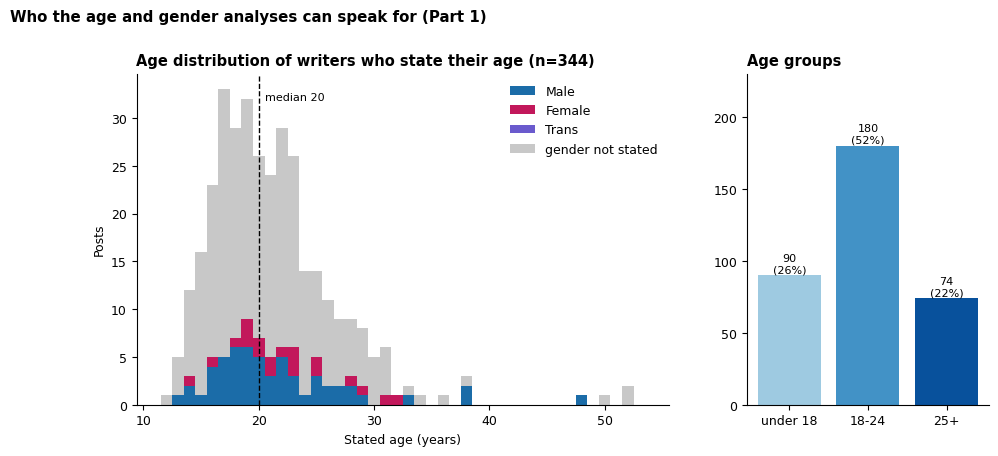

saved F01_age_profiles.png


In [ ]:
# ---------------- F01 overview Part 1: Age Distribution and Age Groups
# Local definition of styling / configuration variables to make cell self-contained
GEN_COL = {"Male": "#1b6ca8", "Female": "#c2185b", "Trans": "#6a5acd"}
AGE_COL = {"under 18": "#9ecae1", "18-24": "#4292c6", "25+": "#08519c"}
AGE_ORDER = ["under 18", "18-24", "25+"]
am = d.age_num.notna()
N_AGE = {g: int((d.age_bin == g).sum()) for g in AGE_ORDER}
OUT = "outputs/rq4_gt/figures/"

def save(fig, name):
    fig.savefig(OUT + name, dpi=170, bbox_inches="tight", facecolor="white")
    fig.set_dpi(100)
    plt.show()
    plt.close(fig)
    print("saved", name)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw=dict(width_ratios=[2.2, 1]))
bins = np.arange(11.5, 54, 1); a = d[am]
stack = [a[a.gender_known == g].age_num for g in ("Male", "Female", "Trans")] + [a[a.gender_known.isna()].age_num]
ax[0].hist(stack, bins=bins, stacked=True, color=[GEN_COL["Male"], GEN_COL["Female"], GEN_COL["Trans"], "#c8c8c8"], label=["Male", "Female", "Trans", "gender not stated"])
ax[0].axvline(a.age_num.median(), color="k", ls="--", lw=1); ax[0].text(a.age_num.median() + .5, ax[0].get_ylim()[1] * .92, f"median {a.age_num.median():.0f}", fontsize=8)
ax[0].set_xlabel("Stated age (years)"); ax[0].set_ylabel("Posts"); ax[0].set_title("Age distribution of writers who state their age (n=344)", loc="left"); ax[0].legend(frameon=False)

vals = [N_AGE[g] for g in AGE_ORDER]; b = ax[1].bar(AGE_ORDER, vals, color=[AGE_COL[g] for g in AGE_ORDER])
for r_, v in zip(b, vals): ax[1].text(r_.get_x() + r_.get_width() / 2, v + 2, f"{v}\n({100 * v / sum(vals):.0f}%)", ha="center", fontsize=8)
ax[1].set_ylim(0, 230); ax[1].set_title("Age groups", loc="left")
fig.suptitle("Who the age and gender analyses can speak for (Part 1)", x=.01, ha="left", fontweight="bold", y=1.03)
save(fig, "F01_age_profiles.png")

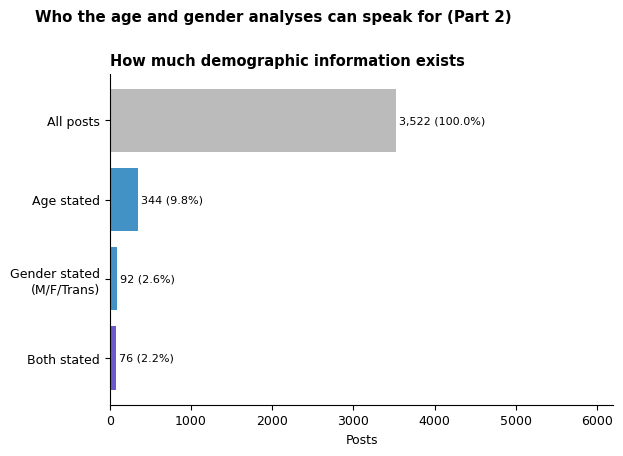

saved F01_demographic_coverage.png


In [ ]:
# ---------------- F01 overview Part 2: Demographic Information Coverage
# Local definition of variables to make cell self-contained
am = d.age_num.notna()
OUT = "outputs/rq4_gt/figures/"

def save(fig, name):
    fig.savefig(OUT + name, dpi=170, bbox_inches="tight", facecolor="white")
    fig.set_dpi(100)
    plt.show()
    plt.close(fig)
    print("saved", name)

fig, ax = plt.subplots(figsize=(6.5, 4.3))
cov = [("All posts", len(d)), ("Age stated", int(am.sum())), ("Gender stated\n(M/F/Trans)", int(d.gender_known.notna().sum())), ("Both stated", int((am & d.gender_known.notna()).sum()))]
ax.barh([c for c, _ in cov][::-1], [v for _, v in cov][::-1], color=["#6a5acd", "#4292c6", "#4292c6", "#bbbbbb"])
for i, (c, v) in enumerate(cov[::-1]): ax.text(v + 40, i, f"{v:,} ({100 * v / len(d):.1f}%)", va="center", fontsize=8)
ax.set_xlim(0, 6200); ax.set_title("How much demographic information exists", loc="left"); ax.set_xlabel("Posts")
fig.suptitle("Who the age and gender analyses can speak for (Part 2)", x=.01, ha="left", fontweight="bold", y=1.03)
save(fig, "F01_demographic_coverage.png")

### Figure 2 – How common is each factor?
**What we get:** A ranked bar chart of the share of posts carrying each label (stressors, relationships, emotions, responses, belong, burden), coloured by category.

**Why we did it:** Prevalence sets the baseline: a factor present in 2% of posts needs a very different test than one present in 50%, and rare labels cannot support strong conclusions.

*Sub-question(s): baseline for A, C*

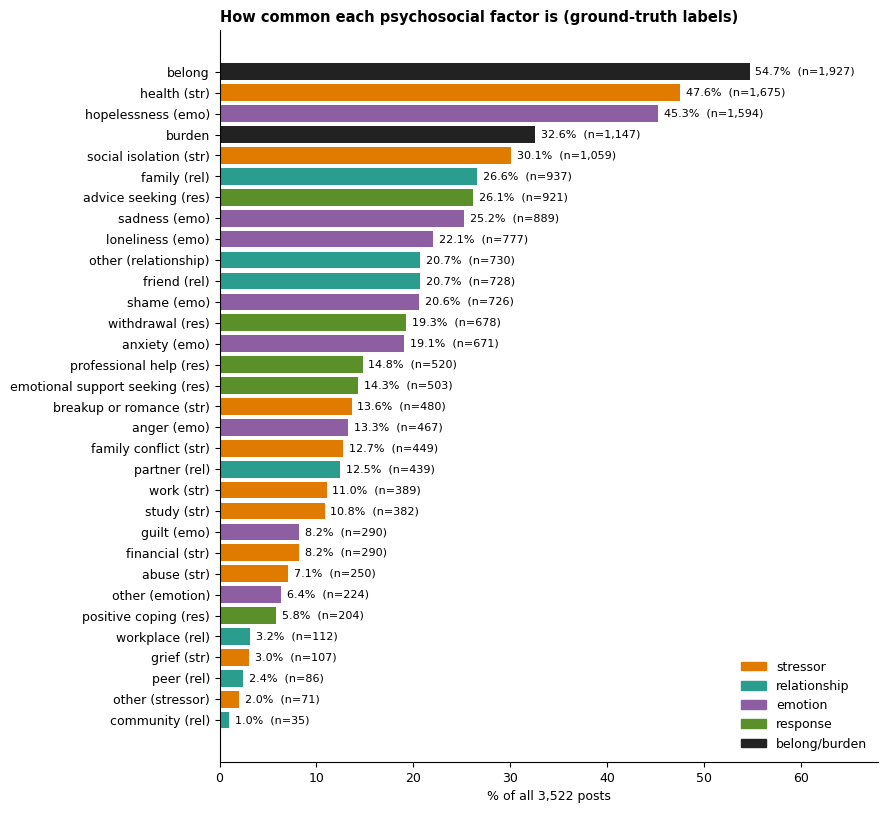

saved F02_overall_prevalence.png


In [ ]:
# =====================================================================
# Figure F02: Overall Factor Prevalence Plot
# =====================================================================
# Calculate raw percentage frequencies sorted in ascending order
factor_frequencies = (100.0 * X.mean()).sort_values()

# Construct human-readable labels indicating categories for non-target elements
formatted_labels = []
for column_name in factor_frequencies.index:
    cleaned_label = pretty(column_name)
    if column_name.endswith(": other") or cat_of[column_name] == "belong/burden":
        formatted_labels.append(cleaned_label)
    else:
        category_abbreviation = cat_of[column_name][:3]
        formatted_labels.append(f"{cleaned_label} ({category_abbreviation})")

# Set up plot dimensions and theme aesthetics
fig, ax = plt.subplots(figsize=(8.5, 9.5))

# Render horizontal bar charts using designated color mapping
bar_colors = [CAT_COL[cat_of[column]] for column in factor_frequencies.index]
horizontal_bars = ax.barh(formatted_labels, factor_frequencies.values, color=bar_colors)

# Annotate percentage values and exact post counts directly on each bar
for idx, (column_name, percent_value) in enumerate(factor_frequencies.items()):
    post_count = int(X[column_name].sum())
    annotation_text = f"{percent_value:.1f}%  (n={post_count:,})"
    ax.text(percent_value + 0.6, idx, annotation_text, va="center", fontsize=8)

# Configure labels, limits, legend, and title
ax.set_xlim(0, 68)
ax.set_xlabel("% of all 3,522 posts")

legend_handles = [Patch(color=color_hex, label=category_name) for category_name, color_hex in CAT_COL.items()]
ax.legend(handles=legend_handles, frameon=False, loc="lower right")
ax.set_title("How common each psychosocial factor is (ground-truth labels)", loc="left")

save(fig, "F02_overall_prevalence.png")

### Figure 3 – Belonging and burden by age group (Q11)
**What we get:** Prevalence of thwarted belongingness (TBe) and perceived burdensomeness (PBu) in under-18, 18-24 and 25+ writers, with 95% Wilson CIs, plus the four-way pattern (Neither / TBe only / PBu only / Both) by age group.

**Why we did it:** This answers the headline question: is any age group more prone to TBe or PBu? A permutation chi-square gives the between-group p, and a logistic trend gives the odds change per 5 years of age.

*Sub-question(s): Q11*

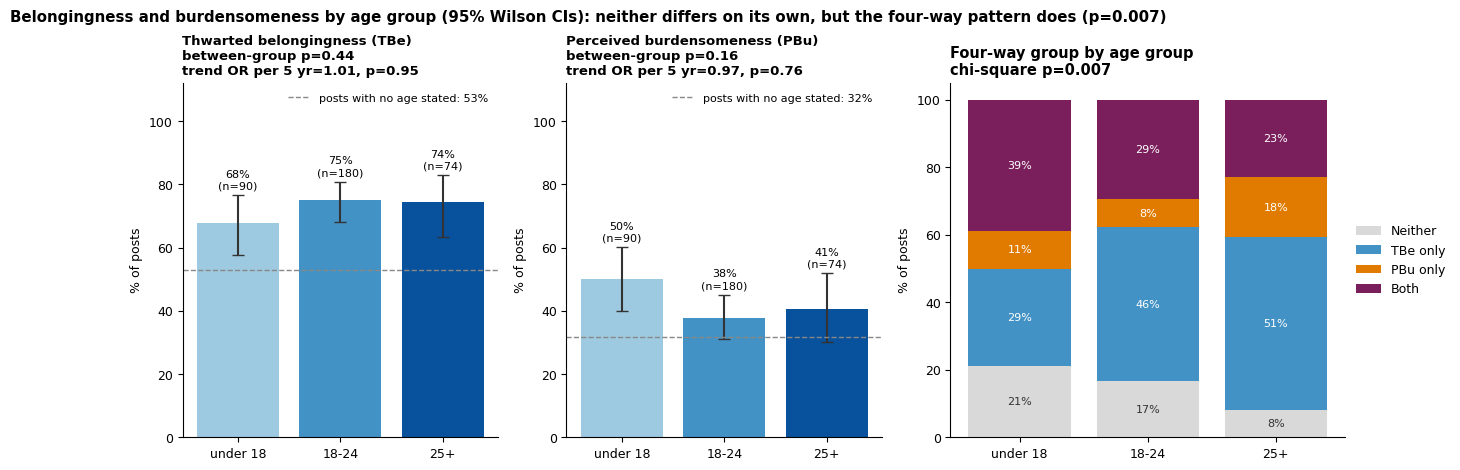

saved F03_belong_burden_by_age_group.png


In [ ]:
# =====================================================================
# Figure F03: Belonging & Burden by Age Group + Four-Way Distribution
# =====================================================================
# Retrieve datasets and statistical summary tables from registry
bb_prevalences = R["bb_prev"]
bb_tests_df = R["bb_tests"].set_index("outcome")

# Configure figure layout: 2 plots for individual outcomes, 1 for four-way distribution
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 1.25]))

outcome_titles = {
    "belong": "Thwarted belongingness (TBe)",
    "burden": "Perceived burdensomeness (PBu)"
}

# 1. Plot individual outcomes (TBe and PBu)
for idx, outcome in enumerate(("belong", "burden")):
    ax = axs[idx]

    # Filter data for known binned age groups and unstated age separately
    stated_age_df = bb_prevalences[(bb_prevalences.outcome == outcome) & (bb_prevalences.age_group.isin(AGE_ORDER))]
    unstated_age_row = bb_prevalences[(bb_prevalences.outcome == outcome) & (bb_prevalences.age_group == "age not stated")].iloc[0]

    # Prepare error boundaries for the plot
    lower_errors = stated_age_df.pct - stated_age_df.ci_low
    upper_errors = stated_age_df.ci_high - stated_age_df.pct

    # Draw binned bar sequences
    group_colors = [AGE_COL[group] for group in stated_age_df.age_group]
    ax.bar(stated_age_df.age_group, stated_age_df.pct, color=group_colors, yerr=[lower_errors, upper_errors], capsize=4, ecolor="#333")

    # Annotate percent values above each bar
    for bar_x, (_, row) in enumerate(stated_age_df.iterrows()):
         ax.text(bar_x, row.ci_high + 2, f"{row.pct:.0f}%\n(n={row.n})", ha="center", fontsize=8)

    # Draw global reference line representing unstated age groups
    ax.axhline(unstated_age_row.pct, color="#888", ls="--", lw=1, label=f"posts with no age stated: {unstated_age_row.pct:.0f}%")
    ax.legend(frameon=False, loc="upper right", fontsize=8)

    ax.set_ylim(0, 112)
    ax.set_ylabel("% of posts")

    # Set title utilizing computed linear and omnibus trend test outputs
    test_metrics = bb_tests_df.loc[outcome]
    ax.set_title(
        f"{outcome_titles[outcome]}\n"
        f"between-group p={test_metrics.p_omnibus:.2f}\n"
        f"trend OR per 5 yr={test_metrics.or_per_5yr:.2f}, p={test_metrics.p_trend:.2f}",
        loc="left",
        fontsize=9.5
    )

# 2. Plot stacked four-way classification
ax_fourway = axs[2]
age_group_counts = R["group_by_age"]
percentage_distribution = age_group_counts.div(age_group_counts.sum(axis=1), axis=0) * 100.0

stacked_base = np.zeros(3)
category_palette = {
    "Neither": "#d9d9d9",
    "TBe only": "#4292c6",
    "PBu only": "#e07b00",
    "Both": "#7a1f5c"
}

for group_name in ["Neither", "TBe only", "PBu only", "Both"]:
    category_percentages = percentage_distribution[group_name]
    ax_fourway.bar(AGE_ORDER, category_percentages, bottom=stacked_base, color=category_palette[group_name], label=group_name)

    # Label proportions on top of each corresponding segment stack
    for group_idx, segment_val in enumerate(category_percentages):
        label_y = stacked_base[group_idx] + segment_val / 2.0
        text_color = "white" if group_name != "Neither" else "#333"
        ax_fourway.text(group_idx, label_y, f"{segment_val:.0f}%", ha="center", va="center", fontsize=8, color=text_color)

    stacked_base += category_percentages.values

ax_fourway.set_ylabel("% of posts")
ax_fourway.legend(frameon=False, bbox_to_anchor=(1, .5), loc="center left")
ax_fourway.set_title(f"Four-way group by age group\nchi-square p={R['group_by_age_test']['p']:.3f}", loc="left")

# Display main supertitle summary mapping
fig.suptitle(
    f"Belongingness and burdensomeness by age group (95% Wilson CIs): neither differs on its own, "
    f"but the four-way pattern does (p={R['group_by_age_test']['p']:.3f})",
    x=0.01,
    ha="left",
    fontweight="bold",
    y=1.04
)

save(fig, "F03_belong_burden_by_age_group.png")

### Figure 4 – Smooth age curves for belong and burden (Q11, Q13)
**What we get:** Prevalence at single ages (points, with CIs) and a fitted logistic trend with a confidence band.

**Why we did it:** Age groups hide detail. A continuous curve shows whether risk rises, falls or bends (non-linear) across the lifespan.

*Sub-question(s): Q11, Q13*

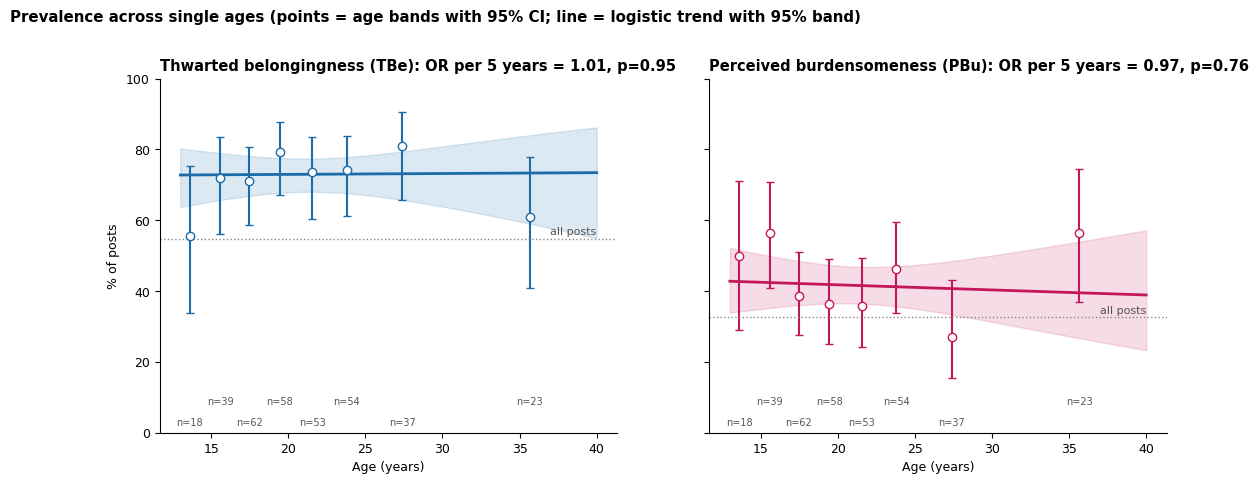

saved F04_belong_burden_age_curve.png


In [ ]:
# =====================================================================
# Figure F04: Smooth Age-Prevalence Curves for Belonging & Burden
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

def calculate_binned_prevalence(y_outcomes, ages, age_edges):
    """Calculates prevalence rates within sequential binned age boundaries."""
    records = []
    for lower_bound, upper_bound in zip(age_edges[:-1], age_edges[1:]):
        bin_mask = (ages >= lower_bound) & (ages < upper_bound)
        if bin_mask.sum() >= 8:
            positives = y_outcomes[bin_mask].sum()
            total_count = bin_mask.sum()
            ci_low, ci_high = wil(positives, total_count)

            records.append({
                "mean_age": ages[bin_mask].mean(),
                "pct_prevalence": 100.0 * positives / total_count,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "sample_size": total_count
            })
    return pd.DataFrame(records)

def fit_logistic_trajectory(y_outcomes, ages, evaluation_grid):
    """Fits a logistic regression model on scaled ages and projects predictions with standard error bands."""
    # Scale age by 5 years to match downstream risk factors
    scaled_ages = ages / 5.0
    logistic_model = sm.Logit(y_outcomes, sm.add_constant(scaled_ages)).fit(disp=0)

    # Project on evaluation grid
    grid_predictors = sm.add_constant(evaluation_grid / 5.0)
    predicted_log_odds = grid_predictors @ logistic_model.params

    # Calculate standard errors for confidence bands
    confidence_band_std_error = np.sqrt(np.einsum("ij,jk,ik->i", grid_predictors, logistic_model.cov_params(), grid_predictors))

    # Helper mapping function from log-odds space to percentage scale
    log_odds_to_percent = lambda log_odds: 100.0 / (1.0 + np.exp(-log_odds))

    projected_mean = log_odds_to_percent(predicted_log_odds)
    projected_ci_lower = log_odds_to_percent(predicted_log_odds - 1.96 * confidence_band_std_error)
    projected_ci_upper = log_odds_to_percent(predicted_log_odds + 1.96 * confidence_band_std_error)

    return projected_mean, projected_ci_lower, projected_ci_upper, logistic_model

# Configure plotting axes
age_bin_edges = [12, 15, 17, 19, 21, 23, 26, 30, 53]
age_evaluation_grid = np.linspace(13, 40, 100)
stated_ages = d.loc[am, "age_num"].values

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
outcome_titles = {
    "belong": "Thwarted belongingness (TBe)",
    "burden": "Perceived burdensomeness (PBu)"
}

for idx, outcome in enumerate(("belong", "burden")):
    ax = axs[idx]
    y_outcomes = X.loc[am, outcome].values

    # 1. Compute empirical binned points
    binned_prevalence_df = calculate_binned_prevalence(y_outcomes, stated_ages, age_bin_edges)

    # 2. Predict smooth trajectory trend lines
    projected_mean, projected_ci_lower, projected_ci_upper, model_fit = fit_logistic_trajectory(
        y_outcomes,
        stated_ages,
        age_evaluation_grid
    )

    # Plot configuration and confidence band formatting
    theme_color = "#1b6ca8" if outcome == "belong" else "#c2185b"
    ax.fill_between(age_evaluation_grid, projected_ci_lower, projected_ci_upper, color=theme_color, alpha=0.15)
    ax.plot(age_evaluation_grid, projected_mean, color=theme_color, lw=2)

    # Plot empirical markers with error bars
    ax.errorbar(
        binned_prevalence_df.mean_age,
        binned_prevalence_df.pct_prevalence,
        yerr=[
            binned_prevalence_df.pct_prevalence - binned_prevalence_df.ci_low,
            binned_prevalence_df.ci_high - binned_prevalence_df.pct_prevalence
        ],
        fmt="o",
        color=theme_color,
        mfc="white",
        capsize=3
    )

    # Add offset text annotations showing count info below each marker
    for marker_idx, (_, row) in enumerate(binned_prevalence_df.iterrows()):
        vertical_text_offset = 2 + 6 * (marker_idx % 2)
        ax.text(row.mean_age, vertical_text_offset, f"n={int(row.sample_size)}", ha="center", fontsize=7, color="#555")

    # Draw overall population reference line
    overall_prevalence_rate = 100.0 * X[outcome].mean()
    ax.axhline(overall_prevalence_rate, color="#888", ls=":", lw=1)
    ax.text(40, overall_prevalence_rate + 1.2, "all posts", ha="right", fontsize=8, color="#555")

    ax.set_ylim(0, 100)
    ax.set_xlabel("Age (years)")

    odds_ratio_per_5yr = np.exp(model_fit.params[1])
    p_value_trend = model_fit.pvalues[1]
    ax.set_title(
        f"{outcome_titles[outcome]}: OR per 5 years = {odds_ratio_per_5yr:.2f}, p={p_value_trend:.2f}",
        loc="left",
        fontsize=10
    )

axs[0].set_ylabel("% of posts")
fig.suptitle(
    "Prevalence across single ages (points = age bands with 95% CI; line = logistic trend with 95% band)",
    x=0.01,
    ha="left",
    fontweight="bold",
    y=1.03
)

save(fig, "F04_belong_burden_age_curve.png")

### Figure 5 – Which factors appear in which age group (Q12)
**What we get:** A heatmap of the % of posts with each factor within each age group; stars mark factors whose frequency differs across age groups after FDR correction.

**Why we did it:** Shows which stressors, relationships, emotions and responses are age-linked. FDR is used because 32 factors are tested at once.

*Sub-question(s): Q12*

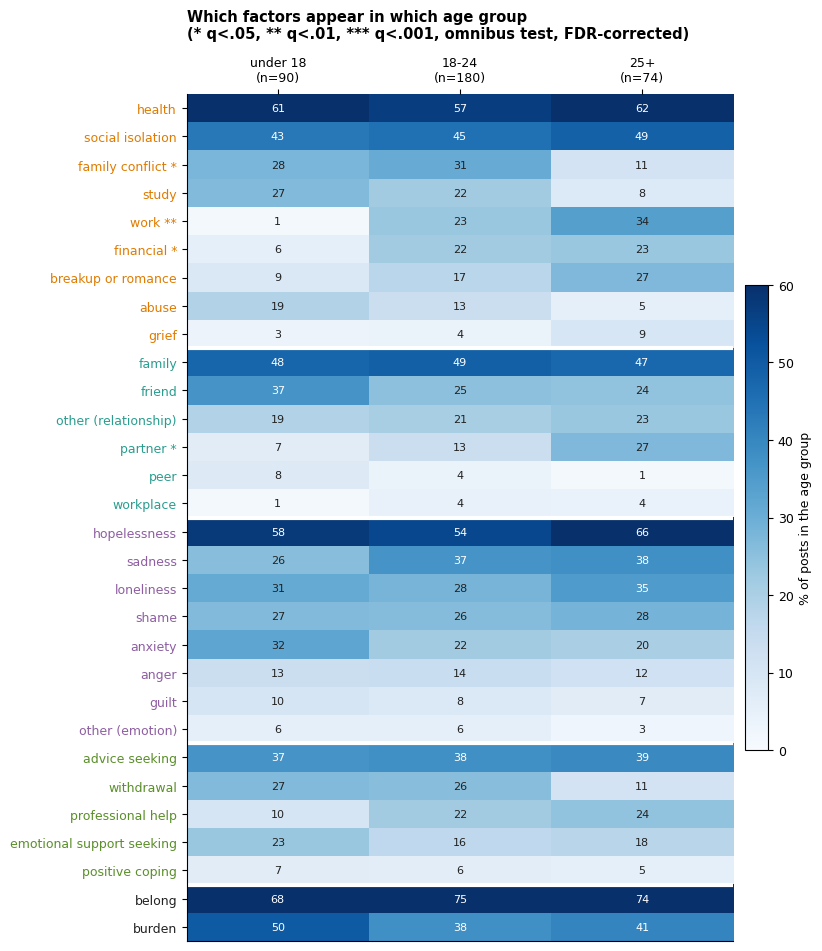

saved F05_factor_prevalence_by_age_group.png


In [ ]:
# ---------------- F05 heatmap prevalence by age group
fa = R["factor_age"].copy(); fa["cat_rank"] = fa.category.map({c: i for i, c in enumerate(CATS)})
fa = fa.sort_values(["cat_rank", "pct_overall_agesample"], ascending=[True, False]).reset_index(drop=True)
rows = fa.label.tolist(); M = fa[[f"pct_{g}" for g in AGE_ORDER]].values; fig, ax = plt.subplots(figsize=(7.5, 11))
im = ax.imshow(M, cmap="Blues", aspect="auto", vmin=0, vmax=60)
for i in range(M.shape[0]):
    for j in range(3): ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if M[i, j] > 35 else "#222")
ax.set_xticks(range(3)); ax.set_xticklabels([f"{g}\n(n={N_AGE[g]})" for g in AGE_ORDER]); ax.xaxis.tick_top()
ax.set_yticks(range(len(rows))); ax.set_yticklabels([pretty(r) + (" " + stars(q) if q < .05 else "") for r, q in zip(rows, fa.q_omnibus)])
for t, r in zip(ax.get_yticklabels(), rows): t.set_color(CAT_COL[cat_of[r]])
prev_c = None
for i, r in enumerate(rows):
    if cat_of[r] != prev_c and i > 0: ax.axhline(i - .5, color="white", lw=3)
    prev_c = cat_of[r]
cb = fig.colorbar(im, fraction=.04, pad=.02); cb.set_label("% of posts in the age group")
ax.set_title("Which factors appear in which age group\n(* q<.05, ** q<.01, *** q<.001, omnibus test, FDR-corrected)", loc="left", pad=40); save(fig, "F05_factor_prevalence_by_age_group.png")

### Figure 6 – Over- and under-representation by age and gender (Q12, Q15)
**What we get:** Two heatmaps of relative risk: each age group vs everyone else, and male vs female.

**Why we did it:** Relative risk puts rare and common factors on one scale, so we can see the direction and size of each group difference, not just significance.

*Sub-question(s): Q12, Q15*

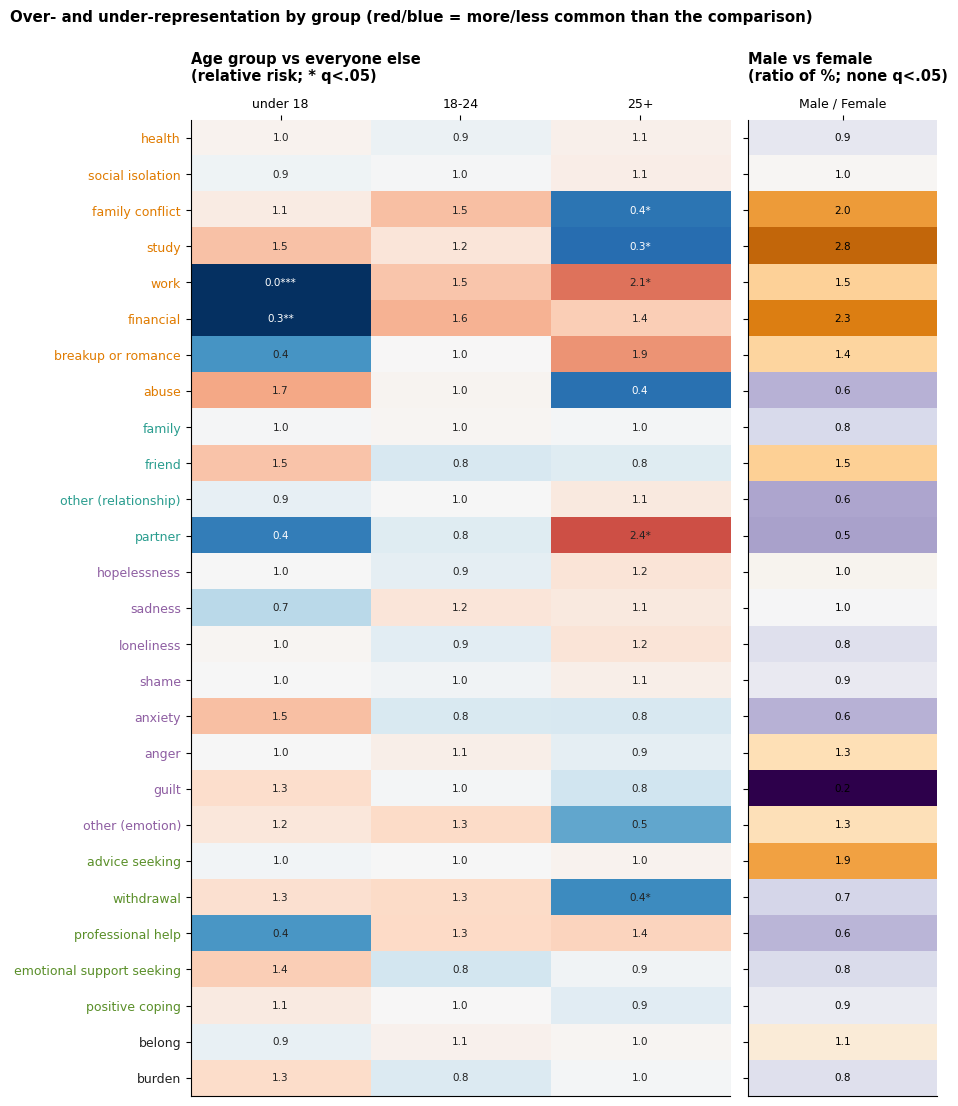

saved F06_relative_risk_age_gender.png


In [ ]:
# ---------------- F06 relative risk heatmaps (age + gender)
gen = R["factor_gender"].set_index("label"); labs = [r for r in rows if r in gen.index]
RR = np.log2(fa.set_index("label").loc[labs, [f"RR_{g}" for g in AGE_ORDER]].values.astype(float))
GR = np.log2(((gen.loc[labs, "pct_male"] + .5) / (gen.loc[labs, "pct_female"] + .5)).values)[:, None]
fig, ax = plt.subplots(1, 2, figsize=(9.5, 11), gridspec_kw=dict(width_ratios=[3, 1.05]), sharey=True)
im = ax[0].imshow(RR, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
fq = fa.set_index("label")
for i, r in enumerate(labs):
    for j, g in enumerate(AGE_ORDER):
        v = fq.loc[r, f"RR_{g}"]; q = fq.loc[r, f"q_{g}_vs_rest"]
        ax[0].text(j, i, f"{v:.1f}{stars(q)}", ha="center", va="center", fontsize=7.5, color="white" if abs(np.log2(v)) > 1.3 else "#222")
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(AGE_ORDER); ax[0].xaxis.tick_top(); ax[0].set_title("Age group vs everyone else\n(relative risk; * q<.05)", loc="left", pad=28)
ax[0].set_yticks(range(len(labs))); ax[0].set_yticklabels([pretty(r) for r in labs])
for t, r in zip(ax[0].get_yticklabels(), labs): t.set_color(CAT_COL[cat_of[r]])
ax[1].imshow(GR, cmap="PuOr_r", vmin=-2, vmax=2, aspect="auto"); ax[1].set_xticks([0]); ax[1].set_xticklabels(["Male / Female"]); ax[1].xaxis.tick_top()
for i, r in enumerate(labs): ax[1].text(0, i, f"{(gen.loc[r, 'pct_male'] + .5) / (gen.loc[r, 'pct_female'] + .5):.1f}{stars(gen.loc[r, 'q_fdr'])}", ha="center", va="center", fontsize=7.5)
ax[1].set_title("Male vs female\n(ratio of %; none q<.05)", loc="left", pad=28)
fig.suptitle("Over- and under-representation by group (red/blue = more/less common than the comparison)", x=.01, ha="left", fontweight="bold", y=1.0); fig.tight_layout(); save(fig, "F06_relative_risk_age_gender.png")

### Figure 7 – Does each factor rise or fall with age? (Q12, Q13)
**What we get:** A forest plot of the odds ratio per 5 years of age for every factor, with 95% CIs.

**Why we did it:** Uses all the age information (not just 3 bins) and summarises the direction and strength of every age trend in one chart.

*Sub-question(s): Q12, Q13*

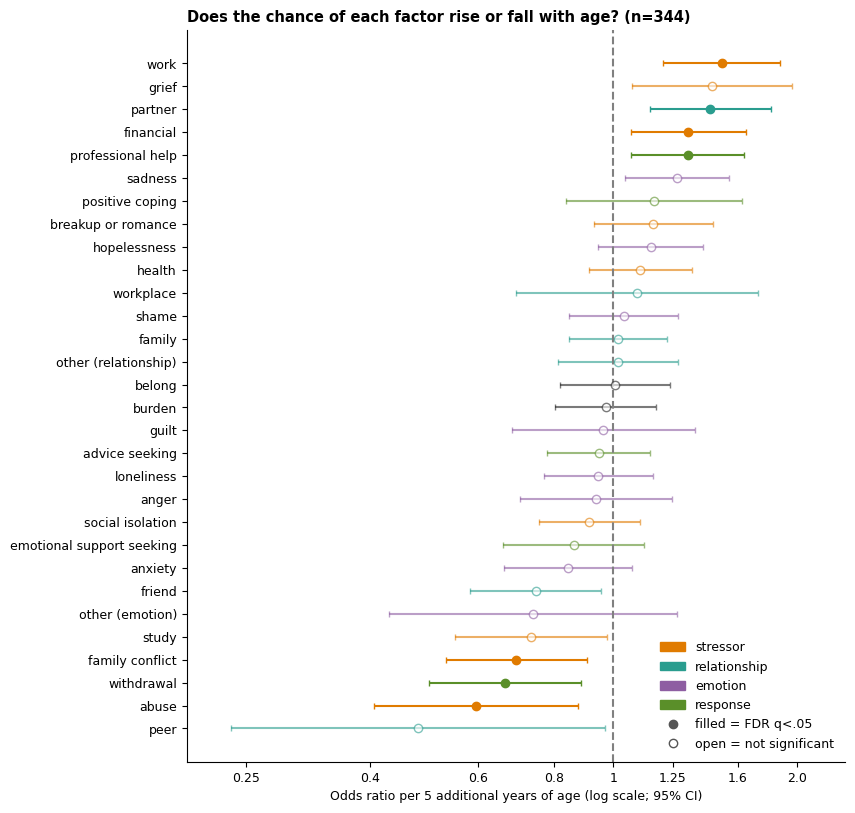

saved F07_age_trend_forest.png


In [ ]:
# ---------------- F07 forest ORs per 5 years
f7 = R["factor_age"].sort_values("or_per_5yr").reset_index(drop=True); fig, ax = plt.subplots(figsize=(8.5, 9.5)); y = np.arange(len(f7))
for i, r in f7.iterrows():
    sig = r.q_trend < .05
    ax.errorbar(r.or_per_5yr, i, xerr=[[r.or_per_5yr - r.or_ci_low], [r.or_ci_high - r.or_per_5yr]], fmt="o" if sig else "o", color=CAT_COL[r.category], mfc=CAT_COL[r.category] if sig else "white", ecolor=CAT_COL[r.category], capsize=2, alpha=1 if sig else .6)
ax.axvline(1, color="gray", ls="--"); ax.set_xscale("log"); ax.set_yticks(y); ax.set_yticklabels([pretty(c) for c in f7.label]); ax.set_xlabel("Odds ratio per 5 additional years of age (log scale; 95% CI)")
from matplotlib.ticker import NullFormatter
ax.set_xlim(.2, 2.4); ax.xaxis.set_minor_formatter(NullFormatter()); ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.set_xticks([.25, .4, .6, .8, 1, 1.25, 1.6, 2.0]); ax.set_xticklabels(["0.25", "0.4", "0.6", "0.8", "1", "1.25", "1.6", "2.0"])
ax.legend(handles=[Patch(color=v, label=k) for k, v in CAT_COL.items() if k != "belong/burden"] + [Line2D([], [], marker="o", color="#555", ls="", label="filled = FDR q<.05"), Line2D([], [], marker="o", mfc="white", color="#555", ls="", label="open = not significant")], frameon=False, loc="lower right")
ax.set_title("Does the chance of each factor rise or fall with age? (n=344)", loc="left"); save(fig, "F07_age_trend_forest.png")

### Figure 8 – Age curves for the factors that change with age (Q12)
**What we get:** Small-multiple curves for only those factors with an FDR-significant age trend.

**Why we did it:** Zooms in on the factors that matter so we can see the shape of each trend.

*Sub-question(s): Q12*

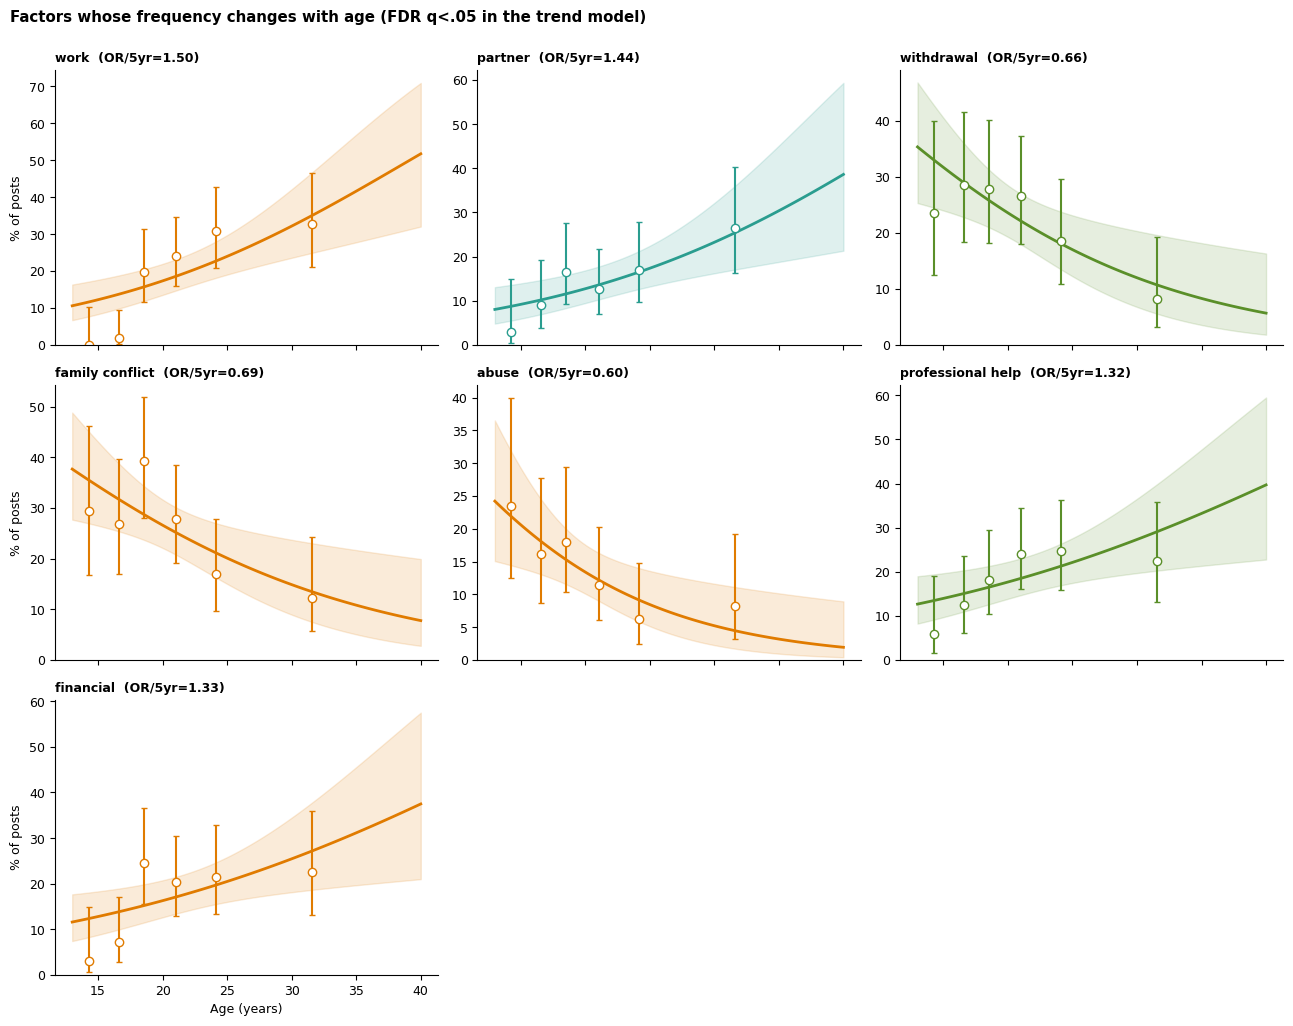

saved F08_age_curves_significant_factors.png


In [ ]:
# ---------------- F08 small multiples of age curves
sel = R["factor_age"][R["factor_age"].q_trend < .05].sort_values("p_trend").label.tolist()[:9]
n = len(sel); ncol = 3; nrow = int(np.ceil(n / ncol)); fig, axs = plt.subplots(nrow, ncol, figsize=(13, 3.4 * nrow), sharex=True); axs = np.atleast_2d(axs)
for k, lab in enumerate(sel):
    a_ = axs[k // ncol, k % ncol]; y = X.loc[am, lab].values; m, lo, hi, f = logit_curve(y, ag, grid); bd = binned(y, ag, [12, 16, 18, 20, 23, 27, 53])
    a_.fill_between(grid, lo, hi, color=CAT_COL[cat_of[lab]], alpha=.15); a_.plot(grid, m, color=CAT_COL[cat_of[lab]], lw=2)
    a_.errorbar(bd.age, bd.pct, yerr=[bd.pct - bd.lo, bd.hi - bd.pct], fmt="o", mfc="white", color=CAT_COL[cat_of[lab]], capsize=2)
    a_.set_title(f"{pretty(lab)}  (OR/5yr={np.exp(f.params[1]):.2f})", loc="left", fontsize=9); a_.set_ylim(0, None)
    if k % ncol == 0: a_.set_ylabel("% of posts")
for k in range(n, nrow * ncol): axs[k // ncol, k % ncol].axis("off")
for a_ in axs[-1]: a_.set_xlabel("Age (years)")
fig.suptitle("Factors whose frequency changes with age (FDR q<.05 in the trend model)", x=.01, ha="left", fontweight="bold", y=1.0); fig.tight_layout(); save(fig, "F08_age_curves_significant_factors.png")

### Figure 9 – Male vs female writers (Q14, Q15)
**What we get:** Left: belong, burden and the 12 largest gaps between men and women. Right: every factor's odds ratio with its CI.

**Why we did it:** Tests whether gender changes the psychosocial profile. The wide CIs make the limited power (n=61 vs 27) visible instead of hiding it in a p-value.

*Sub-question(s): Q14, Q15*

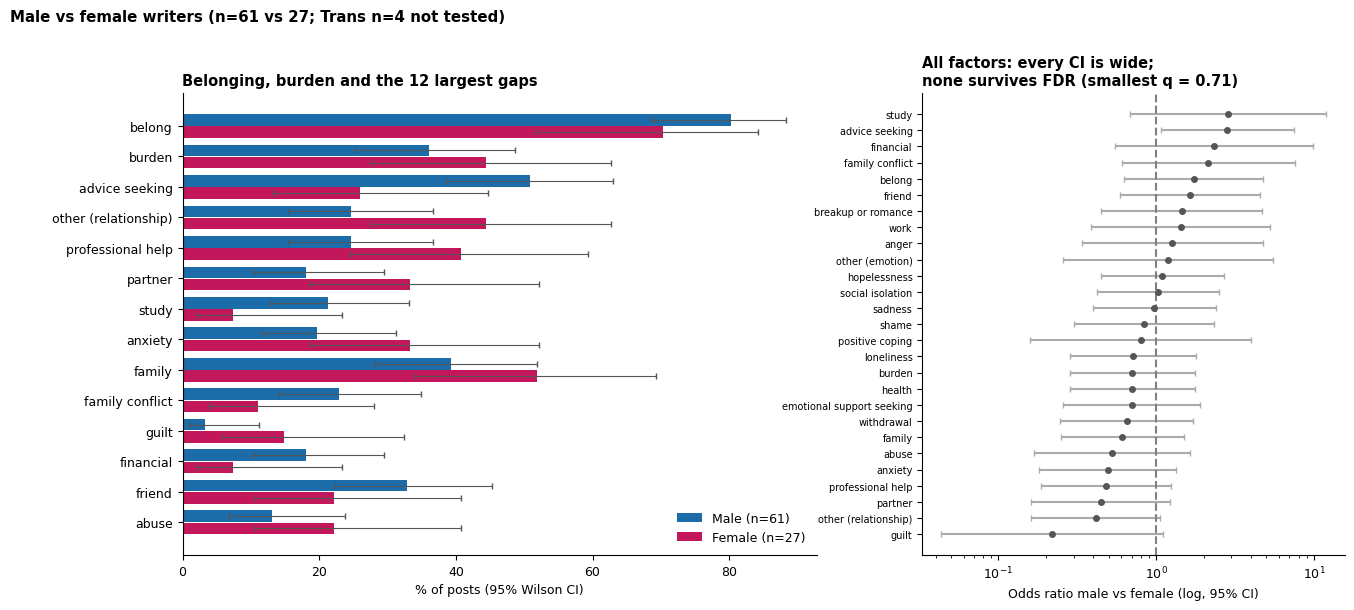

saved F09_gender_comparison.png


In [ ]:
# ---------------- F09 gender comparison
g = R["factor_gender"]; g_ = g[~g.label.isin(["belong", "burden"])]; top = g_.reindex(g_.diff_pts.abs().sort_values(ascending=False).index).head(12)
bbg = R["bb_gender"]; fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw=dict(width_ratios=[1.5, 1]))
names = ["belong", "burden"] + top.label.tolist(); nM, nF = int((d.gender_known == "Male").sum()), int((d.gender_known == "Female").sum()); yy = np.arange(len(names))[::-1]
for gname, off in (("Male", .2), ("Female", -.2)):
    nn = nM if gname == "Male" else nF; vals = []; los = []; his = []
    for nm in names:
        k = int(X.loc[d.gender_known == gname, nm].sum()); l, h = wil(k, nn); vals.append(100 * k / nn); los.append(l); his.append(h)
    ax[0].barh(yy + off, vals, height=.38, color=GEN_COL[gname], label=f"{gname} (n={nn})", xerr=[np.array(vals) - np.array(los), np.array(his) - np.array(vals)], error_kw=dict(ecolor="#555", lw=.8, capsize=2))
ax[0].set_yticks(yy); ax[0].set_yticklabels([pretty(n_) for n_ in names]); ax[0].legend(frameon=False); ax[0].set_xlabel("% of posts (95% Wilson CI)")
ax[0].set_title("Belonging, burden and the 12 largest gaps", loc="left")
gg = g.sort_values("odds_ratio_M_vs_F").reset_index(drop=True); yy2 = np.arange(len(gg))
ax[1].errorbar(gg.odds_ratio_M_vs_F, yy2, xerr=[gg.odds_ratio_M_vs_F - gg.or_ci_low, gg.or_ci_high - gg.odds_ratio_M_vs_F], fmt="o", color="#555", ecolor="#aaa", capsize=2, ms=4)
ax[1].axvline(1, color="gray", ls="--"); ax[1].set_xscale("log"); ax[1].set_yticks(yy2); ax[1].set_yticklabels([pretty(c) for c in gg.label], fontsize=7); ax[1].set_xlabel("Odds ratio male vs female (log, 95% CI)")
ax[1].set_title("All factors: every CI is wide;\nnone survives FDR (smallest q = %.2f)" % g.q_fdr.min(), loc="left")
fig.suptitle("Male vs female writers (n=61 vs 27; Trans n=4 not tested)", x=.01, ha="left", fontweight="bold", y=1.02); save(fig, "F09_gender_comparison.png")

### Figure 10 – Gender × age group (Q17)
**What we get:** Belong and burden % in each gender-by-age cell; cells with fewer than 8 posts are hidden.

**Why we did it:** A first look at whether the age pattern differs by gender. Tiny cells are suppressed to avoid over-reading noise.

*Sub-question(s): Q17*

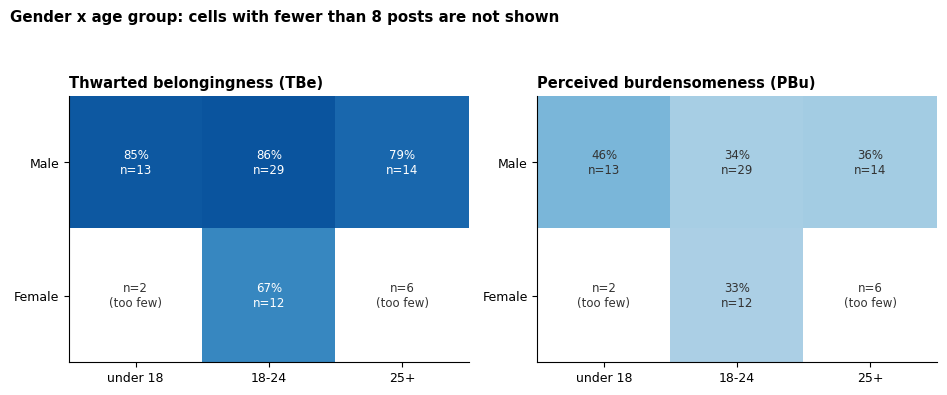

saved F10_belong_burden_gender_by_age.png


In [ ]:
# ---------------- F10 belong/burden by gender x age group
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8)); gens = ["Male", "Female"]
for i, out in enumerate(("belong", "burden")):
    P = np.full((2, 3), np.nan); Nn = np.zeros((2, 3), int)
    for r_, gn in enumerate(gens):
        for c_, ab in enumerate(AGE_ORDER):
            m = (d.gender_known == gn) & (d.age_bin == ab); Nn[r_, c_] = m.sum()
            if m.sum() >= 1: P[r_, c_] = 100 * X.loc[m, out].mean()
    im = ax[i].imshow(np.where(Nn >= 8, P, np.nan), cmap="Blues", vmin=0, vmax=100)
    for r_ in range(2):
        for c_ in range(3): ax[i].text(c_, r_, (f"{P[r_, c_]:.0f}%\nn={Nn[r_, c_]}" if Nn[r_, c_] >= 8 else f"n={Nn[r_, c_]}\n(too few)"), ha="center", va="center", fontsize=8.5, color="white" if Nn[r_, c_] >= 8 and P[r_, c_] > 60 else "#333")
    ax[i].set_xticks(range(3)); ax[i].set_xticklabels(AGE_ORDER); ax[i].set_yticks(range(2)); ax[i].set_yticklabels(gens); ax[i].set_title(titles[out], loc="left")
fig.suptitle("Gender x age group: cells with fewer than 8 posts are not shown", x=.01, ha="left", fontweight="bold", y=1.04); fig.tight_layout(); save(fig, "F10_belong_burden_gender_by_age.png")

### Figure 11 – How well can age alone tell what a person is going through? (Q16)
**What we get:** Cross-validated AUC of an age-only model for each factor, against the range expected by chance (permutation null).

**Why we did it:** A significant p-value can come with almost no usefulness. AUC measures how much age actually helps predict a factor (0.5 = chance).

*Sub-question(s): Q16*

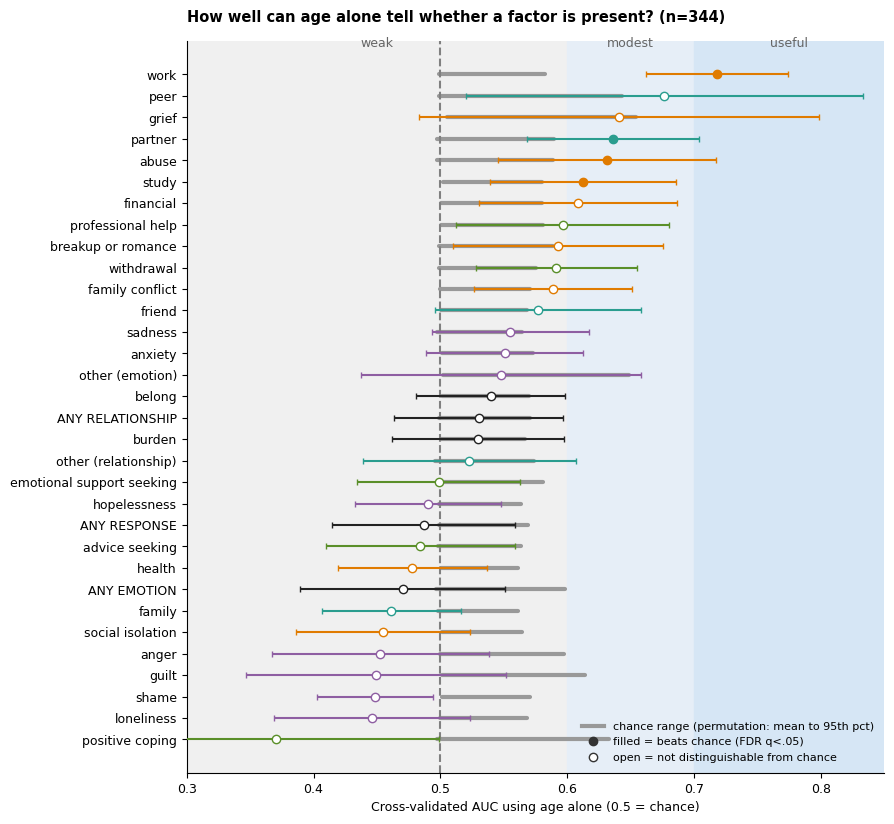

saved F11_age_predictive_power.png


In [ ]:
# ---------------- F11 predictive strength of age
pr = R["pred_age"].sort_values("cv_auc_age").reset_index(drop=True); fig, ax = plt.subplots(figsize=(9, 9.5))
ax.axvspan(.3, .6, color="#f0f0f0"); ax.axvspan(.6, .7, color="#e6eef7"); ax.axvspan(.7, .85, color="#d6e6f5")
for i, r in pr.iterrows():
    col = "#222" if r.kind in ("category", "belong/burden") else CAT_COL[r.kind]; sig = r.q_perm < .05
    ax.plot([r.null_mean, r.null_95], [i, i], color="#999", lw=3, solid_capstyle="round", zorder=1)
    ax.errorbar(r.cv_auc_age, i, xerr=r.cv_auc_sd, fmt="o", color=col, mfc=col if sig else "white", capsize=2, ms=6, zorder=3)
ax.set_yticks(range(len(pr))); ax.set_yticklabels([("ANY " + t[4:].upper() if t.startswith("any ") else pretty(t)) for t in pr.target])
ax.axvline(.5, color="gray", ls="--"); ax.set_xlim(.3, .85); ax.set_xlabel("Cross-validated AUC using age alone (0.5 = chance)")
ax.text(.45, len(pr) + .3, "weak", ha="center", color="#666"); ax.text(.65, len(pr) + .3, "modest", ha="center", color="#666"); ax.text(.775, len(pr) + .3, "useful", ha="center", color="#666")
ax.legend(handles=[Line2D([], [], color="#999", lw=3, label="chance range (permutation: mean to 95th pct)"), Line2D([], [], marker="o", color="#333", ls="", label="filled = beats chance (FDR q<.05)"),
                   Line2D([], [], marker="o", mfc="white", color="#333", ls="", label="open = not distinguishable from chance")], frameon=False, loc="lower right", fontsize=8)
ax.set_title("How well can age alone tell whether a factor is present? (n=344)", loc="left", pad=14); save(fig, "F11_age_predictive_power.png")

### Figure 12 – Is age a strong variable? (Q10, Q16)
**What we get:** Left: AUC of age alone vs the other psychological factors as predictors of belong/burden. Right: share of the whole 32-factor profile variance explained by age and by gender (PERMANOVA).

**Why we did it:** Puts age in context: if other factors predict far better than age, age is a weak variable for deciding who has which difficulty.

*Sub-question(s): Q10, Q16*

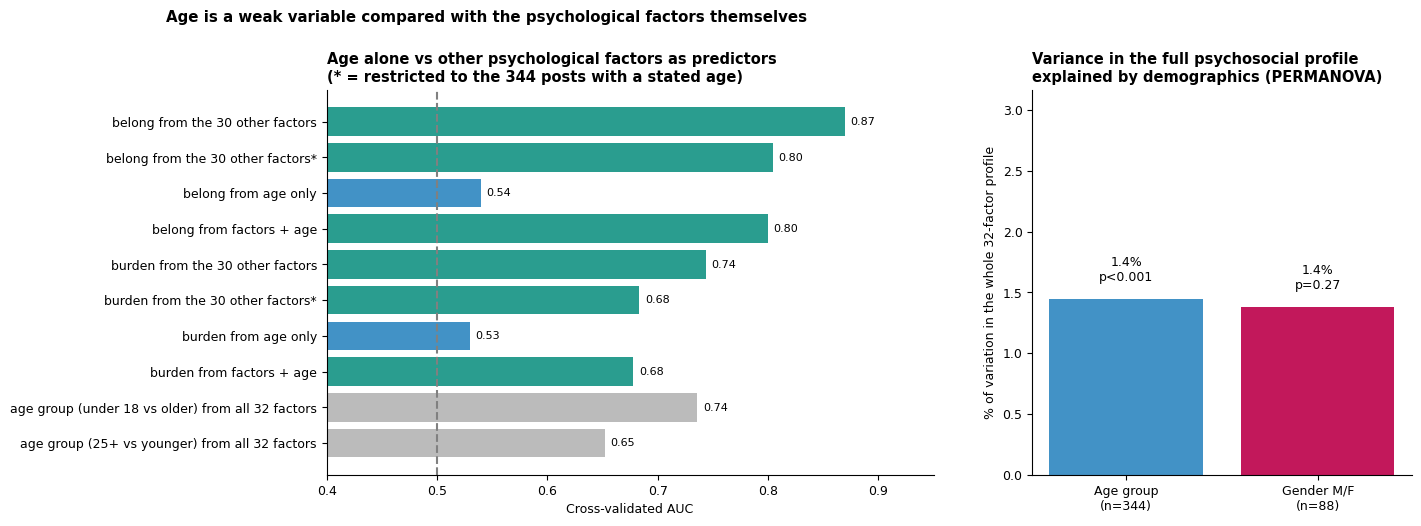

saved F12_age_vs_other_predictors.png


In [ ]:
# ---------------- F12 benchmark
bm = R["benchmark"].copy(); fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1.6, 1]))
bm["short"] = bm.task.str.replace("predict ", "").str.replace(" (age-stated sample)", "*", regex=False); bm = bm.iloc[::-1].reset_index(drop=True)
cols = ["#4292c6" if "age only" in t else "#bbbbbb" if "age group" in t else "#2a9d8f" for t in bm.task]
ax[0].barh(bm.short, bm.cv_auc, color=cols)
for i, v in enumerate(bm.cv_auc): ax[0].text(v + .005, i, f"{v:.2f}", va="center", fontsize=8)
ax[0].axvline(.5, color="gray", ls="--"); ax[0].set_xlim(.4, .95); ax[0].set_xlabel("Cross-validated AUC"); ax[0].set_title("Age alone vs other psychological factors as predictors\n(* = restricted to the 344 posts with a stated age)", loc="left")
pa, pg = R["permanova_age"], R["permanova_gender"]
ax[1].bar(["Age group\n(n=344)", "Gender M/F\n(n=88)"], [100 * pa["R2"], 100 * pg["R2"]], color=["#4292c6", "#c2185b"])
for i, (r2, p) in enumerate(((pa["R2"], pa["p"]), (pg["R2"], pg["p"]))): ax[1].text(i, 100 * r2 + .15, f"{100 * r2:.1f}%\n" + ("p<0.001" if p < .001 else f"p={p:.2f}"), ha="center", fontsize=9)
ax[1].set_ylabel("% of variation in the whole 32-factor profile"); ax[1].set_ylim(0, max(100 * pa["R2"], 100 * pg["R2"]) * 1.5 + 1); ax[1].set_title("Variance in the full psychosocial profile\nexplained by demographics (PERMANOVA)", loc="left")
fig.suptitle("Age is a weak variable compared with the psychological factors themselves", x=.01, ha="left", fontweight="bold", y=1.04); save(fig, "F12_age_vs_other_predictors.png")

### Figures 13 and 14 – Which factors occur together (Q1, Q3)
**What we get:** F13: a clustered heatmap of significant pairwise associations (phi). F14: a network where edge width = association strength, node size = prevalence, shading = detected theme (Louvain communities).

**Why we did it:** This is the co-occurrence part of RQ4. Pairwise Fisher tests with FDR correction identify real associations; clustering and the network show the larger themes.

*Sub-question(s): Q1, Q3*

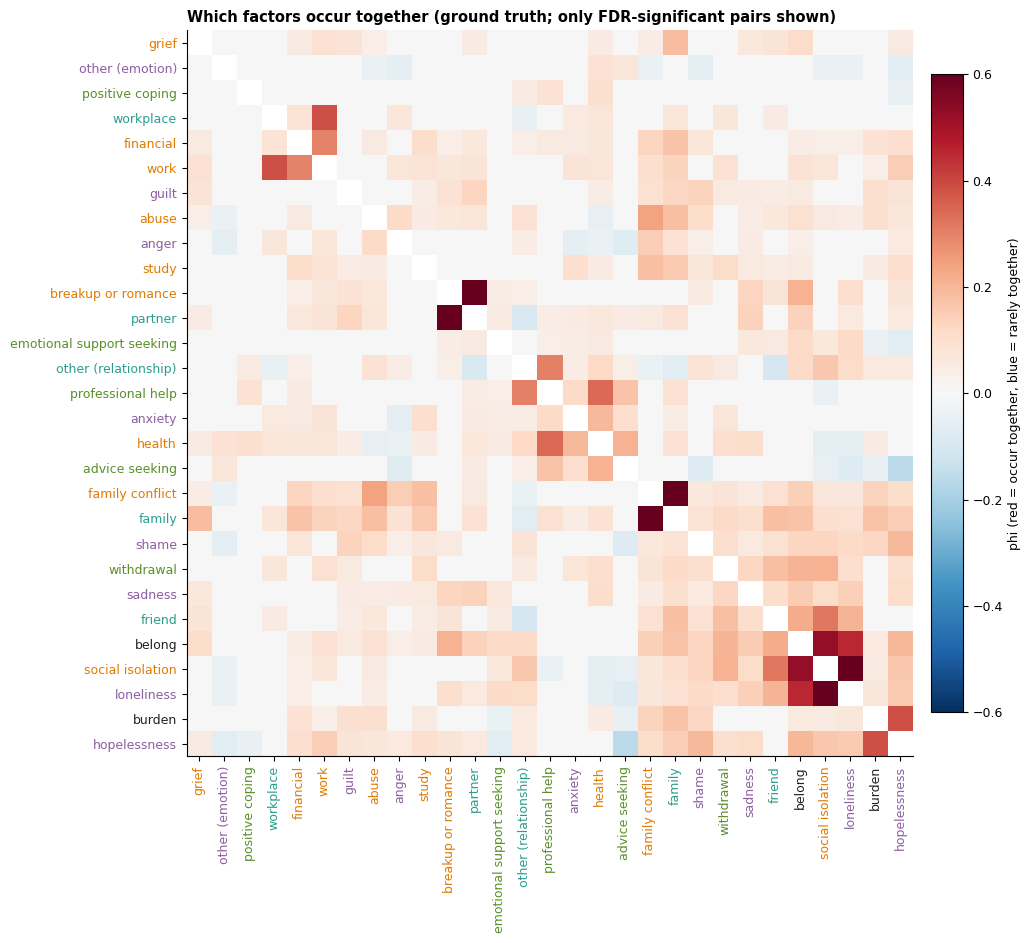

saved F13_cooccurrence_heatmap.png


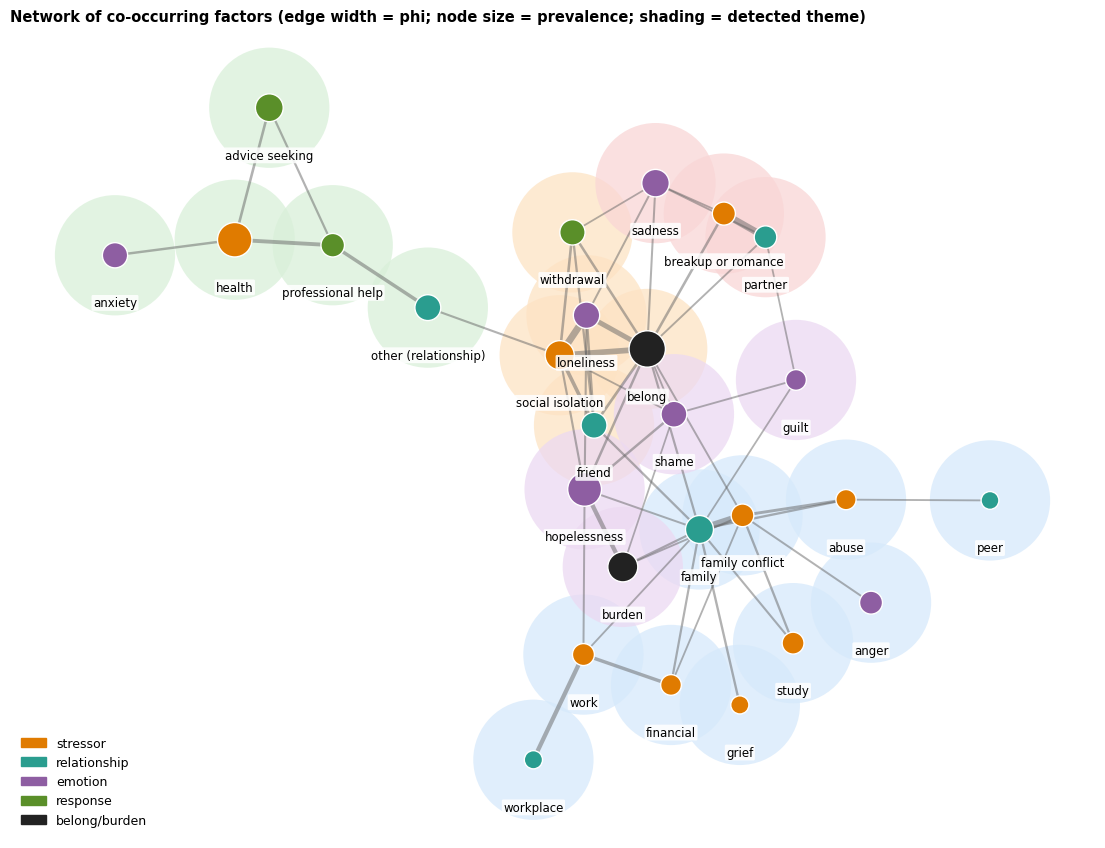

saved F14_cooccurrence_network.png


In [ ]:
# ---------------- F13 co-occurrence heatmap + F14 network
pw = R["pairs"]; cols_, D, Z, order = label_clusters(X, min_count=100)
phi = pd.DataFrame(0.0, index=order, columns=order)
for r in pw.itertuples():
    if r.item_a in phi.index and r.item_b in phi.index and r.q_fdr < .05: phi.loc[r.item_a, r.item_b] = r.phi; phi.loc[r.item_b, r.item_a] = r.phi
arr = phi.to_numpy().copy(); np.fill_diagonal(arr, np.nan); fig, ax = plt.subplots(figsize=(11, 9.5)); im = ax.imshow(arr, cmap="RdBu_r", vmin=-.6, vmax=.6)
ax.set_xticks(range(len(order))); ax.set_xticklabels([pretty(o) for o in order], rotation=90); ax.set_yticks(range(len(order))); ax.set_yticklabels([pretty(o) for o in order])
_lookup = {pretty(o): o for o in order}
for t in ax.get_xticklabels() + ax.get_yticklabels(): t.set_color(CAT_COL[cat_of[_lookup[t.get_text()]]])
fig.colorbar(im, fraction=.035, pad=.02).set_label("phi (red = occur together, blue = rarely together)")
ax.set_title("Which factors occur together (ground truth; only FDR-significant pairs shown)", loc="left"); fig.tight_layout(); save(fig, "F13_cooccurrence_heatmap.png")

e = pw[(pw.q_fdr < .05) & (pw.phi >= .12)]; Gr = nx.Graph(); [Gr.add_edge(r.item_a, r.item_b, weight=r.phi, dist=1.05 - r.phi) for r in e.itertuples()]
comms = sorted(nx.community.louvain_communities(Gr, weight="weight", seed=3), key=len, reverse=True)
pos = nx.kamada_kawai_layout(Gr, weight="dist"); pos = {k: np.array(v) * 1.15 for k, v in pos.items()}
comm_cols = ["#d6e9fb", "#fde3c4", "#d9f0d9", "#ecd9f2", "#f9d6d6", "#e6e6e6"]; fig, ax = plt.subplots(figsize=(14, 10.5)); ax.axis("off")
for c, cc in zip(comms, comm_cols):
    pts = np.array([pos[n] for n in c]); ax.scatter(pts[:, 0], pts[:, 1], s=7500, color=cc, zorder=0, alpha=.75, edgecolor="none")
for u, v, dta in Gr.edges(data=True): ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#666", lw=.4 + 7 * dta["weight"], alpha=.5, zorder=1)
sizes = {n: 140 + 1000 * X[n].mean() for n in Gr.nodes}
ax.scatter([pos[n][0] for n in Gr.nodes], [pos[n][1] for n in Gr.nodes], s=[sizes[n] for n in Gr.nodes], c=[CAT_COL[cat_of[n]] for n in Gr.nodes], edgecolor="white", zorder=2)
for n in Gr.nodes:
    ax.text(pos[n][0], pos[n][1] - .075, pretty(n), ha="center", va="top", fontsize=8.5, zorder=3, bbox=dict(boxstyle="round,pad=.12", fc="white", ec="none", alpha=.85))
ax.margins(.12); ax.legend(handles=[Patch(color=v, label=k) for k, v in CAT_COL.items()], frameon=False, loc="lower left")
ax.set_title("Network of co-occurring factors (edge width = phi; node size = prevalence; shading = detected theme)", loc="left"); save(fig, "F14_cooccurrence_network.png")

### Figure 15 – Which stressors go with which emotions, responses and relationships (Q1, Q4)
**What we get:** A lift heatmap with stressors as rows; blank cells are not significant.

**Why we did it:** Lift tells us how many times more often two labels appear together than chance. It links the 'cause' (stressor) side to the emotional and behavioural side.

*Sub-question(s): Q1, Q4*

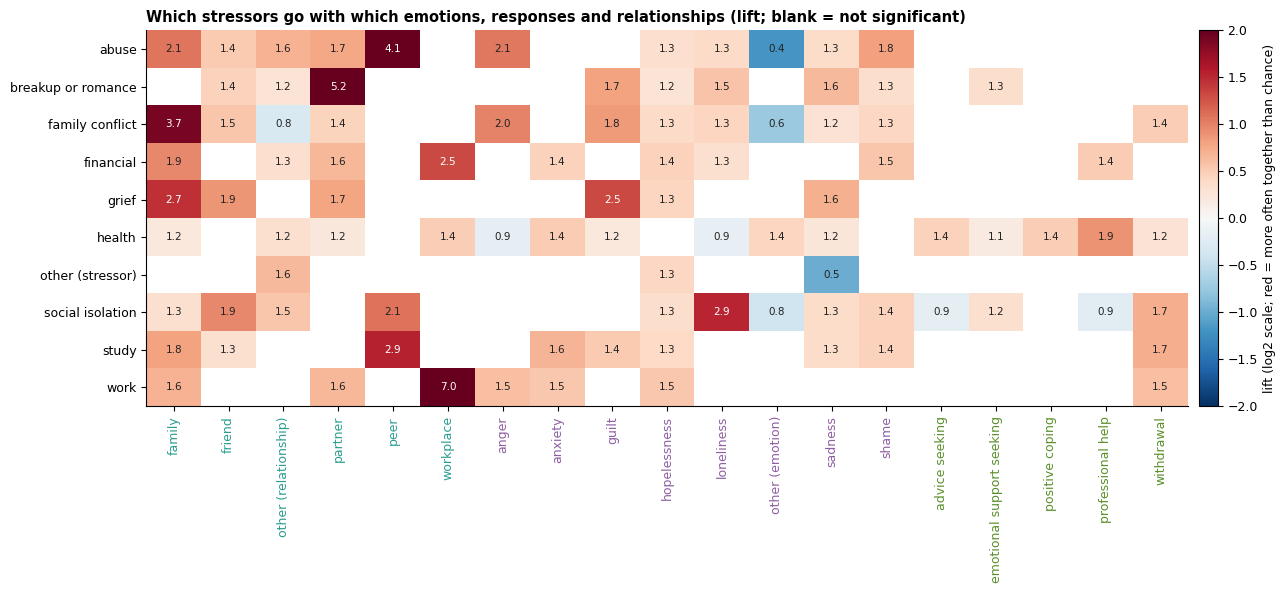

saved F15_stressor_cross_category_lift.png


In [ ]:
# ---------------- F15 cross-category lift
st = [c for c in X.columns if cat_of[c] == "stressor"]; others = [c for c in X.columns if cat_of[c] in ("emotion", "response", "relationship") and X[c].sum() >= 50]
st = [c for c in st if X[c].sum() >= 50]; P = pw.set_index(["item_a", "item_b"]); L = np.full((len(st), len(others)), np.nan); Q = np.ones_like(L)
for i, a in enumerate(st):
    for j, b in enumerate(others):
        r = P.loc[(a, b)] if (a, b) in P.index else (P.loc[(b, a)] if (b, a) in P.index else None)
        if r is not None: L[i, j] = r.lift; Q[i, j] = r.q_fdr
fig, ax = plt.subplots(figsize=(13, 6)); Lm = np.where(Q < .05, np.log2(L), np.nan); im = ax.imshow(Lm, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
for i in range(len(st)):
    for j in range(len(others)):
        if Q[i, j] < .05: ax.text(j, i, f"{L[i, j]:.1f}", ha="center", va="center", fontsize=7.5, color="white" if abs(np.log2(L[i, j])) > 1.2 else "#222")
ax.set_xticks(range(len(others))); ax.set_xticklabels([pretty(o) for o in others], rotation=90); ax.set_yticks(range(len(st))); ax.set_yticklabels([pretty(s) for s in st])
for t, o in zip(ax.get_xticklabels(), others): t.set_color(CAT_COL[cat_of[o]])
fig.colorbar(im, fraction=.03, pad=.01).set_label("lift (log2 scale; red = more often together than chance)")
ax.set_title("Which stressors go with which emotions, responses and relationships (lift; blank = not significant)", loc="left"); fig.tight_layout(); save(fig, "F15_stressor_cross_category_lift.png")

### Figure 16 – How many difficulties a post reports, by age (Q6)
**What we get:** Mean number of labels per category and in total across age groups, with Spearman correlation to age.

**Why we did it:** Tests whether older or younger writers describe more difficulties at once (a 'load' view, instead of one label at a time).

*Sub-question(s): Q6*

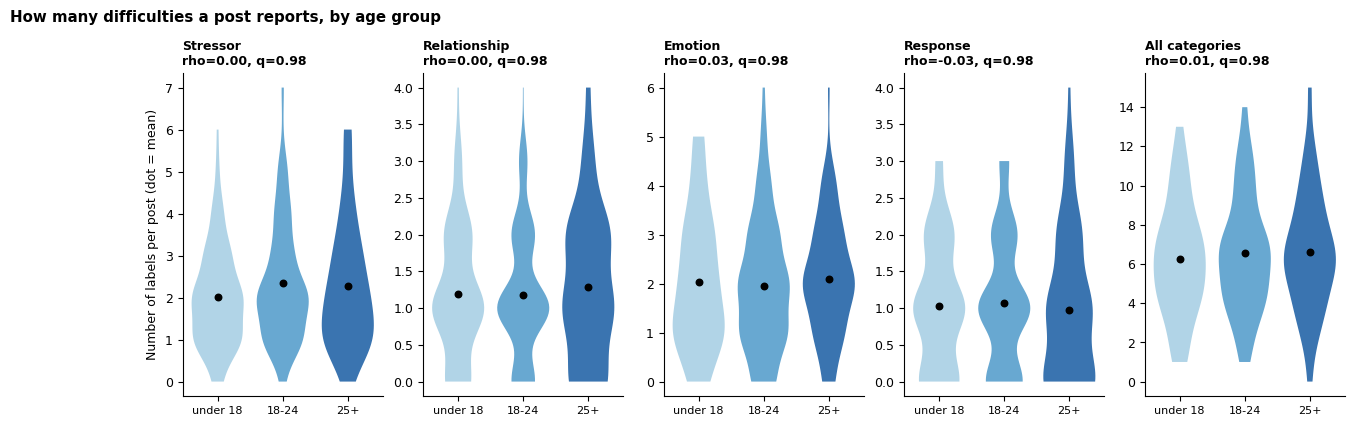

saved F16_label_counts_by_age.png


In [ ]:
# ---------------- F16 label counts by age group
fig, axs = plt.subplots(1, 5, figsize=(15, 4.2), sharey=False); s = d[am]; cc = R["cat_counts"].set_index("indicator")
for ax_, c in zip(axs, CATS + ["total"]):
    v = cnt.loc[am, f"n_{c}"]; data = [v[s.age_bin == g].values for g in AGE_ORDER]
    parts = ax_.violinplot(data, showmeans=False, showextrema=False, widths=.8)
    for pc, g in zip(parts["bodies"], AGE_ORDER): pc.set_facecolor(AGE_COL[g]); pc.set_alpha(.8)
    ax_.scatter(range(1, 4), [x.mean() for x in data], color="k", zorder=3, s=22); ax_.set_xticks([1, 2, 3]); ax_.set_xticklabels(AGE_ORDER, fontsize=8)
    r_ = cc.loc[f"number of {c} labels"]; ax_.set_title(f"{c.capitalize() if c != 'total' else 'All categories'}\nrho={r_.spearman_rho_age:.2f}, q={r_.q_spearman:.2f}", loc="left", fontsize=9)
axs[0].set_ylabel("Number of labels per post (dot = mean)")
fig.suptitle("How many difficulties a post reports, by age group", x=.01, ha="left", fontweight="bold", y=1.03); save(fig, "F16_label_counts_by_age.png")

### Figure 17 – Belonging and burden overlap differently by age (Q9, Q11)
**What we get:** Left: burden rate among posts with vs without thwarted belonging, by age group. Right: where the four-way age difference comes from (residual heatmap).

**Why we did it:** Explains why the four-way pattern differs by age even when TBe and PBu individually do not. It localises the effect.

*Sub-question(s): Q9, Q11*

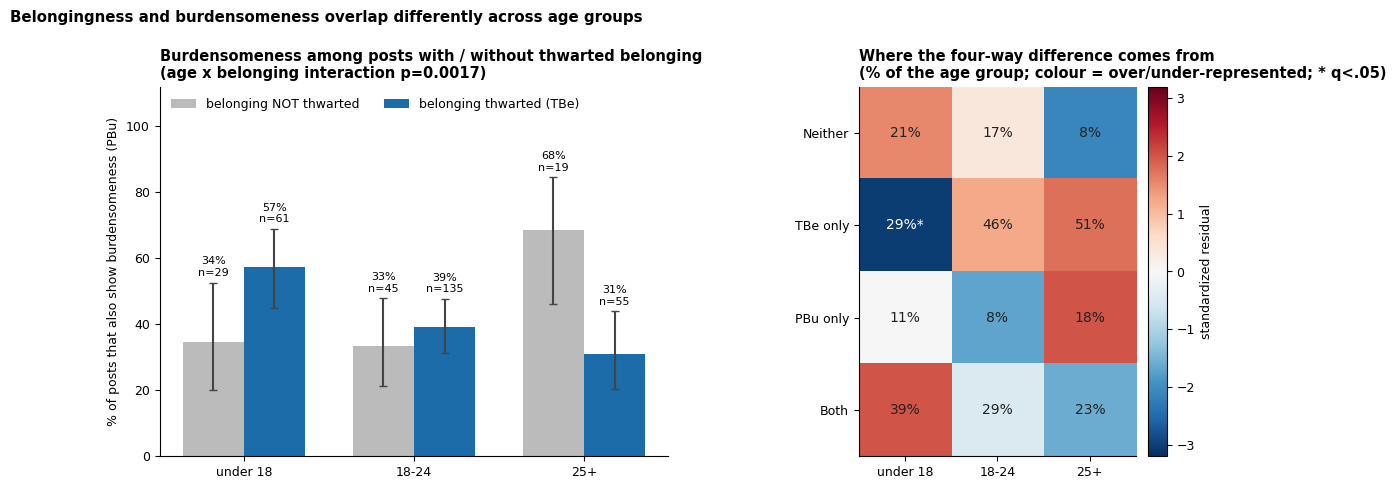

saved F17_belong_burden_overlap_by_age.png


In [ ]:
# ---------------- F17 burden by belonging status within age group
ov = R["belong_burden_overlap"]; fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[1.25, 1]))
w = .36; x = np.arange(3)
for off, flag, col, lab in ((-w / 2, 0, "#bbbbbb", "belonging NOT thwarted"), (w / 2, 1, "#1b6ca8", "belonging thwarted (TBe)")):
    vals, los, his, ns = [], [], [], []
    for g in AGE_ORDER:
        m = (d.age_bin == g) & (X.belong == flag); k = int(X.loc[m, "burden"].sum()); n = int(m.sum()); l, h = wil(k, n); vals.append(100 * k / n); los.append(l); his.append(h); ns.append(n)
    ax[0].bar(x + off, vals, w, color=col, label=lab, yerr=[np.array(vals) - np.array(los), np.array(his) - np.array(vals)], capsize=3, ecolor="#444")
    for xi, v, n_, h in zip(x + off, vals, ns, his): ax[0].text(xi, h + 2, f"{v:.0f}%\nn={n_}", ha="center", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels(AGE_ORDER); ax[0].set_ylim(0, 112); ax[0].set_ylabel("% of posts that also show burdensomeness (PBu)"); ax[0].legend(frameon=False, loc="upper left", ncol=2)
ax[0].set_title("Burdensomeness among posts with / without thwarted belonging\n(age x belonging interaction p=%.4f)" % R["belong_burden_interaction_p"], loc="left")
cells = R["group_age_cells"]; piv = cells.pivot(index="group", columns="age_group", values="std_residual").reindex(index=["Neither", "TBe only", "PBu only", "Both"], columns=AGE_ORDER)
q = cells.pivot(index="group", columns="age_group", values="q_fdr").reindex(index=piv.index, columns=AGE_ORDER); pc = cells.pivot(index="group", columns="age_group", values="pct_in_age_group").reindex(index=piv.index, columns=AGE_ORDER)
im = ax[1].imshow(piv.values, cmap="RdBu_r", vmin=-3.2, vmax=3.2)
for i in range(4):
    for j in range(3): ax[1].text(j, i, f"{pc.values[i, j]:.0f}%{stars(q.values[i, j])}", ha="center", va="center", fontsize=10, color="white" if abs(piv.values[i, j]) > 2.2 else "#222")
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(AGE_ORDER); ax[1].set_yticks(range(4)); ax[1].set_yticklabels(piv.index); fig.colorbar(im, fraction=.046, pad=.03).set_label("standardized residual")
ax[1].set_title("Where the four-way difference comes from\n(% of the age group; colour = over/under-represented; * q<.05)", loc="left")
fig.suptitle("Belongingness and burdensomeness overlap differently across age groups", x=.01, ha="left", fontweight="bold", y=1.04); save(fig, "F17_belong_burden_overlap_by_age.png")

## 5. Other demographics (D01–D06): students, employed, unemployed, partner, parent, mental health
Groups are built by regex from `text_clean`. *Stated* = explicit first-person statement (e.g. "I'm a student"); *likely* = inferred from words such as "my boss"/"my exams". Because "likely" groups overlap with the work/study/partner labels, the label that defines a group is excluded from that group's factor comparison.

In [ ]:
def build_groups(d, X, cat_of):
    rows = [extract_demographics(t) for t in d["text_clean"]]
    dem = pd.DataFrame([r[0] for r in rows]); ev = [r[1] for r in rows]
    G = pd.DataFrame(index=d.index)
    es, emp, rel, par, mh, liv = dem.student_status.fillna(""), dem.employment_status.fillna(""), dem.relationship_status.fillna(""), dem.parent_status.fillna(""), dem.mental_health_conditions.fillna(""), dem.living_situation.fillna("")
    # explicit (self-statement) groups vs inferred-from-mention groups
    G["student_explicit"] = es.str.startswith("student").astype(int)
    G["student_likely_only"] = (es == "likely student").astype(int)
    G["employed_explicit"] = (emp == "employed").astype(int)
    G["employed_likely_only"] = (emp == "likely employed").astype(int)
    G["unemployed_or_job_loss"] = emp.str.startswith("unemployed").astype(int)
    G["retired"] = (emp == "retired").astype(int)
    G["relationship_status_stated"] = rel.isin(["single", "married", "divorced", "separated", "widowed", "engaged"]).astype(int)
    G["single_stated"] = (rel == "single").astype(int)
    G["married_or_engaged_stated"] = rel.isin(["married", "engaged"]).astype(int)
    G["spouse_mentioned"] = (rel == "married/engaged (mentioned spouse)").astype(int)
    G["partner_mentioned"] = (rel == "in a relationship (mentioned partner)").astype(int)
    G["any_partner_or_spouse_mentioned"] = rel.str.contains("mentioned").astype(int)
    G["parent"] = (par == "parent").astype(int)
    G["mh_any"] = (mh != "").astype(int)
    for c in ["depression", "anxiety", "bipolar", "ADHD", "PTSD", "autism", "BPD", "OCD", "eating disorder"]:
        G[f"mh_{c}"] = mh.str.contains(c, regex=False).astype(int)
    G["mh_diagnosed"] = mh.str.contains("diagnosed").astype(int)
    G["lives_with_parents_family"] = liv.str.contains("parents/family").astype(int)
    G["lives_alone"] = liv.str.contains("alone").astype(int)
    G["lives_with_partner"] = liv.str.contains("partner").astype(int)
    G["dorm_or_homeless"] = liv.str.contains("dorm|homeless").astype(int)
    G["country_stated"] = dem.country_region.notna().astype(int)
    G["orientation_stated"] = dem.sexual_orientation.notna().astype(int)
    return d, X, cat_of, G, dem, ev


d, X, cat_of, G, dem, ev = build_groups(d, X, cat_of)
print(G.sum().to_string())

student_explicit                    32
student_likely_only                122
employed_explicit                   34
employed_likely_only                93
unemployed_or_job_loss              32
retired                              0
relationship_status_stated           5
single_stated                        4
married_or_engaged_stated            1
spouse_mentioned                    50
partner_mentioned                  145
any_partner_or_spouse_mentioned    195
parent                              35
mh_any                             400
mh_depression                      297
mh_anxiety                          87
mh_bipolar                           6
mh_ADHD                              3
mh_PTSD                             10
mh_autism                            8
mh_BPD                               7
mh_OCD                               8
mh_eating disorder                   4
mh_diagnosed                        23
lives_with_parents_family           13
lives_alone              

In [ ]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
# analysis groups (broad = explicit + inferred; explicit-only reported separately)
A = pd.DataFrame(index=d.index)
A["Student (stated or likely)"] = ((G.student_explicit + G.student_likely_only) > 0).astype(int)
A["Employed (stated or likely)"] = ((G.employed_explicit + G.employed_likely_only) > 0).astype(int)
A["Unemployed / job loss"] = G.unemployed_or_job_loss
A["Partner/spouse mentioned"] = G.any_partner_or_spouse_mentioned
A["Parent"] = G.parent
A["Mental-health condition mentioned"] = G.mh_any
A["  depression mentioned"] = G.mh_depression
A["  anxiety mentioned"] = G.mh_anxiety
A["Lives with parents/family"] = G.lives_with_parents_family
# label-defined context groups
A["Work-stressor posts (label)"] = X["stressor: work"] if "stressor: work" in X else 0
A["Study-stressor posts (label)"] = X["stressor: study"] if "stressor: study" in X else 0
A["Partner-relationship posts (label)"] = X["relationship: partner"] if "relationship: partner" in X else 0
# labels trivially tied to each group (excluded from its factor comparison)
trivial = {"Student (stated or likely)": ["stressor: study"], "Employed (stated or likely)": ["stressor: work"], "Unemployed / job loss": ["stressor: work"],
           "Partner/spouse mentioned": ["relationship: partner"], "Parent": ["relationship: family"],
           "Work-stressor posts (label)": ["stressor: work"], "Study-stressor posts (label)": ["stressor: study"], "Partner-relationship posts (label)": ["relationship: partner"]}
def test(m, y):
    a = int((m & y).sum()); b = int((m & ~y).sum()); c = int((~m & y).sum()); dd = int((~m & ~y).sum())
    orr = ((a+.5)*(dd+.5))/((b+.5)*(c+.5)); se = np.sqrt(1/(a+.5)+1/(b+.5)+1/(c+.5)+1/(dd+.5))
    p = fisher_exact([[a,b],[c,dd]])[1]
    return dict(n_group=int(m.sum()), pct_group=100*a/max(m.sum(),1), pct_rest=100*c/max((~m).sum(),1), OR=orr, lo=np.exp(np.log(orr)-1.96*se), hi=np.exp(np.log(orr)+1.96*se), p=p)
res = []
for g in A:
    m = A[g].astype(bool)
    for f in X.columns:
        if f in trivial.get(g, []): continue
        r = test(m, X[f].astype(bool)); r.update(group=g.strip(), factor=f, kind="belong/burden" if f in ("belong","burden") else "factor"); res.append(r)
RD = pd.DataFrame(res)
RD["q"] = np.nan
for k, s in RD.groupby("kind"): RD.loc[s.index, "q"] = multipletests(s.p, method="fdr_bh")[1]
RD["sig"] = RD.q < .05
bb = RD[RD.kind == "belong/burden"]; # composition
comp = []
for g in A:
    m = A[g].astype(bool)
    comp.append(dict(group=g.strip(), n=int(m.sum()), age_known=int(d.age_num[m].notna().sum()), median_age=d.age_num[m].median(),
        pct_under18=100*(d.age_bin[m]=="under 18").sum()/max(d.age_bin[m].notna().sum(),1), pct_25plus=100*(d.age_bin[m]=="25+").sum()/max(d.age_bin[m].notna().sum(),1),
        gender_known=int(d.gender_known[m].notna().sum()), n_male=int((d.gender_known[m]=="Male").sum()), n_female=int((d.gender_known[m]=="Female").sum())))
C = pd.DataFrame(comp); display(C.round(1))
# top lifts within context groups

,group,n,age_known,median_age,pct_under18,pct_25plus,gender_known,n_male,n_female
0,Student (stated or likely),154,24,17.5,50.0,4.2,5,4,1
1,Employed (stated or likely),127,23,23.0,0.0,43.5,4,2,2
2,Unemployed / job loss,32,11,21.0,0.0,18.2,1,1,0
3,Partner/spouse mentioned,195,25,22.0,12.0,32.0,13,8,5
4,Parent,35,8,27.0,0.0,87.5,4,1,3
5,Mental-health condition mentioned,400,68,20.5,32.4,19.1,20,12,7
6,depression mentioned,297,47,19.0,34.0,19.1,14,8,6
7,anxiety mentioned,87,12,21.5,33.3,33.3,5,3,2
8,Lives with parents/family,13,6,22.5,0.0,33.3,1,1,0
9,Work-stressor posts (label),389,68,23.0,1.5,36.8,14,10,3


In [ ]:
import matplotlib.pyplot as plt
plt.rcdefaults()  # reset styling used by F01-F17
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, os

def save_dem(name):
    plt.savefig(f'{out}/{name}.png', dpi=170); plt.show(); plt.close()
from statsmodels.stats.proportion import proportion_confint
out = OUT_DEM.rstrip("/")
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.spines.top":False,"axes.spines.right":False})
BL, BU, GR = "#2a6f97", "#c1440e", "#9a9a9a"
order = list(C.group)
print('ready')

ready


### Figure D1 – Which demographic groups can we study? (Q18)
**What we get:** The number of posts in each regex-derived group (students, employed, unemployed, partner mentioned, parent, mental-health condition, ...) and in each label-defined group (work, study, partner-relationship posts).

**Why we did it:** Group size decides what can be tested. Small explicit groups limit power, so we also use broader groups (stated + likely).

*Sub-question(s): Q18*

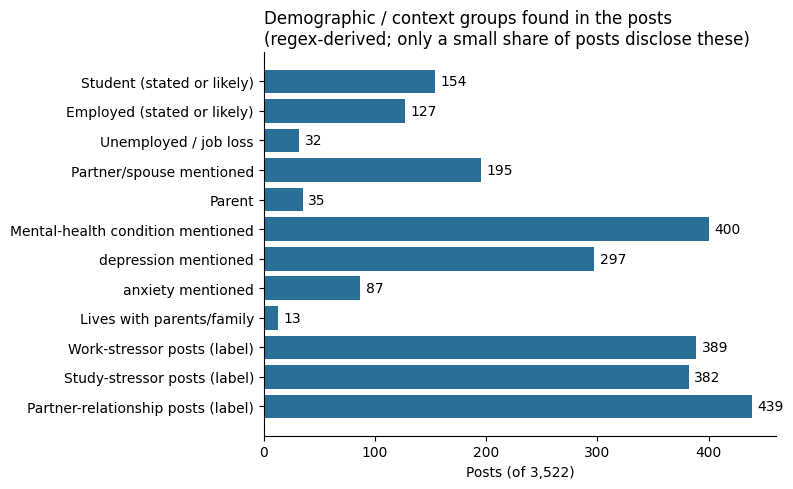

In [ ]:
# F1 sizes
fig, ax = plt.subplots(figsize=(8,5)); y=np.arange(len(C))[::-1]
ax.barh(y, C.n, color=BL); ax.set_yticks(y); ax.set_yticklabels(C.group)
for yi,n in zip(y,C.n): ax.text(n+5, yi, str(n), va="center")
ax.set_xlabel("Posts (of 3,522)"); ax.set_title("Demographic / context groups found in the posts\n(regex-derived; only a small share of posts disclose these)", loc="left")
plt.tight_layout(); save_dem("D01_group_sizes")

### Figure D2 – Belonging and burden by demographic group (Q18)
**What we get:** For each group, the % of posts with TBe (left) and PBu (right) with Wilson CIs, against the rest of the posts (grey bar); * = FDR q<0.05.

**Why we did it:** Directly answers 'do employed people, students, partnered people, ... differ in TBe and PBu?'

*Sub-question(s): Q18*

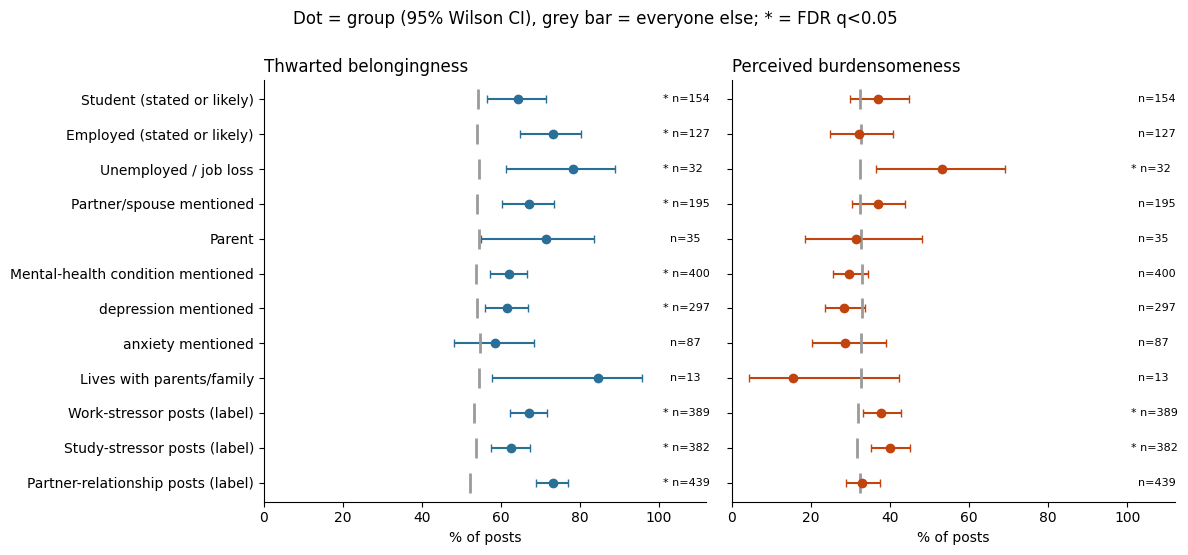

In [ ]:
# F2 prevalence belong/burden
bb = RD[RD.kind=="belong/burden"]
fig, axs = plt.subplots(1,2, figsize=(12,5.5), sharey=True)
for ax, f, col, nm in [(axs[0],"belong",BL,"Thwarted belongingness"),(axs[1],"burden",BU,"Perceived burdensomeness")]:
    s = bb[bb.factor==f].set_index("group").loc[order]; y=np.arange(len(s))[::-1]
    for yi,(g,r) in zip(y, s.iterrows()):
        k=round(r.pct_group*r.n_group/100); lo,hi=proportion_confint(k,r.n_group,method="wilson")
        ax.errorbar(r.pct_group, yi, xerr=[[r.pct_group-100*lo],[100*hi-r.pct_group]], fmt="o", color=col, capsize=3)
        ax.plot(r.pct_rest, yi, "|", color=GR, ms=14, mew=2)
        ax.text(101, yi, ("* " if r.q<.05 else "  ")+f"n={int(r.n_group)}", va="center", fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlim(0,112); ax.set_xlabel("% of posts"); ax.set_title(nm, loc="left")
fig.suptitle("Dot = group (95% Wilson CI), grey bar = everyone else; * = FDR q<0.05", y=1.0)
plt.tight_layout(); save_dem("D02_belong_burden_by_group")

### Figure D3 – Effect sizes for TBe and PBu by group (Q18)
**What we get:** Odds ratios (log scale) vs everyone else with 95% CIs for belong and burden.

**Why we did it:** Odds ratios show effect size and uncertainty on one scale, so we can see which differences are large and which merely 'reach significance'.

*Sub-question(s): Q18*

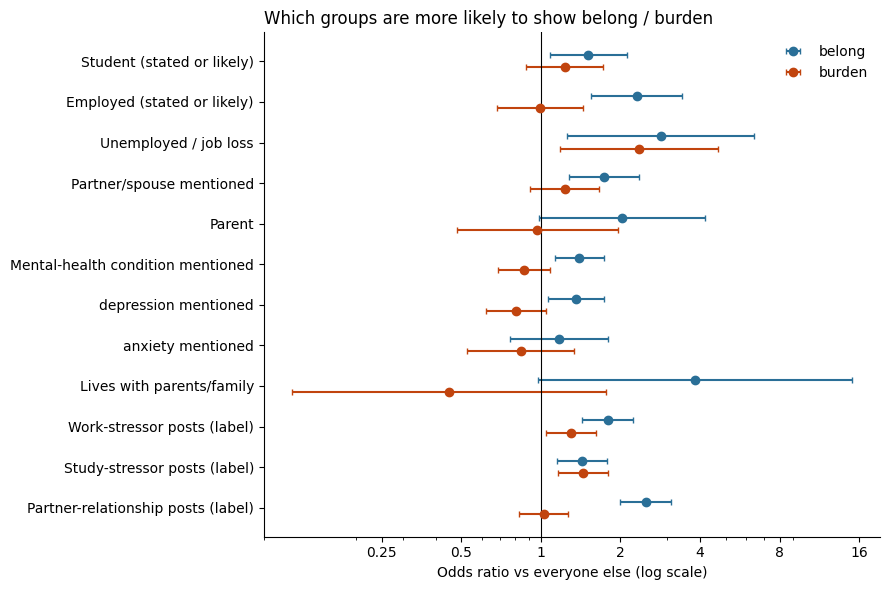

In [ ]:
# F3 forest ORs belong/burden
fig, ax = plt.subplots(figsize=(9,6)); y=0; yt=[]; yl=[]
for f,col,off in [("belong",BL,.15),("burden",BU,-.15)]:
    s = bb[bb.factor==f].set_index("group").loc[order]
    yy=np.arange(len(s))[::-1]+off
    ax.errorbar(s.OR, yy, xerr=[s.OR-s.lo, s.hi-s.OR], fmt="o", color=col, capsize=2, label=f)
ax.axvline(1,color="k",lw=.8); ax.set_xscale("log"); ax.set_xticks([.25,.5,1,2,4,8,16]); ax.set_xticklabels(["0.25","0.5","1","2","4","8","16"])
ax.set_yticks(np.arange(len(order))[::-1]); ax.set_yticklabels(order); ax.legend(frameon=False)
ax.set_xlabel("Odds ratio vs everyone else (log scale)"); ax.set_title("Which groups are more likely to show belong / burden", loc="left")
plt.tight_layout(); save_dem("D03_odds_ratios")

### Figure D4 – What each group talks about (Q18, Q19)
**What we get:** A heatmap of the % of each group's posts that contain each of the 32 factors; stars = FDR-significant vs rest. Cells for the label that defines the group are left blank.

**Why we did it:** Describes the profile of each group (e.g. employed people and workplace relationships, students and peers) and excludes circular comparisons.

*Sub-question(s): Q18, Q19*

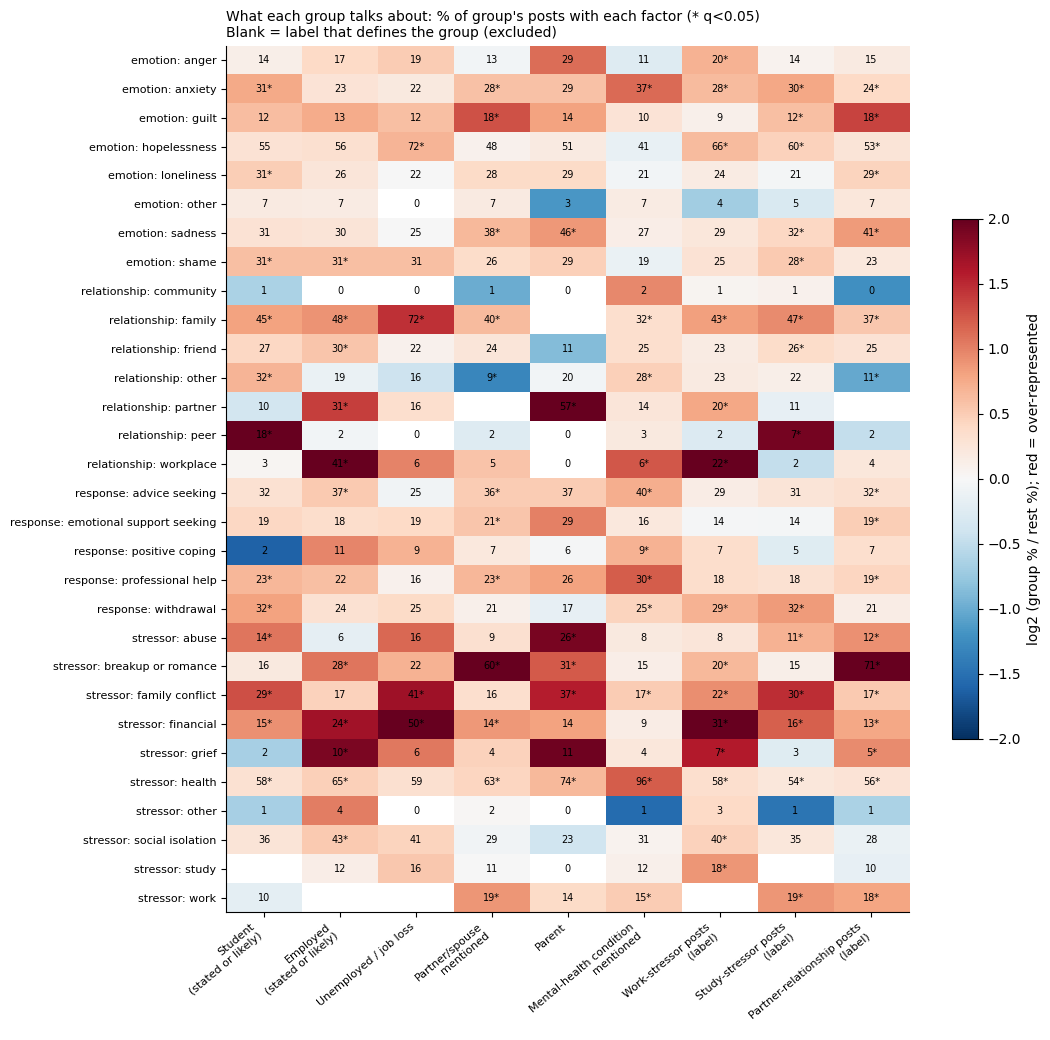

In [ ]:
# F4 heatmap of lift
F = RD[RD.kind=="factor"].copy(); F["lift"]=F.pct_group/F.pct_rest.replace(0,np.nan)
main=["Student (stated or likely)","Employed (stated or likely)","Unemployed / job loss","Partner/spouse mentioned","Parent","Mental-health condition mentioned","Work-stressor posts (label)","Study-stressor posts (label)","Partner-relationship posts (label)"]
F=F[F.group.isin(main)]
M=F.pivot(index="factor",columns="group",values="pct_group").reindex(columns=main)
Q=F.pivot(index="factor",columns="group",values="q").reindex(columns=main)
Rest=F.pivot(index="factor",columns="group",values="pct_rest").reindex(columns=main)
L=np.log2((M/Rest).astype(float))
fig, ax = plt.subplots(figsize=(11,10.5))
im=ax.imshow(L.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(main))); ax.set_xticklabels([m.replace(" (","\n(").replace(" mentioned","\nmentioned") for m in main], rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(L))); ax.set_yticklabels(L.index, fontsize=8)
for i in range(L.shape[0]):
    for j in range(L.shape[1]):
        v=M.values[i,j]
        if not np.isnan(v): ax.text(j,i,f"{v:.0f}"+("*" if Q.values[i,j]<.05 else ""),ha="center",va="center",fontsize=7,color="k")
plt.colorbar(im, label="log2 (group % / rest %); red = over-represented", shrink=.6)
ax.set_title("What each group talks about: % of group's posts with each factor (* q<0.05)\nBlank = label that defines the group (excluded)", loc="left", fontsize=10)
plt.tight_layout(); save_dem("D04_factor_heatmap")

### Figure D5 – Who is in each group? (Q18)
**What we get:** Median stated age for each group.

**Why we did it:** Group differences might simply reflect age. This shows how the groups differ in age composition (age is known for only a few members).

*Sub-question(s): Q18, Q20*

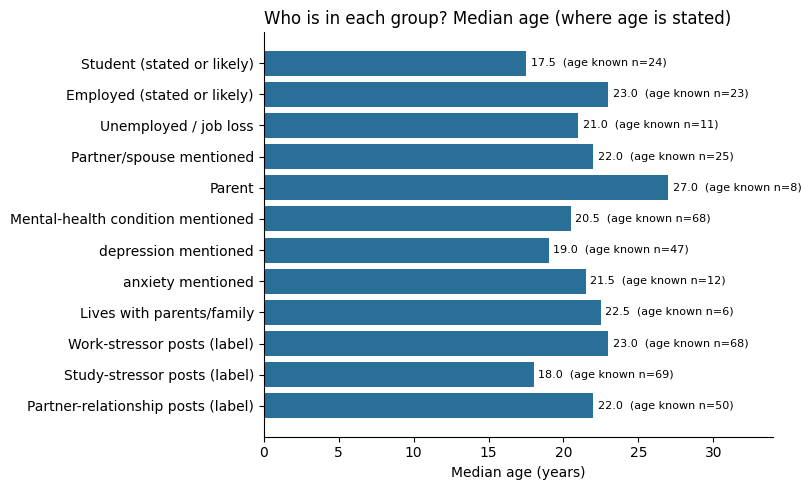

In [ ]:
# F5 age composition
fig, ax = plt.subplots(figsize=(8,5)); s=C[C.age_known>=5]; y=np.arange(len(s))[::-1]
ax.barh(y, s.median_age, color=BL)
for yi,(g,r) in zip(y,s.iterrows()): ax.text(r.median_age+.3, yi, f"{r.median_age:.1f}  (age known n={r.age_known})", va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(s.group); ax.set_xlabel("Median age (years)"); ax.set_xlim(0,34)
ax.set_title("Who is in each group? Median age (where age is stated)", loc="left")
plt.tight_layout(); save_dem("D05_group_age")

### Figure D6 – The most distinctive factors per group (Q18)
**What we get:** For each group, the five factors with the strongest significant over-representation.

**Why we did it:** A quick summary of what is characteristic of each group.

*Sub-question(s): Q18*

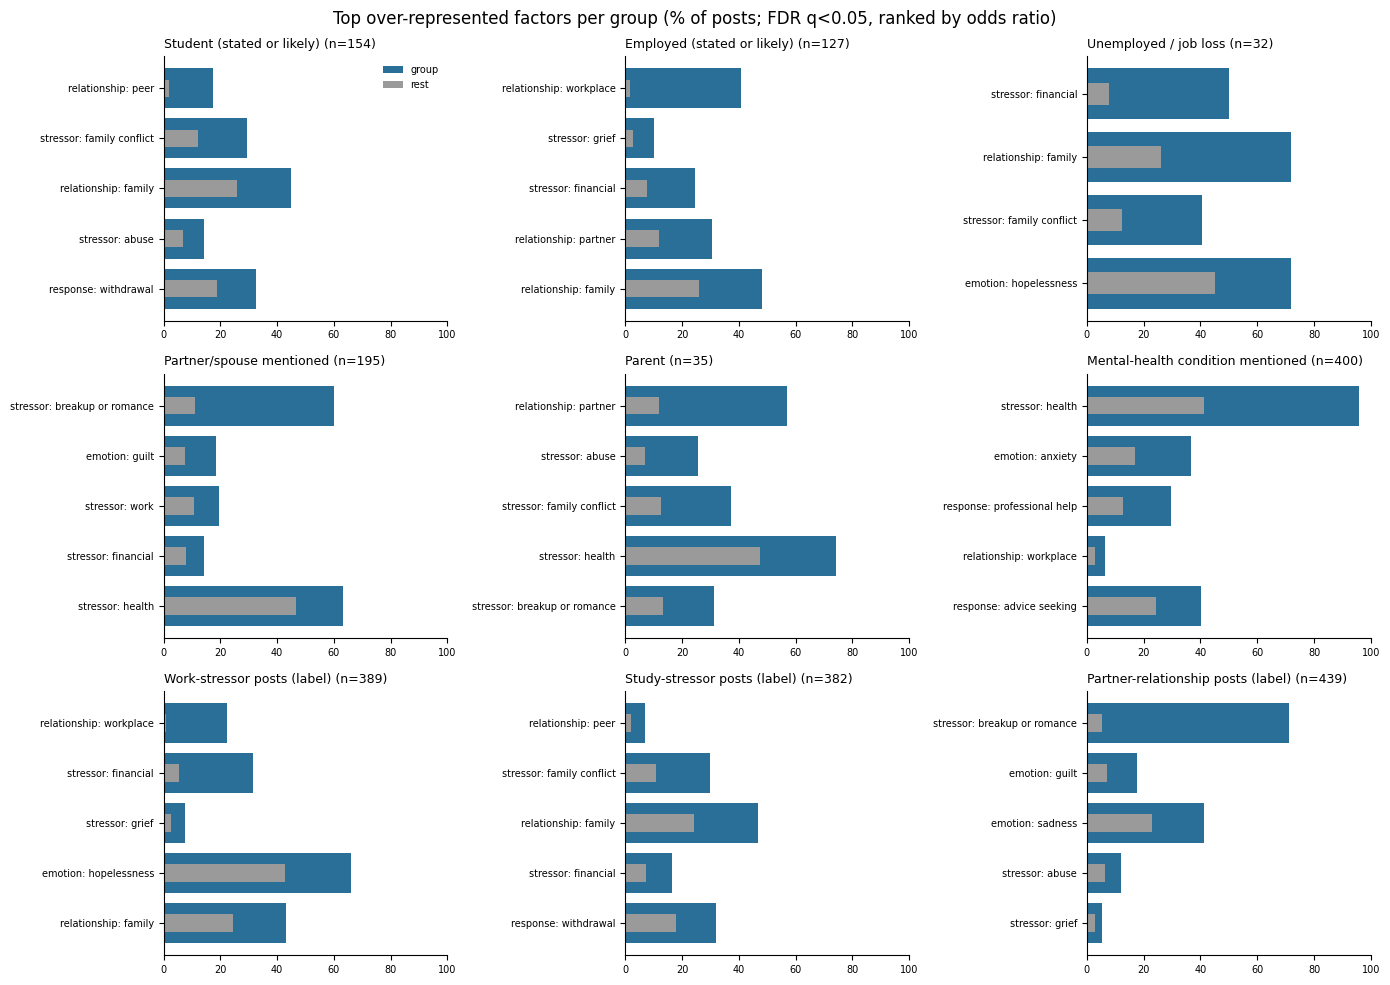

In [ ]:
# F6 top 5 factors per group
fig, axs = plt.subplots(3,3, figsize=(14,10));
for ax,g in zip(axs.ravel(), main):
    s=F[(F.group==g)&(F.q<.05)&(F.OR>1)].sort_values("OR",ascending=False).head(5).iloc[::-1]
    ax.barh(s.factor, s.pct_group, color=BL, label="group"); ax.barh(s.factor, s.pct_rest, color=GR, height=.35, label="rest")
    ax.set_title(f"{g} (n={int(F[F.group==g].n_group.iloc[0])})", fontsize=9, loc="left"); ax.tick_params(labelsize=7); ax.set_xlim(0,100)
axs[0,0].legend(frameon=False, fontsize=7)
fig.suptitle("Top over-represented factors per group (% of posts; FDR q<0.05, ranked by odds ratio)")
plt.tight_layout(); save_dem("D06_top_factors")

## 6. Extra analyses – answering the remaining sub-questions
The earlier figures cover most of the age/gender and group-difference questions. The figures below add the sub-questions that needed new views: association rules (Q2), conditional "pathways" (Q4), mutually exclusive factors (Q5), difficulty load (Q6), factors linked to belong/burden (Q7, Q8), age×gender interaction (Q17), co-occurrence by group (Q19), adjusted multivariable model (Q20), robustness (Q21) and representativeness (Q22).
All use the same data (`X`, `d`) and demographic groups (`G`, `A`) built above.

In [ ]:
OUT_S = "outputs/extra/figures/"; os.makedirs(OUT_S, exist_ok=True)
def save_s(fig, name):
    fig.savefig(OUT_S + name, dpi=170, bbox_inches="tight", facecolor="white"); plt.show(); plt.close(fig); print("saved", name)
from scipy.stats import fisher_exact, chi2 as _chi2, chi2_contingency
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 10.5})
CATC = {"stressor": "#e07b00", "relationship": "#2a9d8f", "emotion": "#8e5ea2", "response": "#5a8f29", "belong/burden": "#222222"}
def cat1(c): return c.split(":")[0] if ":" in c else "belong/burden"
def short(c): return ("other (" + c.split(": ")[0] + ")") if c.endswith(": other") else (c.split(": ")[-1] if ": " in c else c)
from matplotlib.ticker import NullFormatter
def clean_log(ax): ax.xaxis.set_minor_formatter(NullFormatter())
TAG = {"stressor": "stressor", "relationship": "rel.", "emotion": "emotion", "response": "resp."}
def tshort(c): return short(c) if ":" not in c else f"{short(c)} ({TAG[cat1(c)]})"
def or_ci(a, b, c, dd):
    a, b, c, dd = a + .5, b + .5, c + .5, dd + .5; o = a * dd / (b * c); se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / dd)
    return o, o * np.exp(-1.96 * se), o * np.exp(1.96 * se)
print("ready")

ready


### Figure S1 – Frequent multi-factor patterns (market-basket / association rules) (Q2)
**What we get:** left, every Apriori rule plotted by support (how often the pattern occurs) and confidence (how often the right side follows the left), coloured by lift; right, the 15 rules with the highest lift.
**Why we did it:** pairwise tests only look at two factors. Association rules reveal combinations of 2-3 factors (e.g. "breakup + partner → sadness"). Read them as *co-occurrence*, not as cause and effect. Posts are written all at once, so "A → B" has no time order.

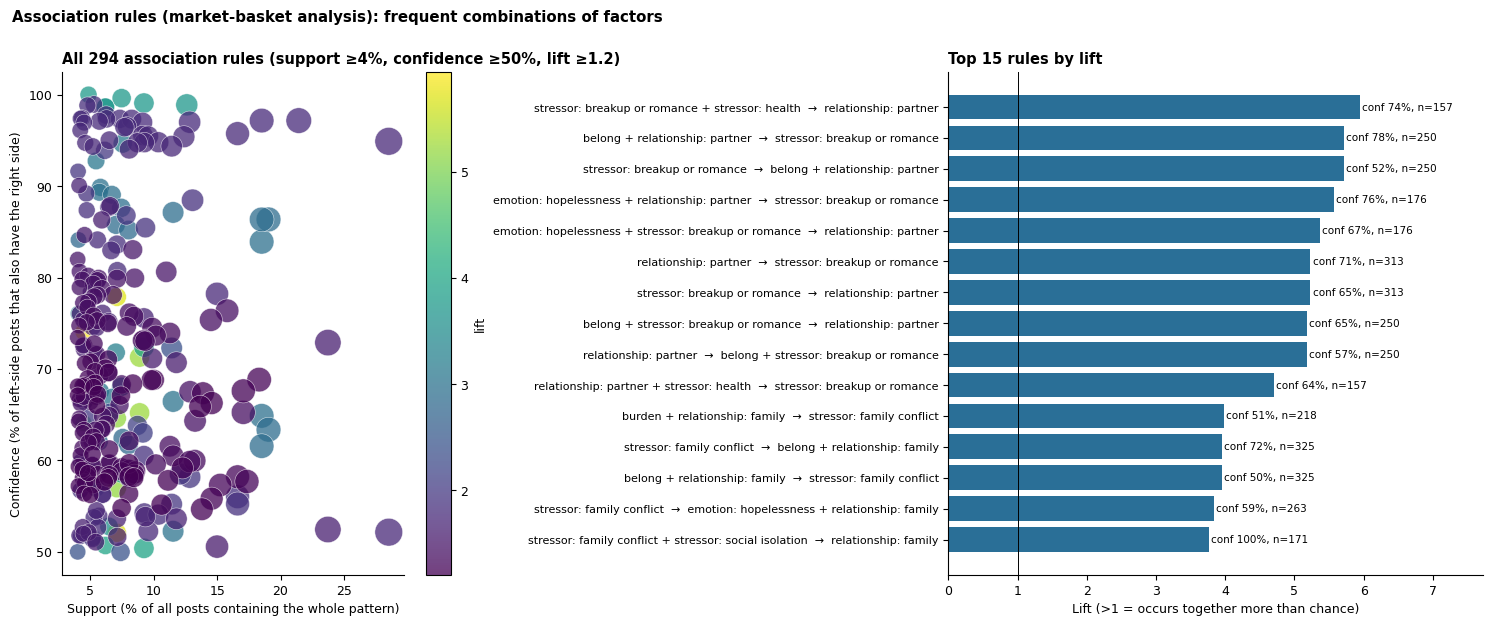

saved S01_association_rules.png


In [ ]:
ru = R["rules"].copy(); N = len(X)
ru["n_rule"] = (ru.support * N).round().astype(int)
fig, ax = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.25]})
sc = ax[0].scatter(100 * ru.support, 100 * ru.confidence, c=ru.lift, s=20 + 6 * ru.n_rule ** .6, cmap="viridis", alpha=.75, edgecolor="white", lw=.4)
plt.colorbar(sc, ax=ax[0], label="lift"); ax[0].set_xlabel("Support (% of all posts containing the whole pattern)"); ax[0].set_ylabel("Confidence (% of left-side posts that also have the right side)")
ax[0].set_title(f"All {len(ru)} association rules (support ≥4%, confidence ≥50%, lift ≥1.2)", loc="left")
top = ru.sort_values(["lift", "confidence"], ascending=False).head(15).iloc[::-1]
def _nm(side):
    out = []
    for part in side.split(' + '):
        hit = [c for c in X.columns if short(c) == part.strip()]
        out.append(tshort(hit[0]) if len(hit) == 1 else part.strip())
    return ' + '.join(out)
lab = [f"{_nm(r.antecedents)}  →  {_nm(r.consequents)}" for r in top.itertuples()]
ax[1].barh(range(len(top)), top.lift, color="#2a6f97"); ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels(lab, fontsize=8)
for i, r in enumerate(top.itertuples()): ax[1].text(r.lift + .03, i, f"conf {100*r.confidence:.0f}%, n={r.n_rule}", va="center", fontsize=7.5)
ax[1].set_xlim(0, top.lift.max() * 1.3); ax[1].axvline(1, color="k", lw=.7); ax[1].set_xlabel("Lift (>1 = occurs together more than chance)"); ax[1].set_title("Top 15 rules by lift", loc="left")
fig.suptitle("Association rules (market-basket analysis): frequent combinations of factors", x=.01, ha="left", fontweight="bold", y=1.0); fig.tight_layout(); save_s(fig, "S01_association_rules.png")

### Visualizing the Top 10 Association Rules by Lift
We will extract the top 10 rules with the highest lift from our previously mined association rules and present them in a clean, modern visual style.

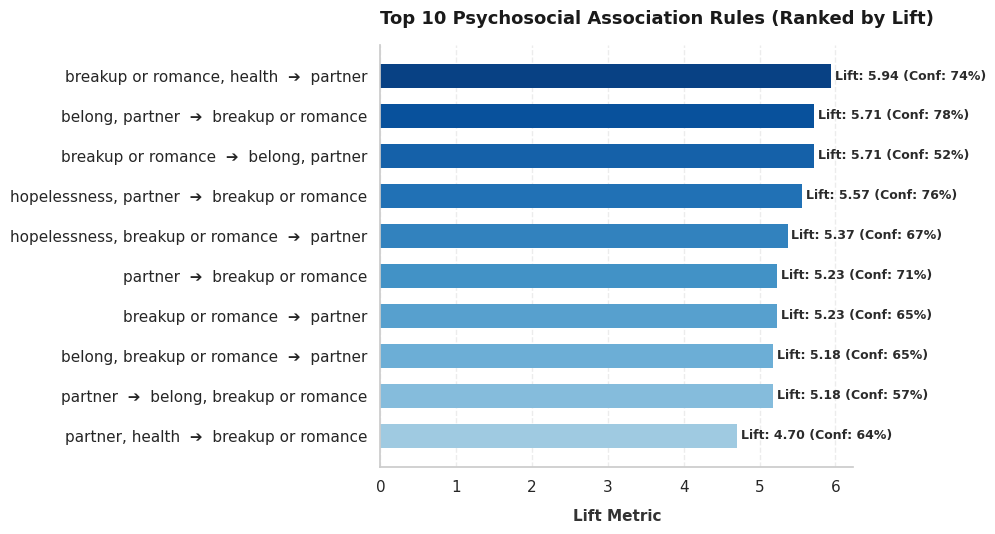

In [ ]:
# =====================================================================
# Figure: Top 10 Psychosocial Association Rules Visualization
# =====================================================================
# =====================================================================
# 1. Clean Label & Rule Formatting Utilities
# =====================================================================
def format_raw_label_name(label_string):
    """Cleans raw column labels, formatting 'other' features to preserve context.

    Example:
        'stressor: work' -> 'work'
        'stressor: other' -> 'other (stressor)'
    """
    if label_string.endswith(": other"):
        category_prefix = label_string.split(": ")[0]
        return f"other ({category_prefix})"

    # Split by colon and take the last element if it exists
    return label_string.split(": ")[-1] if ": " in label_string else label_string


def format_association_rule_label(rule_row):
    """Converts antecedent and consequent itemsets into a user-friendly string representation."""
    antecedent_items = [format_raw_label_name(item) for item in rule_row['antecedents'].split(' + ')]
    consequent_items = [format_raw_label_name(item) for item in rule_row['consequents'].split(' + ')]

    formatted_antecedents = ", ".join(antecedent_items)
    formatted_consequents = ", ".join(consequent_items)
    return f"{formatted_antecedents}  ➔  {formatted_consequents}"

# =====================================================================
# 2. Extract or Reconstruct Association Rules from Registry
# =====================================================================
try:
    # Attempt to retrieve rules directly from the global analysis registry
    target_association_rules = R["rules"].sort_values(by="lift", ascending=False).head(10).copy()
except (NameError, KeyError):
    # Reconstruct the pipeline if execution variables do not exist in the current scope
    ground_truth_files = glob.glob("*ground_truth.csv")
    annotation_files = glob.glob("*Annotated-gender-age.csv")

    if not ground_truth_files or not annotation_files:
        fallback_ground_truth = "/content/drive/MyDrive/Research/Dataminds/Easy version - ground_truth.csv"
        fallback_annotations = "/content/drive/MyDrive/Research/Dataminds/gender_annotations - Annotated-gender-age.csv"
    else:
        fallback_ground_truth = ground_truth_files[0]
        fallback_annotations = annotation_files[0]

    posts_df = pd.read_csv(fallback_ground_truth)
    demographics_df = pd.read_csv(fallback_annotations)

    # Standardize demographic inputs
    demographics_df["gender"] = demographics_df["gender"].astype(str).str.strip().str.capitalize()
    demographics_df["age_num"] = pd.to_numeric(demographics_df["age"], errors="coerce")

    merged_posts = posts_df.merge(
        demographics_df[["post_id", "gender", "age_num"]],
        on="post_id",
        how="left",
        validate="1:1"
    )

    # Initialize binary 1-hot feature matrix
    X_features = pd.DataFrame(index=merged_posts.index)
    X_features["belong"] = merged_posts["belong"].astype(int)
    X_features["burden"] = merged_posts["burden"].astype(int)

    co_occurrence_categories = ["stressors", "relationships", "emotions", "responses"]
    for category in co_occurrence_categories:
        labels_list = merged_posts[category].map(
            lambda cell: [label.strip().lower() for label in str(cell).split(";") if label.strip()]
            if pd.notna(cell) else []
        )

        unique_category_labels = sorted({label for labels in labels_list for label in labels})
        for label in unique_category_labels:
            prefix_name = category[:-1] if category.endswith('s') else category
            feature_column_name = f"{prefix_name}: {label}"
            X_features[feature_column_name] = labels_list.map(lambda labels: int(label in labels))

    # Generate itemsets and mine significant rules
    frequent_itemsets = apriori(X_features.astype(bool), min_support=0.04, use_colnames=True, max_len=3)
    min_confidence_rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

    significant_rules = min_confidence_rules[min_confidence_rules.lift >= 1.2].copy()
    significant_rules["antecedents"] = significant_rules.antecedents.map(lambda s: " + ".join(sorted(s)))
    significant_rules["consequents"] = significant_rules.consequents.map(lambda s: " + ".join(sorted(s)))

    sorted_rules = significant_rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)
    target_association_rules = sorted_rules.head(10).copy()

# =====================================================================
# 3. Apply Formatting & Create Clean Horizontal Plot
# =====================================================================
target_association_rules["rule_label"] = target_association_rules.apply(format_association_rule_label, axis=1)
target_association_rules = target_association_rules.iloc[::-1]  # Invert order for vertical visual ranking

sns.set_theme(style="whitegrid", font="DejaVu Sans")
fig, ax = plt.subplots(figsize=(10, 5.5))

# Retrieve customized aesthetic colors
palette_colors = sns.color_palette("Blues_r", n_colors=15)[:10][::-1]

# Draw horizontal bars
horizontal_bars = ax.barh(
    target_association_rules["rule_label"],
    target_association_rules["lift"],
    color=palette_colors,
    height=0.6,
    edgecolor="none"
)

# Annotate the specific metric parameters next to each bar
for bar, (_, rule_row) in zip(horizontal_bars, target_association_rules.iterrows()):
    bar_width = bar.get_width()
    annotation_text = f"Lift: {rule_row['lift']:.2f} (Conf: {rule_row['confidence']*100:.0f}%)"

    ax.text(
        bar_width + 0.05,
        bar.get_y() + bar.get_height() / 2.0,
        annotation_text,
        va='center',
        ha='left',
        fontsize=9,
        fontweight='semibold',
        color='#2b2b2b'
    )

# Customize spine aesthetics and grid lines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

ax.xaxis.grid(True, linestyle='--', alpha=0.6, color='#e0e0e0')
ax.yaxis.grid(False)

ax.set_xlabel("Lift Metric", fontsize=11, labelpad=10, fontweight='semibold', color='#333333')
ax.set_title("Top 10 Psychosocial Association Rules (Ranked by Lift)", fontsize=13, pad=15, fontweight='bold', color='#1a1a1a', loc='left')

plt.tight_layout()
plt.show()

### Figure S2 – Pathways: from stressor to emotion to response (Q4)
**What we get:** three heatmaps. The number in each cell is the probability that the column factor appears *given* the row factor (e.g. P(sadness | breakup)); the colour is how much higher or lower that is than the column factor's overall rate (red = more likely).
**Why we did it:** to read the data as a chain, "what is going on → how people feel → what they do". Conditional probabilities are easier to interpret than lift alone. They describe co-occurrence within a post, not a proven order or cause.

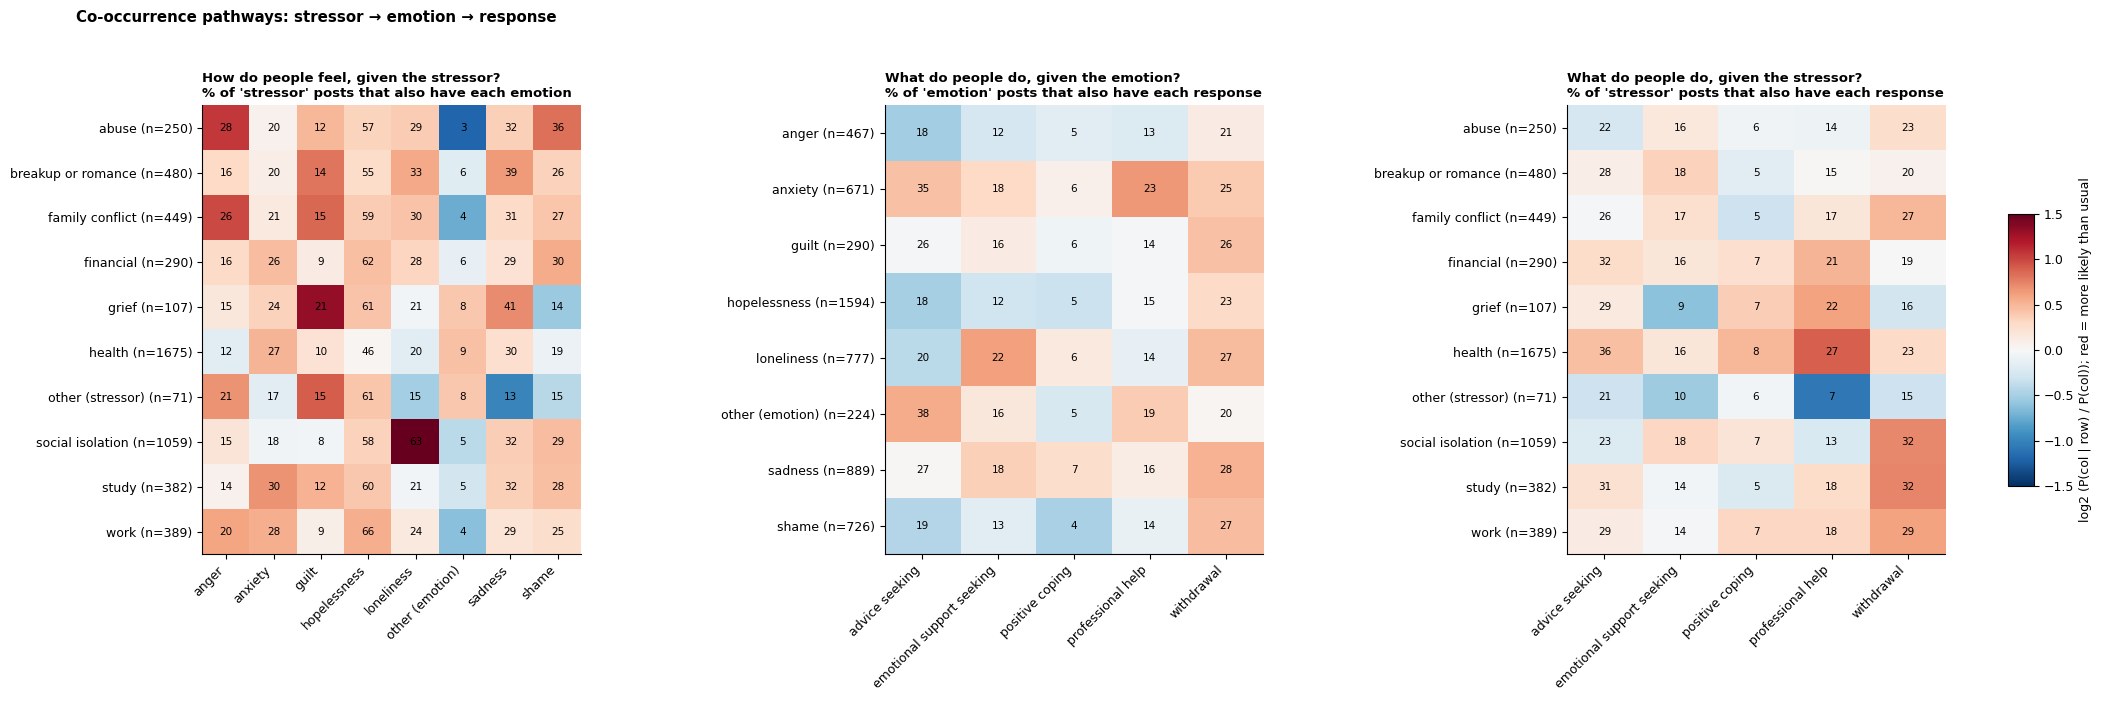

saved S02_pathways.png


In [ ]:
def cols(p): return [c for c in X.columns if c.startswith(p + ":")]
def condmat(rows_, cols_):
    P = pd.DataFrame(index=rows_, columns=cols_, dtype=float); L = P.copy()
    for a in rows_:
        for b in cols_:
            P.loc[a, b] = 100 * X.loc[X[a] == 1, b].mean(); L.loc[a, b] = np.log2((X.loc[X[a] == 1, b].mean() + 1e-9) / (X[b].mean() + 1e-9))
    return P, L
panels = [("stressor", "emotion", "How do people feel, given the stressor?"), ("emotion", "response", "What do people do, given the emotion?"), ("stressor", "response", "What do people do, given the stressor?")]
fig, axs = plt.subplots(1, 3, figsize=(21, 6.8)); fig.subplots_adjust(left=.07, right=.9, wspace=.8, bottom=.2, top=.86)
for ax, (a, b, ttl) in zip(axs, panels):
    ra = [c for c in cols(a) if X[c].sum() >= 30]; cb = cols(b)
    P, L = condmat(ra, cb); im = ax.imshow(L.values.astype(float), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_xticks(range(len(cb))); ax.set_xticklabels([short(c) for c in cb], rotation=45, ha="right"); ax.set_yticks(range(len(ra))); ax.set_yticklabels([f"{short(c)} (n={int(X[c].sum())})" for c in ra])
    for i in range(len(ra)):
        for j in range(len(cb)): ax.text(j, i, f"{P.values[i, j]:.0f}", ha="center", va="center", fontsize=7.5)
    ax.set_title(f"{ttl}\n% of '{a}' posts that also have each {b}", loc="left", fontsize=9.5)
cax = fig.add_axes([.93, .3, .012, .4]); fig.colorbar(im, cax=cax, label="log2 (P(col | row) / P(col)); red = more likely than usual")
fig.suptitle("Co-occurrence pathways: stressor → emotion → response", x=.01, ha="left", fontweight="bold", y=1.0); save_s(fig, "S02_pathways.png")

### Figure S3 – Factors that rarely occur together (Q5)
**What we get:** the pairs that appear together *less* than chance would predict (significant negative association, FDR q<0.05), with the observed vs expected number of posts having both.
**Why we did it:** knowing what does *not* go together is as informative as what does; it shows which experiences compete (people who write about one tend not to write about the other) and can reveal how the labelling scheme splits topics. Within-category pairs partly reflect that annotators pick one label.

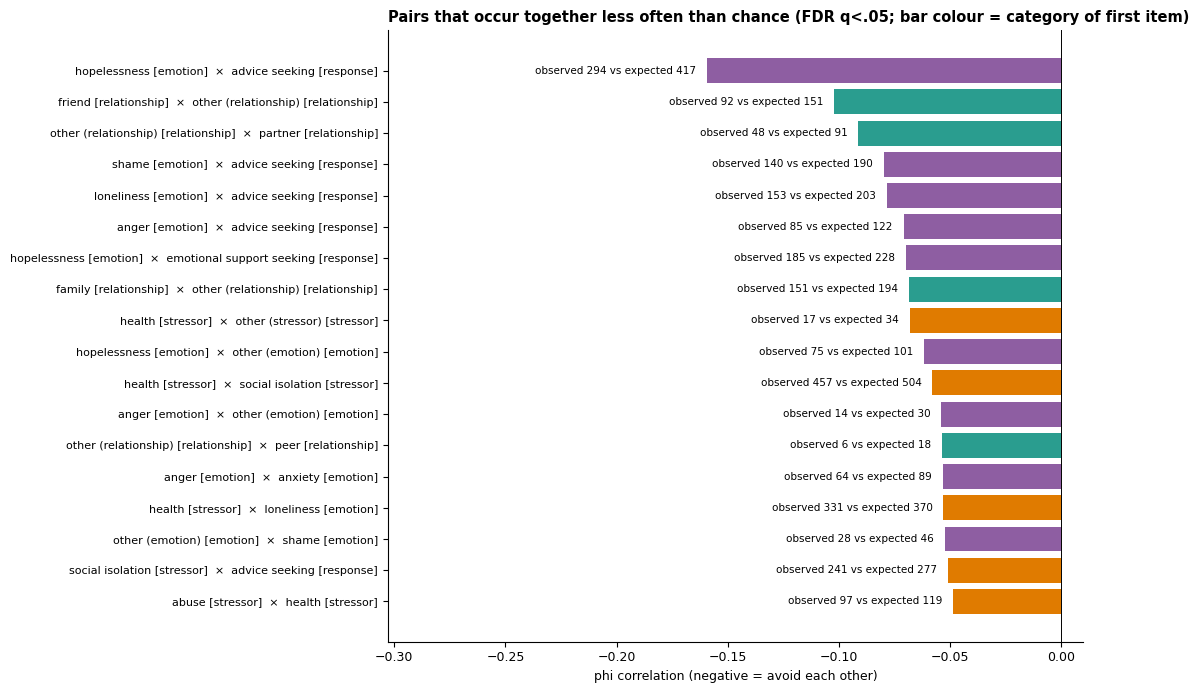

saved S03_mutually_exclusive.png


In [ ]:
pr = R["pairs"]; av = pr[(pr.direction == "avoid") & (pr.q_fdr < .05)].sort_values("phi").head(18).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(range(len(av)), av.phi, color=[CATC[cat1(a)] for a in av.item_a])
ax.set_yticks(range(len(av))); ax.set_yticklabels([f"{short(r.item_a)} [{cat1(r.item_a)}]  ×  {short(r.item_b)} [{cat1(r.item_b)}]" for r in av.itertuples()], fontsize=8)
for i, r in enumerate(av.itertuples()): ax.text(r.phi - .002, i, f"observed {r.n_both} vs expected {r.expected_both:.0f}  ", va="center", ha="right", fontsize=7.5)
ax.set_xlim(av.phi.min() * 1.9, 0.01); ax.axvline(0, color="k", lw=.7); ax.set_xlabel("phi correlation (negative = avoid each other)")
ax.set_title("Pairs that occur together less often than chance (FDR q<.05; bar colour = category of first item)", loc="left"); fig.tight_layout(); save_s(fig, "S03_mutually_exclusive.png")

### Figure S4 – Difficulty load: do posts with more problems show more belong/burden? (Q6)
**What we get:** the % of posts with thwarted belongingness and with perceived burdensomeness against the total number of labels in the post (its "load"), with Wilson CIs, and the odds ratio per extra label.
**Why we did it:** it tests whether stacking of difficulties (many stressors, emotions, responses together) is linked to TBe/PBu, a different view from asking about one factor at a time.

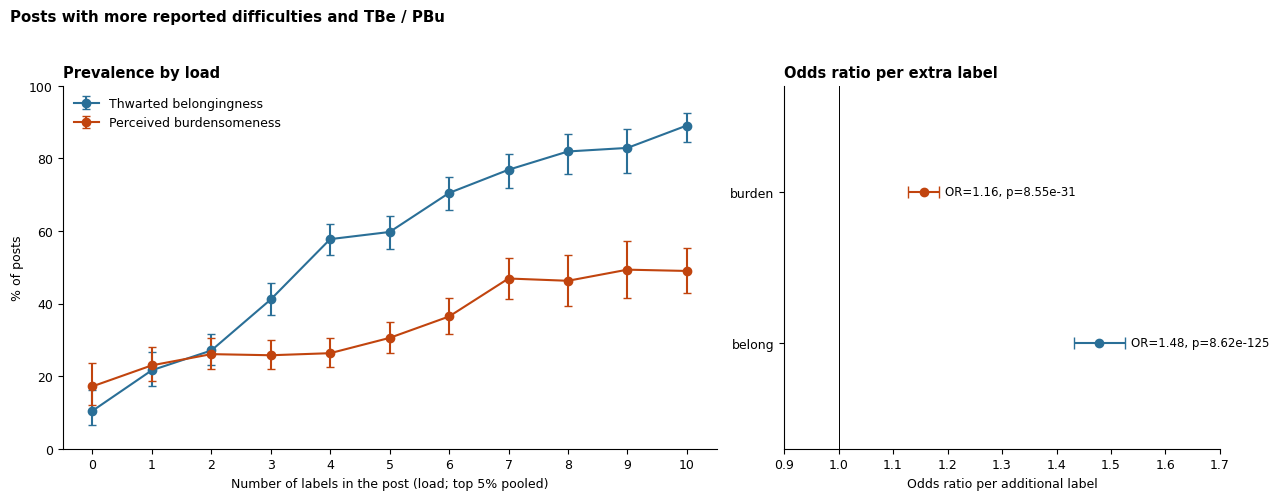

saved S04_difficulty_load.png


In [ ]:
load = cnt["n_total"].clip(upper=int(np.percentile(cnt["n_total"], 95))); lv = sorted(load.unique())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
for out, col, nm in (("belong", "#2a6f97", "Thwarted belongingness"), ("burden", "#c1440e", "Perceived burdensomeness")):
    pts = []
    for v in lv:
        m = load == v; k = int(X.loc[m, out].sum()); n = int(m.sum()); lo, hi = proportion_confint(k, n, method="wilson"); pts.append((v, 100 * k / n, 100 * lo, 100 * hi, n))
    p = np.array(pts); ax[0].errorbar(p[:, 0], p[:, 1], yerr=[p[:, 1] - p[:, 2], p[:, 3] - p[:, 1]], fmt="o-", color=col, capsize=3, label=nm)
    fit = sm.Logit(X[out].values, sm.add_constant(cnt["n_total"].values.astype(float))).fit(disp=0)
    ax[1].errorbar(np.exp(fit.params[1]), 0 if out == "belong" else 1, xerr=[[np.exp(fit.params[1]) - np.exp(fit.conf_int()[1][0])], [np.exp(fit.conf_int()[1][1]) - np.exp(fit.params[1])]], fmt="o", color=col, capsize=4)
    ax[1].text(np.exp(fit.conf_int()[1][1]) + .01, 0 if out == "belong" else 1, f"OR={np.exp(fit.params[1]):.2f}, p={fit.pvalues[1]:.3g}", va="center", fontsize=8.5)
ax[0].set_xticks(lv); ax[0].set_xlabel("Number of labels in the post (load; top 5% pooled)"); ax[0].set_ylabel("% of posts"); ax[0].set_ylim(0, 100); ax[0].legend(frameon=False); ax[0].set_title("Prevalence by load", loc="left")
ax[1].axvline(1, color="k", lw=.7); ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["belong", "burden"]); ax[1].set_xlabel("Odds ratio per additional label"); ax[1].set_xlim(.9, 1.7); ax[1].set_ylim(-.7, 1.7); ax[1].set_title("Odds ratio per extra label", loc="left")
fig.suptitle("Posts with more reported difficulties and TBe / PBu", x=.01, ha="left", fontweight="bold", y=1.03); fig.tight_layout(); save_s(fig, "S04_difficulty_load.png")

### Figure S5 – Which factors are linked to belongingness and to burdensomeness? (Q7)
**What we get:** for each of the 30 other factors, the odds ratio (with 95% CI) of that factor appearing when the post has TBe (left) and PBu (right) versus not; filled dots = FDR q<0.05.
**Why we did it:** the core clinical question: what goes along with thwarted belonging and with perceived burden? Showing both outcomes side by side reveals which factors are shared and which are specific.

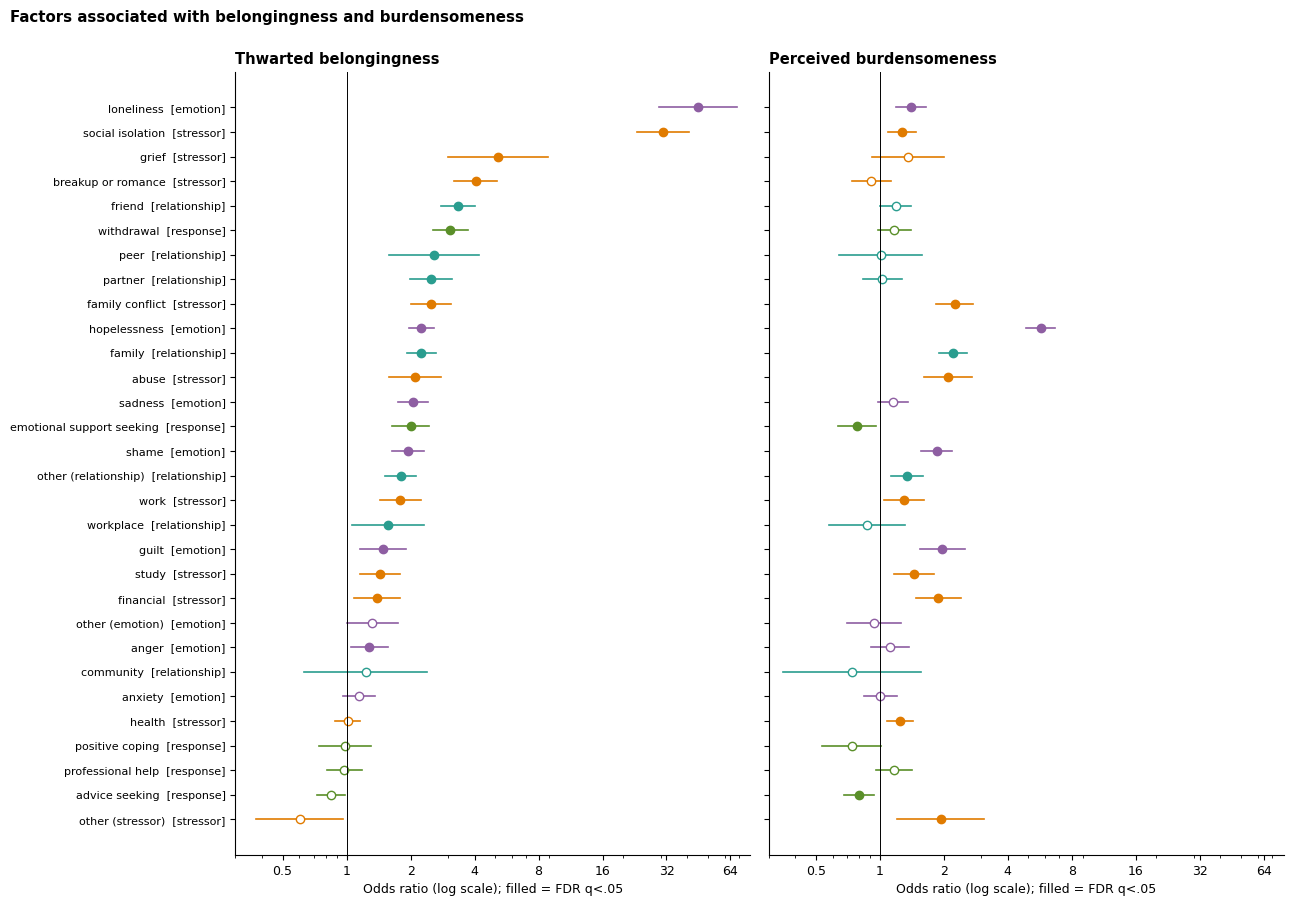

saved S05_factors_vs_belong_burden.png


In [ ]:
facs = [c for c in X.columns if c not in ("belong", "burden")]; rows = []
for out in ("belong", "burden"):
    for f_ in facs:
        t = pd.crosstab(X[f_], X[out]).reindex(index=[0, 1], columns=[0, 1], fill_value=0).values
        o, lo, hi = or_ci(t[1, 1], t[1, 0], t[0, 1], t[0, 0]); rows.append(dict(out=out, f=f_, OR=o, lo=lo, hi=hi, p=fisher_exact(t.T)[1]))
O = pd.DataFrame(rows); O["q"] = multipletests(O.p, method="fdr_bh")[1]
order_ = O[O.out == "belong"].sort_values("OR").f.tolist()
fig, axs = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
for ax, out, nm in zip(axs, ("belong", "burden"), ("Thwarted belongingness", "Perceived burdensomeness")):
    s = O[O.out == out].set_index("f").loc[order_]
    for i, (f_, r) in enumerate(s.iterrows()):
        c = CATC[cat1(f_)]; ax.plot([r.lo, r.hi], [i, i], color=c, lw=1.2)
        ax.plot(r.OR, i, "o", color=c if r.q < .05 else "white", mec=c, ms=6)
    ax.axvline(1, color="k", lw=.7); ax.set_xscale("log"); ax.set_xlim(.3, O.hi.max() * 1.15); tk = [t for t in (.5, 1, 2, 4, 8, 16, 32, 64) if t < O.hi.max() * 1.15]; ax.set_xticks(tk); ax.set_xticklabels([str(t) for t in tk]); clean_log(ax)
    ax.set_yticks(range(len(order_))); ax.set_yticklabels([f"{short(f_)}  [{cat1(f_)}]" for f_ in order_], fontsize=8); ax.set_title(nm, loc="left"); ax.set_xlabel("Odds ratio (log scale); filled = FDR q<.05")
fig.suptitle("Factors associated with belongingness and burdensomeness", x=.01, ha="left", fontweight="bold", y=1.0); fig.tight_layout(); save_s(fig, "S05_factors_vs_belong_burden.png")

### Figure S6 – What distinguishes the four groups: Neither / TBe only / PBu only / Both (Q8)
**What we get:** a heatmap of the % of posts in each of the four groups that have each factor; stars mark factors whose frequency differs across the four groups (chi-square, FDR-corrected).
**Why we did it:** TBe and PBu overlap, so a two-way view hides patterns. The four-way view shows what is specific to belonging only, burden only, or both.

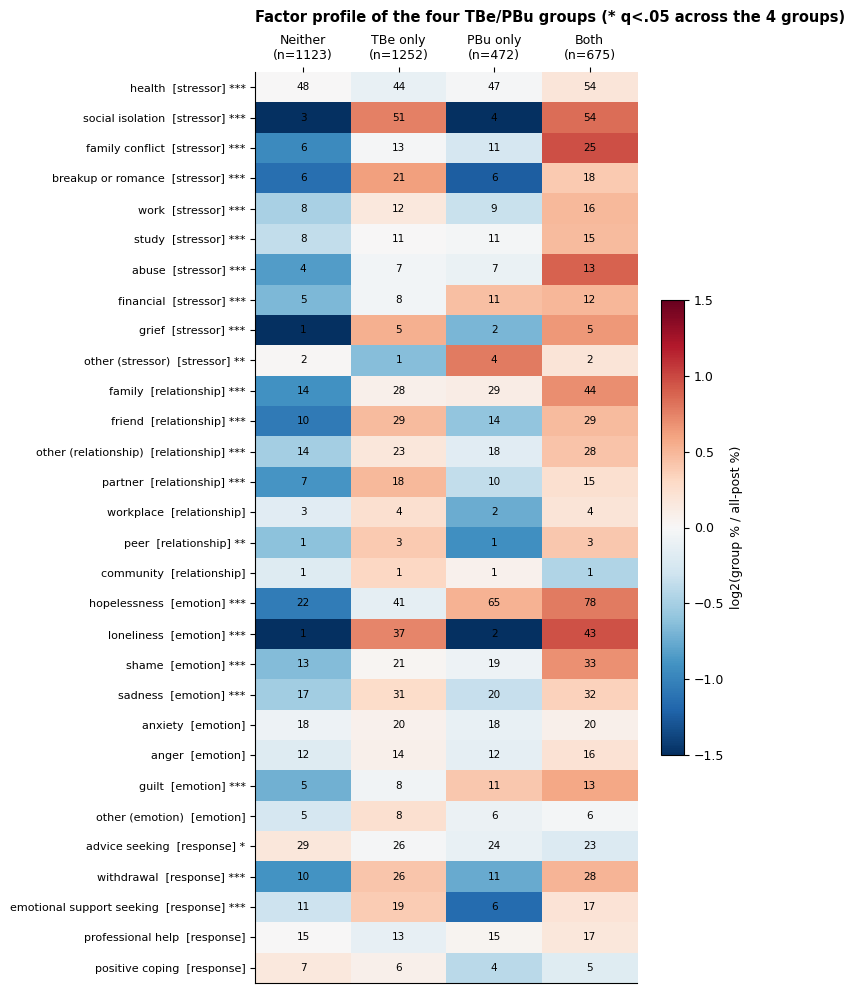

saved S06_four_group_profiles.png


In [ ]:
grp = ["Neither", "TBe only", "PBu only", "Both"]; M = pd.DataFrame({g: 100 * X.loc[d.group == g, facs].mean() for g in grp}); ns = d.group.value_counts()
pv = []
for f_ in facs:
    ct_ = pd.crosstab(d.group, X[f_]).reindex(index=grp, columns=[0, 1], fill_value=0); pv.append(chi2_contingency(ct_.values)[1])
q6 = multipletests(pv, method="fdr_bh")[1]; star = {f_: ("***" if q < .001 else "**" if q < .01 else "*" if q < .05 else "") for f_, q in zip(facs, q6)}
ordr = sorted(facs, key=lambda f_: (list(CATC).index(cat1(f_)), -M.loc[f_].max())); M = M.loc[ordr]
base = 100 * X[facs].mean().loc[ordr]; Lg = np.log2((M.values + .5) / (base.values[:, None] + .5))
fig, ax = plt.subplots(figsize=(7.5, 10)); im = ax.imshow(Lg, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels([f"{g}\n(n={ns.get(g, 0)})" for g in grp]); ax.xaxis.tick_top(); ax.set_yticks(range(len(ordr))); ax.set_yticklabels([f"{short(f_)}  [{cat1(f_)}]{' ' + star[f_] if star[f_] else ''}" for f_ in ordr], fontsize=8)
for i in range(len(ordr)):
    for j in range(4): ax.text(j, i, f"{M.values[i, j]:.0f}", ha="center", va="center", fontsize=7.5)
plt.colorbar(im, shrink=.5, label="log2(group % / all-post %)")
ax.set_title("Factor profile of the four TBe/PBu groups (* q<.05 across the 4 groups)", loc="left", pad=36); fig.tight_layout(); save_s(fig, "S06_four_group_profiles.png")

### Figure S7 – Does the age pattern differ by gender? Interaction tests (Q17)
**What we get:** for belong, burden and the four 'any label in category' indicators, the odds ratio of the *age × gender interaction* (change in the age trend for women vs men, per 5 years), with 95% CIs and p-values.
**Why we did it:** F10 only shows cell percentages. An interaction test asks formally whether the age trend differs between men and women. Only writers with both age and gender known are included, so this is **low power**: a wide CI that spans 1 means "cannot tell", not "no interaction".

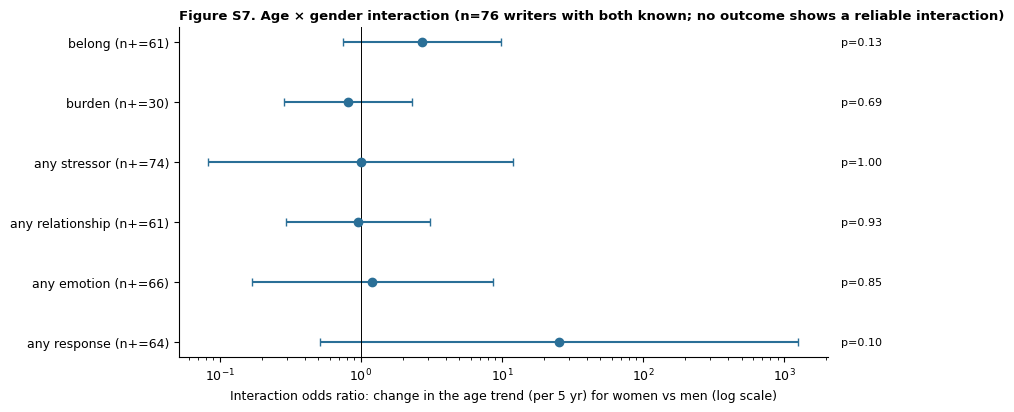

saved S07_age_gender_interaction.png


In [ ]:
bm = d.age_num.notna() & d.gender_known.isin(["Male", "Female"]); sub = d[bm]
ys = {"belong": X.loc[bm, "belong"], "burden": X.loc[bm, "burden"], **{f"any {c}": cnt.loc[bm, f"any_{c}"] for c in ("stressor", "relationship", "emotion", "response")}}
a_ = (sub.age_num.values - sub.age_num.mean()) / 5; fem = (sub.gender_known == "Female").astype(float).values
Zi = sm.add_constant(np.c_[a_, fem, a_ * fem]); rows = []
for k_, y in ys.items():
    y = y.values
    try:
        fit = sm.Logit(y, Zi).fit(disp=0, maxiter=200); b, se = fit.params[3], fit.bse[3]; rows.append((k_, np.exp(b), np.exp(b - 1.96 * se), np.exp(b + 1.96 * se), fit.pvalues[3], int(y.sum())))
    except Exception as e: rows.append((k_, np.nan, np.nan, np.nan, np.nan, int(y.sum())))
I = pd.DataFrame(rows, columns=["outcome", "OR", "lo", "hi", "p", "n_pos"])
fig, ax = plt.subplots(figsize=(9, 4.2)); yy = np.arange(len(I))[::-1]
ax.errorbar(I.OR, yy, xerr=[I.OR - I.lo, I.hi - I.OR], fmt="o", color="#2a6f97", capsize=3); ax.axvline(1, color="k", lw=.7); ax.set_xscale("log")
ax.set_yticks(yy); ax.set_yticklabels([f"{r.outcome} (n+={r.n_pos})" for r in I.itertuples()])
for y_, r in zip(yy, I.itertuples()): ax.text(1.02, y_, f"p={r.p:.2f}", transform=ax.get_yaxis_transform(), va="center", fontsize=8)
clean_log(ax); ax.set_xlabel("Interaction odds ratio: change in the age trend (per 5 yr) for women vs men (log scale)")
ax.set_title(f"Figure S7. Age × gender interaction (n={bm.sum()} writers with both known; no outcome shows a reliable interaction)" if (I.p.dropna() > .05).all() else f"Figure S7. Age × gender interaction (n={bm.sum()})", loc="left", fontsize=9.5); fig.tight_layout(); save_s(fig, "S07_age_gender_interaction.png")

### Figure S8 – Does the co-occurrence structure differ across groups? (Q19)
**What we get:** for six key pairs of factors (e.g. work stressor and burden), the phi correlation within each group (students, employed, partner mentioned, mental-health mentioned, under 18, 25+), with bootstrap 95% CIs. The dashed line is the overall value.
**Why we did it:** an association found overall may hold only for some people (for example, work stress and burden might be linked among employed people but not among students). Overlapping CIs mean the data cannot show a group difference. Groups with fewer than 40 posts are omitted.

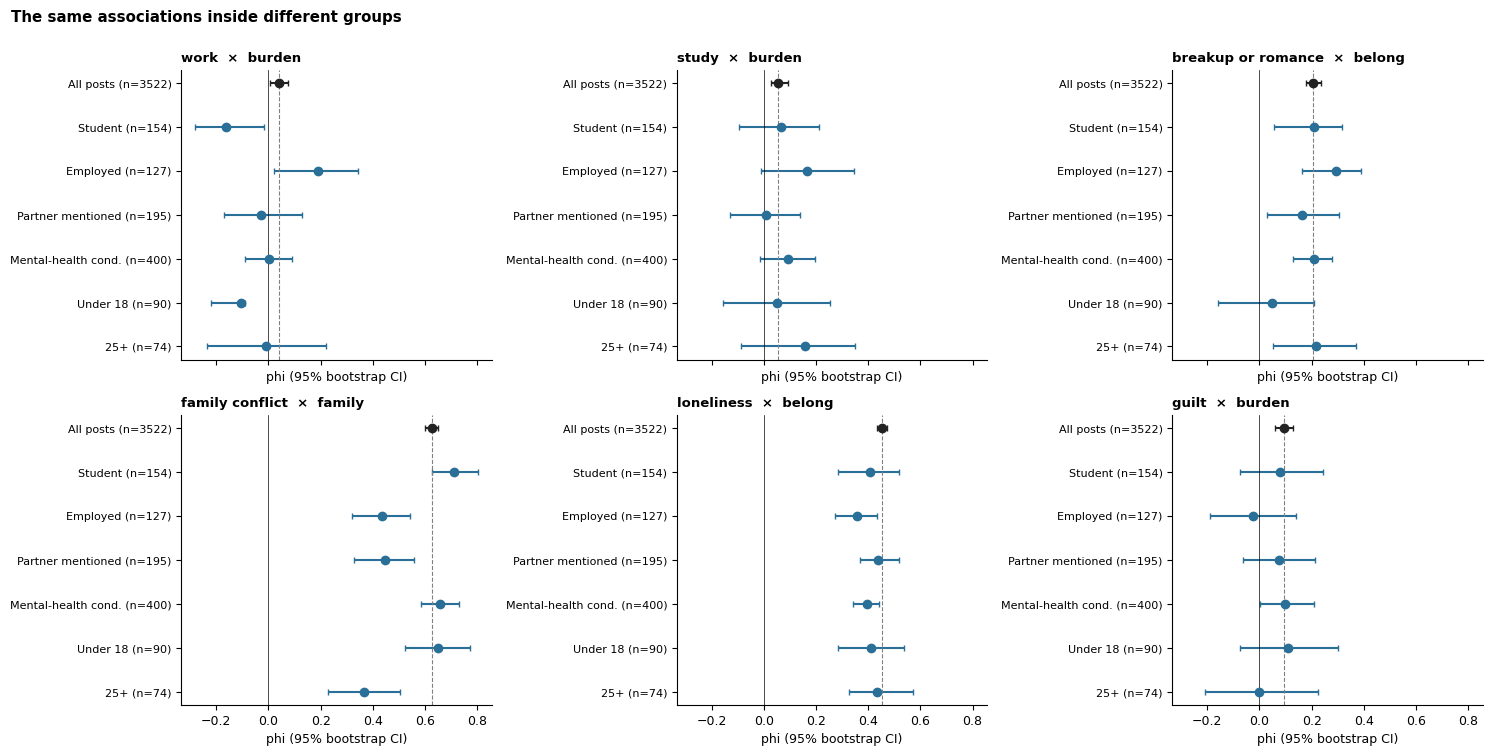

saved S08_cooccurrence_by_group.png


In [ ]:
pairs_ = [("stressor: work", "burden"), ("stressor: study", "burden"), ("stressor: breakup or romance", "belong"), ("stressor: family conflict", "relationship: family"), ("emotion: loneliness", "belong"), ("emotion: guilt", "burden")]
sets_ = {"All posts": np.ones(len(X), bool), "Student": A["Student (stated or likely)"].astype(bool).values, "Employed": A["Employed (stated or likely)"].astype(bool).values,
         "Partner mentioned": A["Partner/spouse mentioned"].astype(bool).values, "Mental-health cond.": A["Mental-health condition mentioned"].astype(bool).values,
         "Under 18": (d.age_bin == "under 18").values, "25+": (d.age_bin == "25+").values}
def phi_(x, y):
    n11 = (x & y).sum(); n10 = (x & ~y).sum(); n01 = (~x & y).sum(); n00 = (~x & ~y).sum(); den = np.sqrt(float((n11 + n10) * (n01 + n00) * (n11 + n01) * (n10 + n00)))
    return (n11 * n00 - n10 * n01) / den if den else np.nan
rng_ = np.random.default_rng(11); fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for ax, (a, b) in zip(axs.ravel(), pairs_):
    xa, xb = X[a].values.astype(bool), X[b].values.astype(bool); allphi = phi_(xa, xb); keep = [k for k, m in sets_.items() if m.sum() >= 40]
    for i, k in enumerate(keep):
        m = sets_[k]; xs, ys_ = xa[m], xb[m]; est = phi_(xs, ys_)
        bs = [phi_(xs[ix], ys_[ix]) for ix in (rng_.integers(0, m.sum(), m.sum()) for _ in range(400))]; lo, hi = np.nanpercentile(bs, [2.5, 97.5])
        ax.errorbar(est, len(keep) - 1 - i, xerr=[[est - lo], [hi - est]], fmt="o", color="#2a6f97" if k != "All posts" else "#222", capsize=2)
    ax.axvline(allphi, ls="--", color="gray", lw=.8); ax.axvline(0, color="k", lw=.5); ax.set_yticks(range(len(keep))); ax.set_yticklabels([f"{k} (n={sets_[k].sum()})" for k in keep][::-1], fontsize=8)
    ax.set_title(f"{short(a)}  ×  {short(b)}", loc="left", fontsize=9.5); ax.set_xlabel("phi (95% bootstrap CI)")
fig.suptitle("The same associations inside different groups", x=.01, ha="left", fontweight="bold", y=1.0); fig.tight_layout(); save_s(fig, "S08_cooccurrence_by_group.png")

### Figure S9 – Which demographics matter once they are adjusted for each other? (Q20)
**What we get:** odds ratios for TBe and PBu for each demographic group, unadjusted (hollow dots) and from a multivariable logistic regression including all groups together (filled dots).
**Why we did it:** the groups overlap (students are young, parents are partnered, many writers mention a mental-health condition). Adjusting shows which groups remain linked to TBe/PBu on their own. Age and gender are not included because they are known for only a small share of posts.

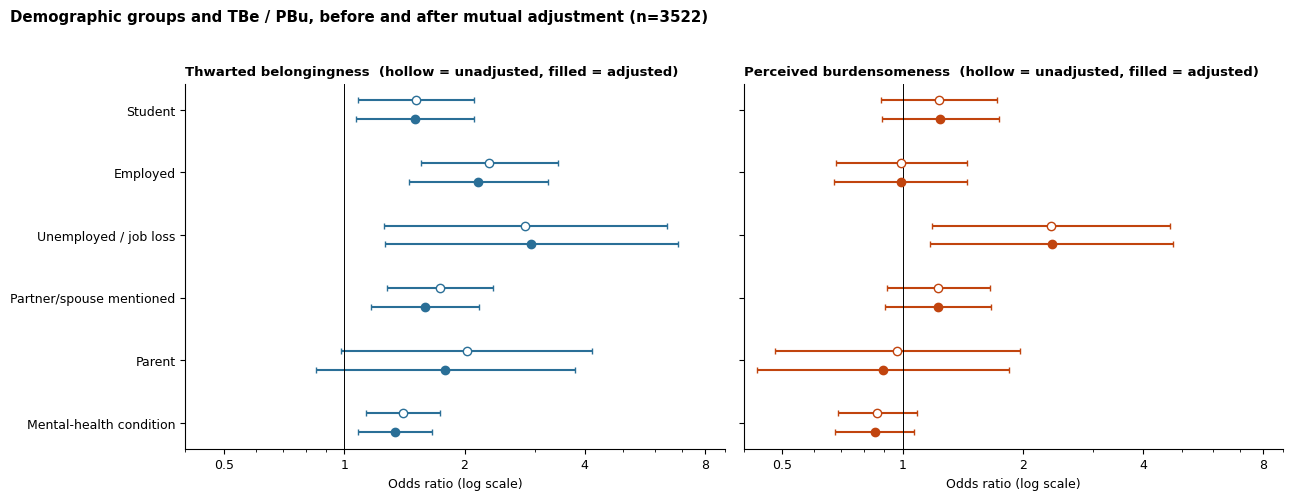

saved S09_adjusted_model.png


In [ ]:
pred_ = {"Student": "Student (stated or likely)", "Employed": "Employed (stated or likely)", "Unemployed / job loss": "Unemployed / job loss", "Partner/spouse mentioned": "Partner/spouse mentioned", "Parent": "Parent", "Mental-health condition": "Mental-health condition mentioned"}
Z9 = pd.DataFrame({k: A[v].astype(float) for k, v in pred_.items()}); rows = []
for out in ("belong", "burden"):
    y = X[out].values; fit = sm.Logit(y, sm.add_constant(Z9)).fit(disp=0); ci = np.exp(fit.conf_int())
    for k in pred_:
        t = pd.crosstab(Z9[k], y).reindex(index=[0., 1.], columns=[0, 1], fill_value=0).values; o, lo, hi = or_ci(t[1, 1], t[1, 0], t[0, 1], t[0, 0])
        rows.append(dict(out=out, g=k, kind="unadjusted", OR=o, lo=lo, hi=hi)); rows.append(dict(out=out, g=k, kind="adjusted", OR=np.exp(fit.params[k]), lo=ci.loc[k, 0], hi=ci.loc[k, 1], p=fit.pvalues[k]))
T9 = pd.DataFrame(rows); fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, out, nm in zip(axs, ("belong", "burden"), ("Thwarted belongingness", "Perceived burdensomeness")):
    for i, k in enumerate(pred_):
        for kind, off, fc in (("unadjusted", .15, "white"), ("adjusted", -.15, None)):
            r = T9[(T9.out == out) & (T9.g == k) & (T9.kind == kind)].iloc[0]; col = "#2a6f97" if out == "belong" else "#c1440e"
            ax.errorbar(r.OR, len(pred_) - 1 - i + off, xerr=[[r.OR - r.lo], [r.hi - r.OR]], fmt="o", color=col, mfc=fc if fc else col, capsize=2)
    ax.axvline(1, color="k", lw=.7); ax.set_xscale("log"); ax.set_xlim(.4, 9); ax.set_xticks([.5, 1, 2, 4, 8]); ax.set_xticklabels(["0.5", "1", "2", "4", "8"]); clean_log(ax); ax.set_yticks(range(len(pred_))); ax.set_yticklabels(list(pred_)[::-1]); ax.set_title(nm + "  (hollow = unadjusted, filled = adjusted)", loc="left", fontsize=9.5); ax.set_xlabel("Odds ratio (log scale)")
fig.suptitle(f"Demographic groups and TBe / PBu, before and after mutual adjustment (n={len(X)})", x=.01, ha="left", fontweight="bold", y=1.03); fig.tight_layout(); save_s(fig, "S09_adjusted_model.png")

### Figure S10 – Are the conclusions robust? (Q21)
**What we get:** (a) belong and burden prevalence by age group under three different age-grouping schemes, each with its permutation p-value; (b) odds ratios for TBe when a group is defined strictly (explicit self-statement) vs broadly (explicit + inferred).
**Why we did it:** results should not hinge on arbitrary choices such as where the age cut-offs fall or how loosely a group is defined. If the conclusion stays the same under reasonable alternatives, it is more trustworthy.

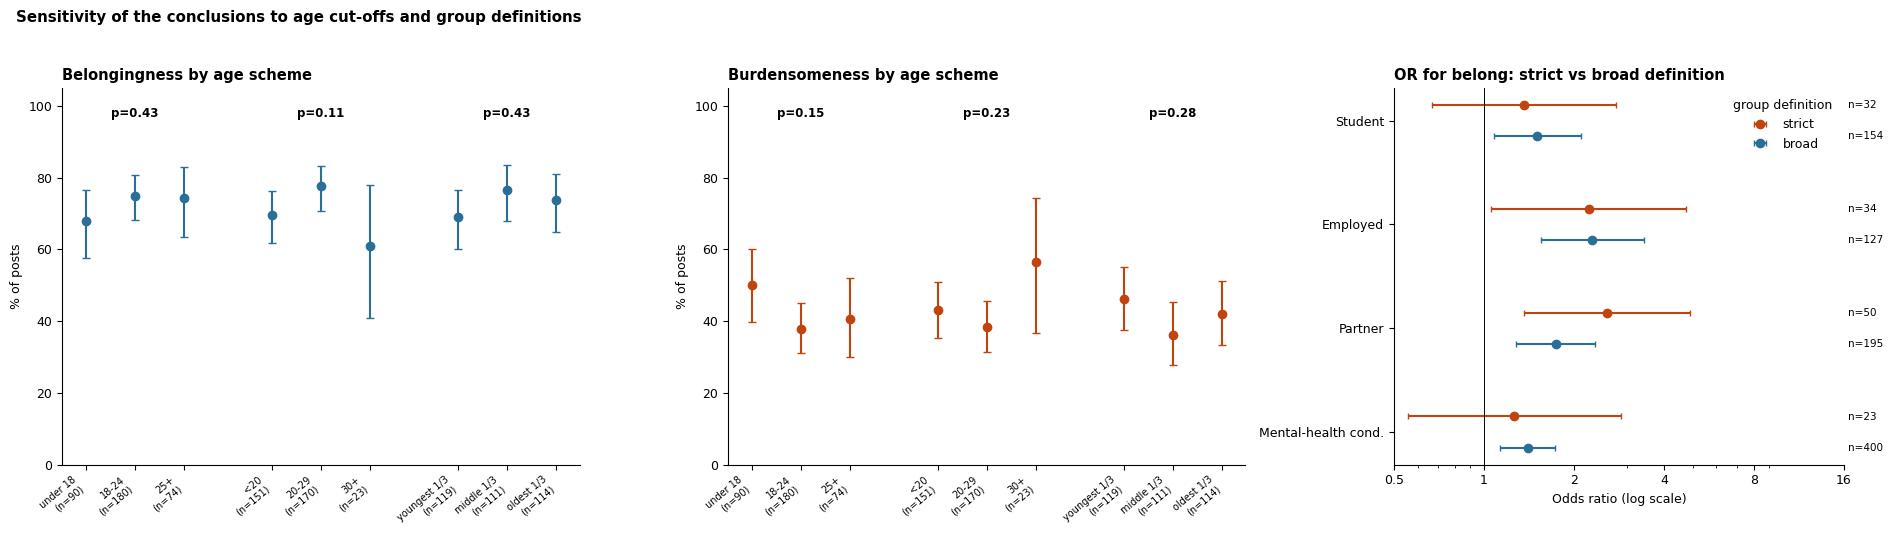

saved S10_robustness.png


In [ ]:
am_ = d.age_num.notna(); sub = d[am_]; schemes = {"<18 / 18-24 / 25+": sub.age_bin, "<20 / 20-29 / 30+": pd.cut(sub.age_num, [0, 19.99, 29.99, 99], labels=["<20", "20-29", "30+"]), "tertiles": pd.qcut(sub.age_num, 3, duplicates="drop", labels=["youngest 1/3", "middle 1/3", "oldest 1/3"]).astype(str)}
fig, axs = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={"width_ratios": [1.15, 1.15, 1]})
for ax, out, col in zip(axs[:2], ("belong", "burden"), ("#2a6f97", "#c1440e")):
    x0 = 0; ticks = []; labs = []
    for nm, g in schemes.items():
        gl = [u for u in pd.unique(g.astype(str)) if u != "nan"]; gl = sorted(gl, key=lambda u: sub.age_num[g.astype(str) == u].mean()); p = perm_chi2_p(X.loc[am_, out].values, g.astype(str).values, 3000)
        for u in gl:
            m = (g.astype(str) == u).values; k = int(X.loc[am_, out].values[m].sum()); n = int(m.sum()); lo, hi = proportion_confint(k, n, method="wilson")
            ax.errorbar(x0, 100 * k / n, yerr=[[100 * k / n - 100 * lo], [100 * hi - 100 * k / n]], fmt="o", color=col, capsize=3); ticks.append(x0); labs.append(f"{u}\n(n={n})"); x0 += 1
        ax.text(x0 - len(gl) / 2 - .5, 97, f"p={p:.2f}", ha="center", fontsize=8.5, fontweight="bold"); x0 += .8
    ax.set_xticks(ticks); ax.set_xticklabels([l.replace(" (n=", "\n(n=") for l in labs], fontsize=7, rotation=40, ha="right"); ax.set_ylim(0, 105); ax.set_ylabel("% of posts"); ax.set_title(("Belongingness" if out == "belong" else "Burdensomeness") + " by age scheme", loc="left")
defs = [("Student", "student_explicit", "Student (stated or likely)"), ("Employed", "employed_explicit", "Employed (stated or likely)"), ("Partner", "spouse_mentioned", "Partner/spouse mentioned"), ("Mental-health cond.", "mh_diagnosed", "Mental-health condition mentioned")]
for i, (nm, strict, broad) in enumerate(defs):
    for kind, off, m, col in (("strict", .15, G[strict].astype(bool), "#c1440e"), ("broad", -.15, A[broad].astype(bool), "#2a6f97")):
        t = pd.crosstab(m.values, X["belong"].values).reindex(index=[False, True], columns=[0, 1], fill_value=0).values; o, lo, hi = or_ci(t[1, 1], t[1, 0], t[0, 1], t[0, 0])
        axs[2].errorbar(o, len(defs) - 1 - i + off, xerr=[[o - lo], [hi - o]], fmt="o", color=col, capsize=2, label=f"{kind}" if i == 0 else None)
        axs[2].text(1.01, len(defs) - 1 - i + off, f"n={int(m.sum())}", transform=axs[2].get_yaxis_transform(), fontsize=7.5, va="center")
axs[2].axvline(1, color="k", lw=.7); axs[2].set_xscale("log"); clean_log(axs[2]); axs[2].set_xticks([.5, 1, 2, 4, 8, 16]); axs[2].set_xticklabels(["0.5", "1", "2", "4", "8", "16"]); axs[2].set_yticks(range(len(defs))); axs[2].set_yticklabels([x[0] for x in defs][::-1])
axs[2].legend(frameon=False, title="group definition"); axs[2].set_title("OR for belong: strict vs broad definition", loc="left"); axs[2].set_xlabel("Odds ratio (log scale)")
fig.suptitle("Sensitivity of the conclusions to age cut-offs and group definitions", x=.01, ha="left", fontweight="bold", y=1.03); fig.tight_layout(); save_s(fig, "S10_robustness.png")

### Figure S11 – Are writers who disclose demographics typical? (Q22)
**What we get:** the difference in prevalence (percentage points, disclosers minus non-disclosers) for belong, burden and every factor, for (left) writers whose age is known and (right) writers for whom any demographic was extracted from the text; filled dots = FDR q<0.05.
**Why we did it:** every age or group result is based only on people who reveal that information. If disclosers differ systematically (e.g. more relationship or school topics), conclusions cannot be generalised to all 3,522 posts. This shows how large that selection effect is.

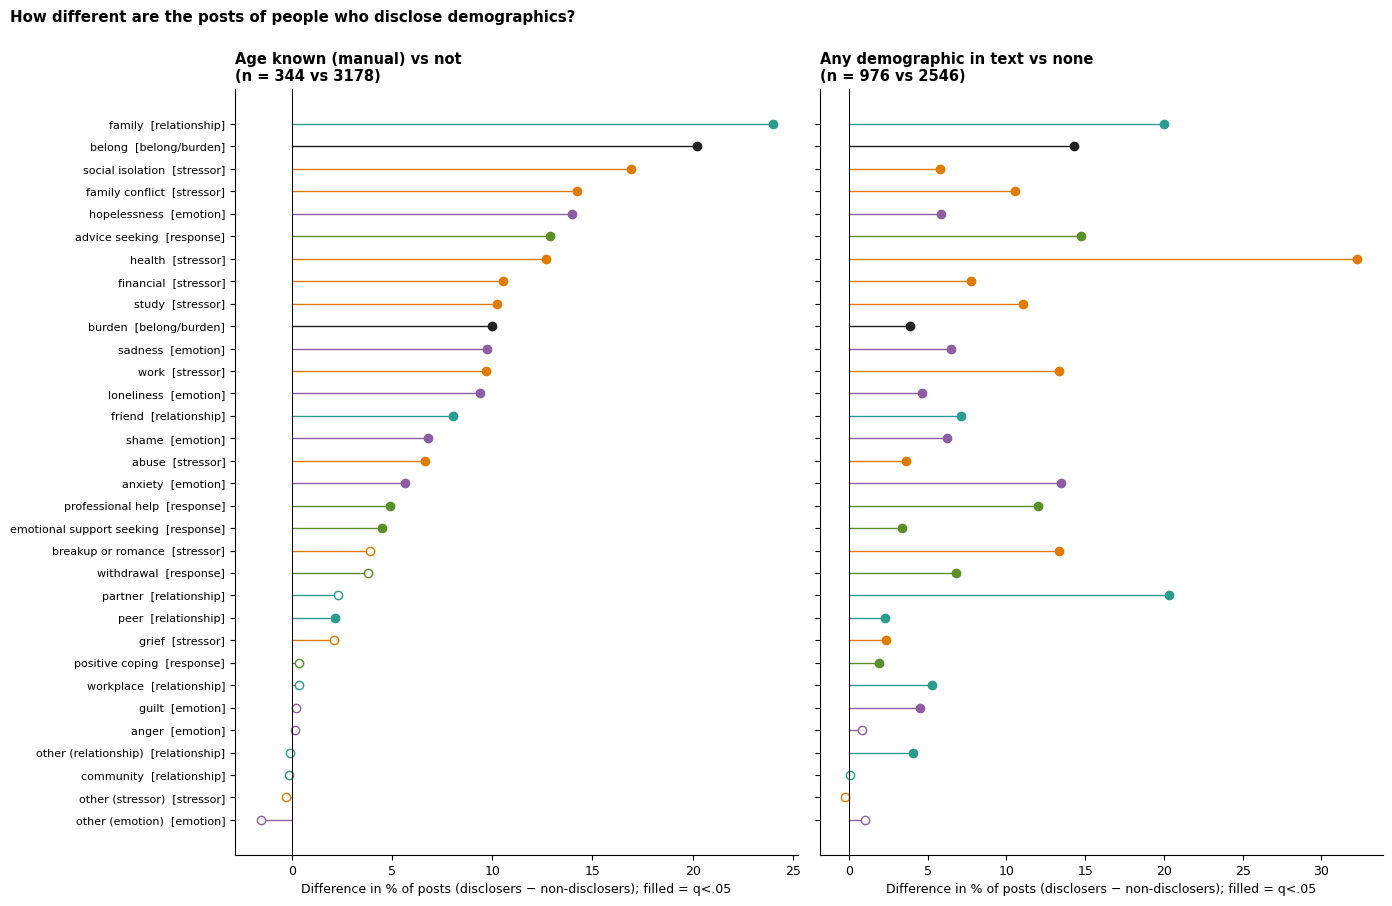

saved S11_representativeness.png


In [ ]:
anyd = (G.drop(columns=["country_stated", "orientation_stated"]).sum(axis=1) > 0) | dem.age.notna()
sets11 = {"Age known (manual) vs not": d.age_num.notna().values, "Any demographic in text vs none": anyd.values}
items11 = ["belong", "burden"] + facs; fig, axs = plt.subplots(1, 2, figsize=(14, 9), sharey=True); res11 = {}
for k_, m in sets11.items():
    rows = []
    for f_ in items11:
        a1 = int(X.loc[m, f_].sum()); n1 = int(m.sum()); a0 = int(X.loc[~m, f_].sum()); n0 = int((~m).sum()); rows.append((f_, 100 * (a1 / n1 - a0 / n0), fisher_exact([[a1, n1 - a1], [a0, n0 - a0]])[1]))
    r = pd.DataFrame(rows, columns=["f", "diff", "p"]); r["q"] = multipletests(r.p, method="fdr_bh")[1]; res11[k_] = r
ordr = res11["Age known (manual) vs not"].sort_values("diff").f.tolist()
for ax, (k_, m) in zip(axs, sets11.items()):
    r = res11[k_].set_index("f").loc[ordr]
    for i, (f_, v) in enumerate(r.iterrows()):
        c = CATC[cat1(f_)]; ax.plot([0, v["diff"]], [i, i], color=c, lw=1); ax.plot(v["diff"], i, "o", color=c if v.q < .05 else "white", mec=c, ms=6)
    ax.axvline(0, color="k", lw=.7); ax.set_yticks(range(len(ordr))); ax.set_yticklabels([f"{short(f_)}  [{cat1(f_)}]" for f_ in ordr], fontsize=8)
    ax.set_xlabel("Difference in % of posts (disclosers − non-disclosers); filled = q<.05"); ax.set_title(f"{k_}\n(n = {int(m.sum())} vs {int((~m).sum())})", loc="left")
fig.suptitle("How different are the posts of people who disclose demographics?", x=.01, ha="left", fontweight="bold", y=1.0); fig.tight_layout(); save_s(fig, "S11_representativeness.png")

## 7. Download everything

In [ ]:
import shutil, glob
print(len(glob.glob(OUT_GT + "*.png")), "age/gender figures +", len(glob.glob(OUT_DEM + "*.png")), "demographic figures +", len(glob.glob("outputs/extra/figures/*.png")), "extra-analysis figures")
shutil.make_archive("all_figures", "zip", "outputs")
try:
    from google.colab import files; files.download("all_figures.zip")
except ImportError:
    print("Saved all_figures.zip")

18 age/gender figures + 6 demographic figures + 11 extra-analysis figures


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>